# A Customer Value Index (CVI) Framework for Multi-Horizon Retail Sales Forecasting
### A leakage-aware, component-level and cross-dataset evaluation on Rossmann and Corporación Favorita

---

## 1. Research overview and hypotheses

**Research question.** Do *historical* customer-activity patterns, summarised as a store-level **Customer Value Index (CVI)** and its five behavioural components, carry predictive information for retail sales **beyond what historical sales already contain**, and does that information change with the forecast horizon, across store segments and across retailers?

The study keeps three questions apart, because a feature can be interpretable without being predictive and vice versa:

| Strand | Question | Where it is answered |
|---|---|---|
| **Predictive performance** | Does adding CVI features to a sales-only model lower out-of-sample MAE? | Sections 10–13, 15 |
| **Interpretability / behavioural profiling** | Do CVI components describe meaningful store behaviour and segments? | Sections 8, 14 |
| **Cross-dataset generalisability** | Does the pattern hold on a second retailer whose activity measure is different? | Section 17 |

### 1.1 Core experimental comparison

```
Traditional approach (Baseline, config A)          Proposed approach (CVI-enhanced, config D)
Historical sales + calendar + store features       Historical sales + calendar + store features
                                                   + five CVI components + composite CVI
            |                                                   |
  Ridge / Random Forest / LightGBM / LSTM          Ridge / Random Forest / LightGBM / LSTM
            |                                                   |
      Baseline forecast  ---- paired comparison ---->  CVI-enhanced forecast
```

Each learner is compared **against its own baseline version** trained on the same rows, split, horizon and target, so any gain is attributable to the CVI features and not to a stronger algorithm. LightGBM is the primary model for structured forecasting, and the LSTM is the deep-learning comparison.

**Improvement** is reported as $\text{Improvement}(\%) = \dfrac{\text{MAE}_{\text{baseline}}-\text{MAE}_{\text{CVI}}}{\text{MAE}_{\text{baseline}}}\times 100$. A positive value means the CVI-enhanced model reduced the error.

### 1.2 Feature configurations

| Config | Feature set | Purpose |
|---|---|---|
| **A** | Baseline: historical sales + calendar + store features | Sales-only reference |
| **B** | A + five individual CVI component scores | Component-level information |
| **C** | A + composite CVI (equal-weighted, pre-specified) | Single-index information |
| **D** | A + five components + composite CVI | **Proposed CVI-enhanced model** |
| **E** | A + raw historical customer-activity lags / rolling means (no CVI) | Is CVI better than raw activity history? |
| C-dd | A + data-driven (training-fitted) composite CVI | Weighting sensitivity (LightGBM) |
| P | A + the same recipe applied to *sales* (stability, momentum, promo uplift) | Sales-analogue control: is the information *customer*-specific? (LightGBM) |
| A+Ck | A + one component at a time | Which component is most informative? (LightGBM) |
| ORACLE | A + same-day customer activity | **Leakage diagnostic only — not deployable** |

### 1.3 Pre-specified hypotheses

All hypotheses, metrics, tests and decision rules below were fixed **before** any test-period result was produced. They are applied mechanically in Section 18 and are not edited after looking at the test results.

| | Null hypothesis (H0) | Alternative (H1) | Primary metric | Test / comparison | Supported if | Not supported / rejected if |
|---|---|---|---|---|---|---|
| **H1** Incremental value | Adding CVI features (D) does not reduce MAE relative to A | D has lower test MAE than A | Pooled test MAE (LightGBM, primary) | Paired moving-block bootstrap over dates (B reps), Holm across 4 horizons; DM test as secondary | Improvement > 0 with Holm-adjusted p < 0.05 at ≥ 3 of 4 horizons (*partially*: at 1–2 horizons) and no significant degradation | No horizon significant → not supported; significant degradation only → rejected |
| **H2** Components vs composite | The composite (C) is more informative than the components (B): MAE_B > MAE_C | MAE_B ≤ MAE_C (components equal or better) | Δ = (MAE_B − MAE_C)/MAE_A × 100 | Paired bootstrap CI of Δ; non-inferiority margin 0.5 % | Upper 95 % bound of Δ < +0.5 at all 4 horizons | Lower 95 % bound of Δ > 0 at any horizon → rejected; otherwise inconclusive |
| **H3** Horizon dependency | CVI gain is the same at short and long horizons | Gain at h = 1 exceeds gain at h = 28 | Imp(h=1) − Imp(h=28), percentage points (LightGBM D vs A) | Joint date-block bootstrap of the paired difference | 95 % CI of the difference entirely > 0 | CI entirely < 0 → rejected (opposite direction); CI contains 0 → not supported |
| **H4** Segment heterogeneity | Per-store CVI gain has the same distribution across CVI segments | Gains differ between segments | Per-store % MAE improvement (D vs A, LightGBM) | Kruskal–Wallis across segments per horizon, Holm across 4 horizons | Holm p < 0.05 at ≥ 1 horizon | Otherwise not supported |
| **H5** Cross-dataset robustness | No consistency between Rossmann and Favorita | Direction and component ranking agree | Sign of D-vs-A improvement; ranking of single-component gains | Sign agreement count; Spearman ρ of the 5 component gains | Signs agree at ≥ 3 of 4 horizons **and** ρ ≥ 0.5 | Neither holds → not supported; one holds → partially supported |
| **H6** Interpretability / profiling | CVI components do not produce a distinct, non-redundant store segmentation | They do | Silhouette; cluster profiles; ARI vs sales-only clustering | K-means on training-period store profiles | Silhouette ≥ 0.20, every cluster has a feature with \|mean z\| ≥ 0.5, **and** ARI with sales-only clustering ≤ 0.5 | Fails silhouette or profile criterion → not supported; only ARI fails → partially supported |

**Favorita caveat.** Rossmann's `Customers` is a daily customer count. Favorita's `transactions` is a daily count of store **transactions**, which serves as a *customer-activity proxy*. The two variables are not the same measurement, and H5 tests consistency of *direction*, not equality of effect.

### 1.4 How the CVI differs from existing customer analytics

* **Customer lifetime value (CLV)** is an individual-customer, forward-looking monetary value that needs customer identifiers and transaction histories. Neither dataset has those, and **nothing here estimates CLV**.
* **Customer activity features** (lagged footfall, rolling customer means) are standard inputs. Config E represents them.
* **The proposed CVI** is a *store-level, origin-anchored* behavioural index. It is built only from activity history available at the forecast origin and combines five dimensions: activity level, a spending (basket-value) proxy, stability, momentum and promotion responsiveness. It is a description of the store's recent customer behaviour, not a measure of individual customers' worth. We do not claim it is the first index of its kind, because no systematic literature review was performed here.

## 2. Imports and configuration


Set the environment variable `CVI_RUN_MODE=fast` for a quick smoke test on a sample of stores.

In [ ]:
import os, sys, json, time, math, random, platform, zipfile, hashlib, warnings, traceback, subprocess
import datetime as dt
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = os.path.exists('/kaggle/input')
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'lightgbm', 'shap'], check=False)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
import lightgbm as lgb
import torch
import torch.nn as nn
import statsmodels
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf
try:
    import shap
    HAS_SHAP = True
except Exception as _e:                       # pragma: no cover
    HAS_SHAP = False
    print('shap not importable -> LightGBM native TreeSHAP (pred_contrib) will be used:', _e)
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 80)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

In [ ]:
RUN_MODE = os.environ.get('CVI_RUN_MODE', 'full').lower()   # 'full' | 'fast'
FAST = RUN_MODE == 'fast'

DATA_SOURCES = {
    'rossmann': [os.environ.get('CVI_ROSSMANN_PATH', ''),
                 '/kaggle/input/rossmann-store-sales', '/kaggle/input/rossmann-store-sales-data',
                 '/content/data/rossmann', '/content/rossmann-store-sales.zip',
                 '/content/drive/MyDrive/cvi_data/rossmann', '/content/drive/MyDrive/cvi_data/rossmann-store-sales.zip',
                 'data/rossmann', '../data/rossmann', 'H:/downloads/rossmann-store-sales.zip'],

    'favorita': [os.environ.get('CVI_FAVORITA_PATH', ''),
                 '/kaggle/input/store-sales-time-series-forecasting', '/kaggle/input/favorita',
                 '/content/data/favorita', '/content/store-sales-time-series-forecasting.zip',
                 '/content/drive/MyDrive/cvi_data/favorita', '/content/drive/MyDrive/cvi_data/store-sales-time-series-forecasting.zip',
                 'data/favorita', '../data/favorita'],
}

# Chronological splits are defined on the TARGET date.
SPLITS = {
    'rossmann': dict(train_start='2013-05-01', train_end='2014-07-31', val_start='2014-08-01',
                     val_end='2015-01-31', test_start='2015-02-01', test_end='2015-07-31'),
    'favorita': dict(train_start='2013-05-01', train_end='2016-06-30', val_start='2016-07-01',
                     val_end='2016-12-31', test_start='2017-01-01', test_end='2017-08-15'),
}

CONFIG = dict(
    seed=42,
    run_mode=RUN_MODE,
    horizons=[1, 7, 14, 28],
    min_history=56,               # trading days of history required at the origin (all configs/models)
    out_dir=os.environ.get('CVI_OUT_DIR', '/kaggle/working/cvi_outputs' if IN_KAGGLE else 'cvi_outputs'),
    fig_dpi=300,                  # export resolution
    fast_n_stores=40,             # store sample used in fast mode (Rossmann)
    lgb=dict(n_trials=2 if FAST else 8, max_rounds=300 if FAST else 4000, tune_max_rounds=300 if FAST else 2500,
             early_stopping=50 if FAST else 100, learning_rate=0.05, num_threads=max(1, os.cpu_count() or 1)),
    rf=dict(n_estimators=20 if FAST else 100, min_samples_leaf=5, max_features=0.5, max_samples=0.25),
    ridge_alphas=[0.1, 1.0, 10.0, 100.0],
    lstm=dict(n_stores=15 if FAST else (100000 if torch.cuda.is_available() else 150), seq_len=28, hidden=64, layers=2, dropout=0.2, batch_size=1024,
              lr=1e-3, max_epochs=3 if FAST else 100, patience=10, huber_delta=0.1, run_tcn=True),
    bootstrap=dict(B=200 if FAST else 2000, sensitivity_blocks=[7, 14, 28]),
    cv_folds=1 if FAST else 3,
    perturb_n_stores=15 if FAST else 60,
    shap_rows=1000 if FAST else 4000,
)
FIG_PREFIX_ORDER = []          # filled automatically: index of all exported figures

def set_seeds(seed=CONFIG['seed']):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
set_seeds()
torch.set_num_threads(max(1, os.cpu_count() or 1))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    torch.cuda.manual_seed_all(CONFIG['seed']); torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True
print('Sequence models run on:', DEVICE)

plt.rcParams.update({'figure.dpi': 90, 'savefig.dpi': CONFIG['fig_dpi'], 'font.size': 10, 'axes.titlesize': 11,
                     'axes.titleweight': 'bold', 'axes.labelsize': 10, 'legend.fontsize': 8.5,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25})
PALETTE = {'A': '#7f7f7f', 'B': '#1f77b4', 'C': '#ff7f0e', 'D': '#2ca02c', 'E': '#9467bd',
           'C_dd': '#e377c2', 'P': '#8c564b', 'ORACLE': '#d62728'}
MODEL_COLORS = {'Ridge': '#8c8c8c', 'RandomForest': '#bcbd22', 'LightGBM': '#2ca02c', 'LSTM': '#1f77b4', 'TCN': '#17becf'}

VERSIONS = {'python': sys.version.split()[0], 'platform': platform.platform(), 'numpy': np.__version__,
            'pandas': pd.__version__, 'scikit-learn': sklearn.__version__, 'lightgbm': lgb.__version__,
            'torch': torch.__version__, 'statsmodels': statsmodels.__version__, 'scipy': __import__('scipy').__version__,
            'matplotlib': matplotlib.__version__, 'seaborn': sns.__version__,
            'shap': shap.__version__ if HAS_SHAP else 'not available', 'run_mode': RUN_MODE,
            'cpu_count': os.cpu_count(), 'cuda': torch.cuda.is_available(),
            'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None, 'kaggle': IN_KAGGLE, 'colab': IN_COLAB}
print(json.dumps(VERSIONS, indent=1))

Sequence models run on: cpu
{
 "python": "3.14.6",
 "platform": "Windows-10-10.0.19045-SP0",
 "numpy": "2.4.6",
 "pandas": "3.0.3",
 "scikit-learn": "1.9.0",
 "lightgbm": "4.7.0",
 "torch": "2.15.0+cpu",
 "statsmodels": "0.14.6",
 "scipy": "1.18.0",
 "matplotlib": "3.11.0",
 "seaborn": "0.13.2",
 "shap": "0.54.1",
 "run_mode": "full ",
 "cpu_count": 8,
 "cuda": false,
 "gpu": null,
 "kaggle": false,
 "colab": false
}


In [ ]:
EXPERIMENT_LOG = []

def log_event(dataset, stage, status, detail=''):
    """Every experiment is logged; failures are recorded with their traceback, never silently skipped."""
    EXPERIMENT_LOG.append(dict(time=dt.datetime.now().isoformat(timespec='seconds'), dataset=dataset,
                               stage=stage, status=status, detail=str(detail)[:4000]))
    print(f'[{status}] {dataset} | {stage} | {str(detail)[:300]}')

def run_step(ctx, stage, fn, *args, **kwargs):
    t0 = time.time()
    try:
        out = fn(*args, **kwargs)
        log_event(ctx['name'], stage, 'OK', f'{time.time() - t0:.1f}s')
        return out
    except Exception:
        log_event(ctx['name'], stage, 'FAILED', traceback.format_exc())
        return None

def make_context(name):
    base = Path(CONFIG['out_dir']) / name
    dirs = {k: base / k for k in ['figures', 'results', 'predictions', 'checkpoints', 'data', 'models']}
    for p in dirs.values():
        p.mkdir(parents=True, exist_ok=True)
    dirs['base'] = base
    return dict(name=name, dirs=dirs, figures=[], decisions=[], frames={}, preds={}, lstm_hist={}, model_info=[],
                splits={k: pd.Timestamp(v) for k, v in SPLITS[name].items()},
                act_label='Customers' if name == 'rossmann' else 'Transactions (activity proxy)',
                sales_label='Sales (EUR)' if name == 'rossmann' else 'Unit sales (sum of families)')

def save_fig(ctx, fig, name, caption=''):
    path = ctx['dirs']['figures'] / f"{ctx['name']}_{name}.png"
    fig.savefig(path, dpi=CONFIG['fig_dpi'], bbox_inches='tight')
    ctx['figures'].append(dict(dataset=ctx['name'], name=name, file=str(path), caption=caption))
    plt.show()
    plt.close(fig)

def decide(ctx, item, decision, rationale, count=None):
    ctx['decisions'].append(dict(dataset=ctx['name'], item=item, decision=decision, rationale=rationale,
                                 affected_rows=count))

def resolve_source(cands):
    for c in cands:
        if c and Path(c).exists():
            return str(Path(c))
    return None

def read_table(source, fname, **kw):
    """Read `fname` from a folder (plain or `fname.zip`) or from a zip archive containing it."""
    p = Path(source)
    if p.is_dir():
        for cand in [p / fname, p / (fname + '.zip')]:
            if cand.exists():
                return pd.read_csv(cand, **kw)
        raise FileNotFoundError(f'{fname} not found in {p}')
    if p.suffix.lower() == '.zip':
        with zipfile.ZipFile(p) as z:
            names = [n for n in z.namelist() if n.split('/')[-1] == fname]
            if not names:
                raise FileNotFoundError(f'{fname} not in {p}')
            with z.open(names[0]) as fh:
                return pd.read_csv(fh, **kw)
    raise FileNotFoundError(source)

def md(text):
    display(Markdown(text))

## 3. Dataset loading



In [ ]:
def load_dataset(ctx):
    src = resolve_source(DATA_SOURCES[ctx['name']])
    if src is None:
        raise FileNotFoundError(f"No data source found for {ctx['name']}; edit DATA_SOURCES. Tried: {DATA_SOURCES[ctx['name']]}")
    ctx['source'] = src
    raw = {}
    if ctx['name'] == 'rossmann':
        raw['train'] = read_table(src, 'train.csv', dtype={'StateHoliday': str}, low_memory=False)
        raw['store'] = read_table(src, 'store.csv')
    else:
        raw['train'] = read_table(src, 'train.csv', low_memory=False)
        raw['stores'] = read_table(src, 'stores.csv')
        for opt in ['transactions', 'holidays_events']:
            try:
                raw[opt] = read_table(src, f'{opt}.csv')
            except FileNotFoundError:
                raw[opt] = None
                log_event(ctx['name'], f'load {opt}.csv', 'MISSING',
                          f'{opt}.csv not available - dependent features are disabled and documented.')
    ctx['source_fingerprint'] = {k: (None if v is None else [int(v.shape[0]), int(v.shape[1]),
                                 hashlib.md5(pd.util.hash_pandas_object(v.head(5000), index=False).values).hexdigest()])
                                 for k, v in raw.items()}
    return raw

def describe_raw(raw):
    rows = []
    for k, v in raw.items():
        if v is None:
            rows.append(dict(table=k, rows=None, columns=None, dtypes='not available'))
            continue
        rows.append(dict(table=k, rows=v.shape[0], columns=v.shape[1],
                         dtypes=', '.join(f'{c}:{t}' for c, t in v.dtypes.astype(str).items())))
    return pd.DataFrame(rows)

R = make_context('rossmann')
R_raw = run_step(R, 'load', load_dataset, R)
display(describe_raw(R_raw))
display(R_raw['train'].head(3)); display(R_raw['store'].head(3))

[OK] rossmann | load | 2.0s


,table,rows,columns,dtypes
0,train,1017209,9,"Store:int64, DayOfWeek:int64, Date:str, Sales:..."
1,store,1115,10,"Store:int64, StoreType:str, Assortment:str, Co..."


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,"1,270.0000",9.0000,"2,008.0000",0,NaN,NaN,NaN
1,2,a,a,570.0000,11.0000,"2,007.0000",1,13.0000,"2,010.0000","Jan,Apr,Jul,Oct"
2,3,a,a,"14,130.0000",12.0000,"2,006.0000",1,14.0000,"2,011.0000","Jan,Apr,Jul,Oct"


## 4. Data validation



In [ ]:
def validate_rossmann(ctx, raw):
    tr, st = raw['train'].copy(), raw['store'].copy()
    tr['Date'] = pd.to_datetime(tr['Date'])
    A = []
    add = lambda k, v: A.append(dict(check=k, value=v))
    add('train shape', str(tr.shape)); add('store shape', str(st.shape))
    add('missing cells - train', int(tr.isna().sum().sum()))
    add('missing cells - store', int(st.isna().sum().sum()))
    add('duplicate (Store, Date) keys', int(tr.duplicated(['Store', 'Date']).sum()))
    add('fully duplicated rows', int(tr.duplicated().sum()))
    add('date range', f"{tr.Date.min().date()} .. {tr.Date.max().date()} ({tr.Date.nunique()} dates)")
    add('stores in train / store.csv', f'{tr.Store.nunique()} / {st.Store.nunique()}')
    add('store ids in train but not in store.csv', len(set(tr.Store) - set(st.Store)))
    add('store ids in store.csv but not in train', len(set(st.Store) - set(tr.Store)))
    add('missing store-date cells vs full grid', int(tr.Store.nunique() * tr.Date.nunique() - len(tr)))
    cnt = tr.groupby('Store').size()
    add('stores with incomplete date coverage', int((cnt < tr.Date.nunique()).sum()))
    add('negative Sales / negative Customers', f'{int((tr.Sales < 0).sum())} / {int((tr.Customers < 0).sum())}')
    add('closed days (Open=0)', int((tr.Open == 0).sum()))
    add('closed days with Sales>0', int(((tr.Open == 0) & (tr.Sales > 0)).sum()))
    add('open days with Sales=0', int(((tr.Open == 1) & (tr.Sales == 0)).sum()))
    add('open days with Customers=0', int(((tr.Open == 1) & (tr.Customers == 0)).sum()))
    add('Sales>0 but Customers=0', int(((tr.Sales > 0) & (tr.Customers == 0)).sum()))
    add('StateHoliday raw values', sorted(tr.StateHoliday.astype(str).unique().tolist()))
    add('Open values / Promo values', f'{sorted(tr.Open.unique().tolist())} / {sorted(tr.Promo.unique().tolist())}')
    miss = (st.isna().mean() * 100).round(2)
    add('store.csv missing % by column', miss[miss > 0].to_dict())
    return pd.DataFrame(A), {'train': tr.isna().mean() * 100, 'store': st.isna().mean() * 100}

def validate_favorita(ctx, raw):
    tr = raw['train'].copy()
    scol = 'unit_sales' if 'unit_sales' in tr.columns else 'sales'
    tr['date'] = pd.to_datetime(tr['date'])
    A = []
    add = lambda k, v: A.append(dict(check=k, value=v))
    add('train shape', str(tr.shape)); add('sales column used', scol)
    add('missing cells - train', tr.isna().sum().to_dict())
    add('duplicate (store, date, family) keys', int(tr.duplicated(['store_nbr', 'date', 'family']).sum()))
    add('date range', f"{tr.date.min().date()} .. {tr.date.max().date()} ({tr.date.nunique()} dates)")
    full_dates = pd.date_range(tr.date.min(), tr.date.max())
    add('calendar dates absent from train (all stores)', [str(d.date()) for d in full_dates.difference(tr.date.unique())])
    add('stores in train / stores.csv', f"{tr.store_nbr.nunique()} / {raw['stores'].store_nbr.nunique()}")
    add('store ids in train not in stores.csv', len(set(tr.store_nbr) - set(raw['stores'].store_nbr)))
    add('families', tr.family.nunique())
    add('negative sales rows', int((tr[scol] < 0).sum()))
    sd = tr.groupby(['store_nbr', 'date'])[scol].sum()
    add('store-days with total sales = 0', int((sd == 0).sum()))
    add('store-days with total sales > 0', int((sd > 0).sum()))
    miss = {'train': tr.isna().mean() * 100, 'stores': raw['stores'].isna().mean() * 100}
    tx = raw.get('transactions')
    if tx is not None:
        tx = tx.copy(); tx['date'] = pd.to_datetime(tx['date'])
        add('transactions shape', str(tx.shape))
        add('duplicate (store, date) in transactions', int(tx.duplicated(['store_nbr', 'date']).sum()))
        sdf = sd.reset_index().merge(tx, on=['store_nbr', 'date'], how='left')
        add('trading store-days with transactions missing', int(((sdf[scol] > 0) & sdf.transactions.isna()).sum()))
        add('zero-sales store-days with transactions present', int(((sdf[scol] == 0) & sdf.transactions.notna()).sum()))
        add('transactions <= 0', int((tx.transactions <= 0).sum()))
        miss['transactions'] = tx.isna().mean() * 100
    else:
        add('transactions', 'NOT AVAILABLE')
    add('holidays_events.csv', 'available' if raw.get('holidays_events') is not None else 'NOT AVAILABLE (holiday flags set to 0)')
    return pd.DataFrame(A), miss

R_audit, R_missing = run_step(R, 'validation', validate_rossmann, R, R_raw)
R['audit'] = R_audit
display(R_audit)

[OK] rossmann | validation | 1.3s


,check,value
0,train shape,"(1017209, 9)"
1,store shape,"(1115, 10)"
2,missing cells - train,0
3,missing cells - store,2343
4,"duplicate (Store, Date) keys",0
5,fully duplicated rows,0
6,date range,2013-01-01 .. 2015-07-31 (942 dates)
7,stores in train / store.csv,1115 / 1115
8,store ids in train but not in store.csv,0
9,store ids in store.csv but not in train,0


**Interpretation: data validation (Rossmann).**

* The raw file has 1,017,209 store-days for 1,115 stores, 2013-01-01 to 2015-07-31. There are no duplicate store-date keys, no negative values, and no store identifiers that are inconsistent between `train.csv` and `store.csv`.
* There are 172,817 closed days. Of the open days, 54 have zero sales (and zero customers); these are recording anomalies, not genuine zero-demand days.
* 33,121 store-date cells are missing from the full grid. Almost all belong to **180 stores with no records from July to December 2014**, the red band in Fig. 01a.
* `store.csv` lacks `CompetitionDistance` for 3 stores, plus the expected gaps in competition-open and Promo2 dates.

These checks determine the cleaning rules below. The missing block is treated as **unobserved**, never as zero sales.

## 5. Preprocessing

Both raw schemas are mapped onto one **unified daily panel**, one row per store and date:

| column | meaning |
|---|---|
| `sales` | target-eligible sales, NaN when the day is not a valid trading day |
| `activity` | customer activity: Rossmann `Customers`, Favorita `transactions` (proxy). NaN = **missing**, never silently zero |
| `trading` | valid trading day (open, positive sales, no invalid values) |
| `promo`, `promo_int` | promotion flag and intensity *planned for that day* |
| `holiday`, `school`, `hol_prev/next`, `closed_prev/next` | calendar information known in advance |

**Forecasting task definition (both datasets).** We forecast **sales on trading days**, meaning days on which the store is open and records positive sales. Closed days are known in advance from the opening schedule and would trivially be zero, so they are neither targets nor imputed zeros inside rolling windows. All rolling statistics are computed over each store's sequence of trading days.

The cell below implements the rules and records every cleaning decision with its row count.

In [ ]:
def add_neighbour_flags(daily):
    """Calendar-known flags for t-1 and t+1 (holiday; store closed). Unknown neighbours stay NaN."""
    key = daily[['store', 'date', 'holiday', 'trading']].copy()
    key['trading'] = key['trading'].astype(float)
    prev = key.copy(); prev['date'] = prev['date'] + pd.Timedelta(days=1)
    nxt = key.copy(); nxt['date'] = nxt['date'] - pd.Timedelta(days=1)
    out = daily.merge(prev.rename(columns={'holiday': 'hol_prev', 'trading': 'trd_prev'}), on=['store', 'date'], how='left')
    out = out.merge(nxt.rename(columns={'holiday': 'hol_next', 'trading': 'trd_next'}), on=['store', 'date'], how='left')
    out['closed_prev'] = 1.0 - out.pop('trd_prev')
    out['closed_next'] = 1.0 - out.pop('trd_next')
    return out

def preprocess_rossmann(ctx, raw):
    tr, st = raw['train'].copy(), raw['store'].copy()
    tr['Date'] = pd.to_datetime(tr['Date'])
    tr['StateHoliday'] = tr['StateHoliday'].astype(str).str.strip().replace({'0.0': '0', 'nan': '0'})
    n_dup = int(tr.duplicated(['Store', 'Date']).sum())
    tr = tr.drop_duplicates(['Store', 'Date'], keep='first')
    decide(ctx, 'Duplicate store-date keys', 'dropped (keep first)', 'A store-date must be unique.', n_dup)
    neg = (tr.Sales < 0) | (tr.Customers < 0)
    decide(ctx, 'Negative sales/customers', 'excluded from targets and history', 'Physically invalid.', int(neg.sum()))
    closed = tr.Open == 0
    decide(ctx, 'Closed days (Open=0)', 'not targets; excluded from rolling windows (not zero-imputed)',
           'Closures are scheduled and known in advance; forecasting task = sales on trading days.', int(closed.sum()))
    anom = (tr.Open == 1) & (tr.Sales == 0)
    decide(ctx, 'Open days with Sales=0', 'treated as recording anomalies: excluded from targets and history',
           'An open store with zero sales and (usually) zero customers is not a genuine zero-demand day.', int(anom.sum()))
    cws = closed & (tr.Sales > 0)
    decide(ctx, 'Closed days with Sales>0', 'excluded (inconsistent)', 'Contradictory record.', int(cws.sum()))
    trading = (tr.Open == 1) & (tr.Sales > 0) & ~neg
    cust_zero = trading & (tr.Customers <= 0)
    decide(ctx, 'Trading days with Customers<=0', 'activity set to NaN (missing), sales kept',
           'Distinguish missing activity from genuine zero activity.', int(cust_zero.sum()))
    n_grid = tr.Store.nunique() * tr.Date.nunique() - len(tr)
    decide(ctx, 'Missing store-date rows (incl. 180 stores without data 2014-07..2014-12)',
           'NOT imputed; treated as unobserved. Windows skip them; feature `days_since_obs` exposes staleness',
           'Absent rows are unavailable observations, not zero sales.', int(n_grid))
    daily = pd.DataFrame({
        'store': tr.Store.astype(int).values, 'date': tr.Date.values,
        'sales': tr.Sales.where(trading).astype(float).values,
        'activity': tr.Customers.where(trading & (tr.Customers > 0)).astype(float).values,
        'trading': trading.values, 'open': tr.Open.astype(int).values,
        'promo': tr.Promo.astype(int).values, 'promo_int': tr.Promo.astype(float).values,
        'holiday': (tr.StateHoliday != '0').astype(int).values, 'holiday_type': tr.StateHoliday.values,
        'school': tr.SchoolHoliday.astype(int).values,
        'sales_raw': tr.Sales.astype(float).values, 'activity_raw': tr.Customers.astype(float).values})
    daily = add_neighbour_flags(daily).sort_values(['store', 'date']).reset_index(drop=True)
    # ---- static store attributes ------------------------------------------------
    static = pd.DataFrame({'store': st.Store.astype(int)})
    static['store_type'] = st.StoreType.astype(str)
    static['assortment'] = st.Assortment.astype(str)
    static['log_comp_dist'] = np.log1p(st.CompetitionDistance)
    static['promo2'] = st.Promo2.astype(int)
    decide(ctx, 'CompetitionDistance missing', 'kept as NaN; imputed by training median inside model pipelines',
           'Imputer fitted on training rows only.', int(st.CompetitionDistance.isna().sum()))
    comp_open = pd.to_datetime(dict(year=st.CompetitionOpenSinceYear, month=st.CompetitionOpenSinceMonth, day=1), errors='coerce')
    p2 = [pd.to_datetime(f'{int(y)}-W{int(w):02d}-1', format='%G-W%V-%u') if pd.notna(y) and pd.notna(w) else pd.NaT
          for y, w in zip(st.Promo2SinceYear, st.Promo2SinceWeek)]
    mon = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'Jun': 6, 'Jul': 7, 'Aug': 8, 'Sept': 9, 'Sep': 9,
           'Oct': 10, 'Nov': 11, 'Dec': 12}
    pint = [set(mon[m] for m in str(s).split(',')) if isinstance(s, str) else set() for s in st.PromoInterval]
    ctx['ross_static_aux'] = dict(comp_open=dict(zip(st.Store.astype(int), comp_open)),
                                  p2_since=dict(zip(st.Store.astype(int), p2)),
                                  p2_months=dict(zip(st.Store.astype(int), pint)),
                                  promo2=dict(zip(st.Store.astype(int), st.Promo2.astype(int))))
    ctx['static_cat'] = ['store_type', 'assortment']
    ctx['static_num'] = ['log_comp_dist', 'promo2']
    ctx['extra_cal'] = ['comp_open_months_t', 'comp_active_t', 'promo2_active_t']
    return daily, static

def target_extras(ctx, T):
    """Target-date features that are known in advance (store master data + calendar)."""
    if ctx['name'] == 'rossmann':
        aux = ctx['ross_static_aux']
        co = T.store.map(aux['comp_open'])
        months = (T.date - co).dt.days / 30.44
        T['comp_open_months_t'] = months.clip(-1, 240)
        T['comp_active_t'] = np.where(co.isna(), np.nan, (months >= 0).astype(float))
        since = T.store.map(aux['p2_since'])
        inmon = np.array([m in aux['p2_months'][s] for s, m in zip(T.store.values, T.date.dt.month.values)])
        T['promo2_active_t'] = ((T.store.map(aux['promo2']) == 1) & (T.date >= since) & inmon).astype(float)
    else:
        T['payday_t'] = ((T.date.dt.day == 15) | T.date.dt.is_month_end).astype(float)
    return T

def preprocess_favorita(ctx, raw):
    tr = raw['train']
    scol = 'unit_sales' if 'unit_sales' in tr.columns else 'sales'
    tr = tr[['date', 'store_nbr', scol, 'onpromotion']].copy()
    tr['date'] = pd.to_datetime(tr['date'])
    tr['onpromotion'] = pd.to_numeric(tr['onpromotion'], errors='coerce').fillna(0).astype(float)
    neg = tr[scol] < 0
    decide(ctx, 'Negative family-level sales (returns)', 'clipped to 0 before store aggregation',
           'Store-level demand cannot be negative.', int(neg.sum()))
    tr[scol] = tr[scol].clip(lower=0)
    agg = tr.groupby(['store_nbr', 'date'], as_index=False).agg(sales_raw=(scol, 'sum'), promo_items=('onpromotion', 'sum'))
    stores = sorted(agg.store_nbr.unique())
    dates = pd.date_range(agg.date.min(), agg.date.max())
    grid = pd.MultiIndex.from_product([stores, dates], names=['store_nbr', 'date']).to_frame(index=False)
    g = grid.merge(agg, on=['store_nbr', 'date'], how='left')
    absent = g.sales_raw.isna()
    decide(ctx, 'Calendar dates absent for all stores (e.g. 25 Dec)', 'treated as closures (no target, no history)',
           'Absent for every store means the chain was closed, not missing data.', int(absent.sum()))
    zero = g.sales_raw.fillna(0) == 0
    decide(ctx, 'Store-days with total sales = 0', 'treated as non-trading days (pre-opening / temporary closure)',
           'A store selling nothing across all families is closed; zero sales are not imputed into windows.', int((zero & ~absent).sum()))
    g['trading'] = (g.sales_raw > 0)
    tx = raw.get('transactions')
    if tx is not None:
        tx = tx.copy(); tx['date'] = pd.to_datetime(tx['date'])
        tx = tx.drop_duplicates(['store_nbr', 'date'])
        g = g.merge(tx, on=['store_nbr', 'date'], how='left')
        miss_act = g.trading & g.transactions.isna()
        decide(ctx, 'Trading days without transactions record', 'activity = NaN (missing), sales kept',
               'Missing activity is not zero activity.', int(miss_act.sum()))
        g['activity'] = g.transactions.where(g.trading & (g.transactions > 0))
    else:
        g['activity'] = np.nan
        decide(ctx, 'transactions.csv unavailable', 'all activity NaN -> CVI cannot be computed', 'Logged failure.', None)
    g = g.sort_values(['store_nbr', 'date']).reset_index(drop=True)
    # planned promotion intensity is known in advance (as in the Kaggle test file). Binary 'promo day' =
    # intensity above the store's trailing 28-day median computed strictly from the past.
    pi = g.promo_items.fillna(0)
    med = pi.groupby(g.store_nbr).transform(lambda x: x.shift(1).rolling(28, min_periods=7).median())
    g['promo'] = ((pi > med.fillna(np.inf)) & (pi > 0)).astype(int)
    decide(ctx, 'Promotion flag (Favorita has item counts, no store flag)',
           'promo=1 if planned on-promotion item count > store trailing-28-day median (past only)',
           'Converts counts to a store-relative promo day; uses only information before the day.', int(g.promo.sum()))
    hol = np.zeros(len(g))
    he = raw.get('holidays_events')
    if he is not None:
        he = he.copy(); he['date'] = pd.to_datetime(he['date'])
        he = he[(he.transferred.astype(str).str.lower() != 'true') & (he.type != 'Work Day')]
        st = raw['stores'].set_index('store_nbr')
        nat = set(he.loc[he.locale == 'National', 'date'])
        reg = set(zip(he.loc[he.locale == 'Regional', 'date'], he.loc[he.locale == 'Regional', 'locale_name']))
        loc = set(zip(he.loc[he.locale == 'Local', 'date'], he.loc[he.locale == 'Local', 'locale_name']))
        stt, cty = g.store_nbr.map(st['state']), g.store_nbr.map(st['city'])
        hol = np.array([(d in nat) or ((d, s) in reg) or ((d, c) in loc) for d, s, c in zip(g.date, stt, cty)]).astype(int)
    else:
        decide(ctx, 'holidays_events.csv unavailable', 'holiday flags = 0 (calendar month/day features still present)',
               'File not provided; documented limitation.', None)
    daily = pd.DataFrame({'store': g.store_nbr.astype(int), 'date': g.date,
                          'sales': g.sales_raw.where(g.trading).astype(float), 'activity': g.activity.astype(float),
                          'trading': g.trading.astype(bool), 'open': g.trading.astype(int), 'promo': g.promo.astype(int),
                          'promo_int': np.log1p(pi).astype(float), 'holiday': hol, 'holiday_type': np.where(hol == 1, 'h', '0'),
                          'school': 0, 'sales_raw': g.sales_raw.astype(float),
                          'activity_raw': g.get('transactions', pd.Series(np.nan, index=g.index)).astype(float)})
    daily = add_neighbour_flags(daily).sort_values(['store', 'date']).reset_index(drop=True)
    stt = raw['stores'].copy()
    static = pd.DataFrame({'store': stt.store_nbr.astype(int), 'store_type': stt['type'].astype(str),
                           'cluster': stt['cluster'].astype(str)})
    ctx['static_cat'] = ['store_type', 'cluster']
    ctx['static_num'] = []
    ctx['extra_cal'] = ['payday_t']
    return daily, static

def preprocess(ctx, raw):
    daily, static = (preprocess_rossmann if ctx['name'] == 'rossmann' else preprocess_favorita)(ctx, raw)
    if FAST and ctx['name'] == 'rossmann':
        keep = np.random.RandomState(CONFIG['seed']).choice(daily.store.unique(), CONFIG['fast_n_stores'], replace=False)
        daily = daily[daily.store.isin(keep)].reset_index(drop=True)
        static = static[static.store.isin(keep)].reset_index(drop=True)
        decide(ctx, 'FAST MODE', f'random sample of {len(keep)} stores', 'Smoke test only - not research results.', None)
    for c in ctx['static_cat']:   # integer codes for tree models (static master data, not learned from targets)
        static[c + '_code'] = static[c].astype('category').cat.codes.astype(float)
    daily['dow'] = daily.date.dt.dayofweek
    ctx['daily'], ctx['static'] = daily, static
    # ---- robust outlier screen on trading days (flag only, retained) --------------
    td = daily[daily.trading].copy()
    ls = np.log(td.sales)
    med = ls.groupby(td.store).transform('median')
    mad = (ls - med).abs().groupby(td.store).transform('median') * 1.4826
    td['robust_z'] = (ls - med) / mad.replace(0, np.nan)
    n_out = int((td.robust_z.abs() > 4).sum())
    decide(ctx, 'Sales outliers (|robust z of log sales| > 4 within store)',
           'flagged but retained (no winsorising of the target)',
           'Extreme days are mostly genuine (pre-holiday peaks, reopenings); removing them would flatter test metrics.', n_out)
    ctx['outlier_z'] = td[['store', 'date', 'sales', 'robust_z']]
    return daily

R_daily = run_step(R, 'preprocess', preprocess, R, R_raw)
R_dec = pd.DataFrame(R['decisions'])
display(R_dec)
print('trading store-days:', int(R_daily.trading.sum()), '| stores:', R_daily.store.nunique(),
      '| activity missing on trading days:', int(R_daily.loc[R_daily.trading, 'activity'].isna().sum()))

[OK] rossmann | preprocess | 2.6s


,dataset,item,decision,rationale,affected_rows
0,rossmann,Duplicate store-date keys,dropped (keep first),A store-date must be unique.,0
1,rossmann,Negative sales/customers,excluded from targets and history,Physically invalid.,0
2,rossmann,Closed days (Open=0),not targets; excluded from rolling windows (no...,Closures are scheduled and known in advance; f...,172817
3,rossmann,Open days with Sales=0,treated as recording anomalies: excluded from ...,An open store with zero sales and (usually) ze...,54
4,rossmann,Closed days with Sales>0,excluded (inconsistent),Contradictory record.,0
5,rossmann,Trading days with Customers<=0,"activity set to NaN (missing), sales kept",Distinguish missing activity from genuine zero...,0
6,rossmann,Missing store-date rows (incl. 180 stores with...,NOT imputed; treated as unobserved. Windows sk...,"Absent rows are unavailable observations, not ...",33121
7,rossmann,CompetitionDistance missing,kept as NaN; imputed by training median inside...,Imputer fitted on training rows only.,3
8,rossmann,Sales outliers (|robust z of log sales| > 4 wi...,flagged but retained (no winsorising of the ta...,Extreme days are mostly genuine (pre-holiday p...,1364


trading store-days: 844338 | stores: 1115 | activity missing on trading days: 0


**Interpretation: preprocessing decisions.**

* The forecasting task is **sales on trading days**: 844,338 store-days with the store open and sales > 0.
* Closed days and the 54 open-zero anomalies are excluded from both the targets and the rolling windows, so closures cannot pull rolling means towards zero.
* No trading day has missing customer counts on Rossmann, so the distinction between missing and zero activity matters only for Favorita (Section 17).
* 1,364 within-store extreme days (|robust z| > 4) are flagged but **kept**. They are mostly genuine pre-holiday peaks and reopenings, and deleting them would make the test metrics look better than they are.

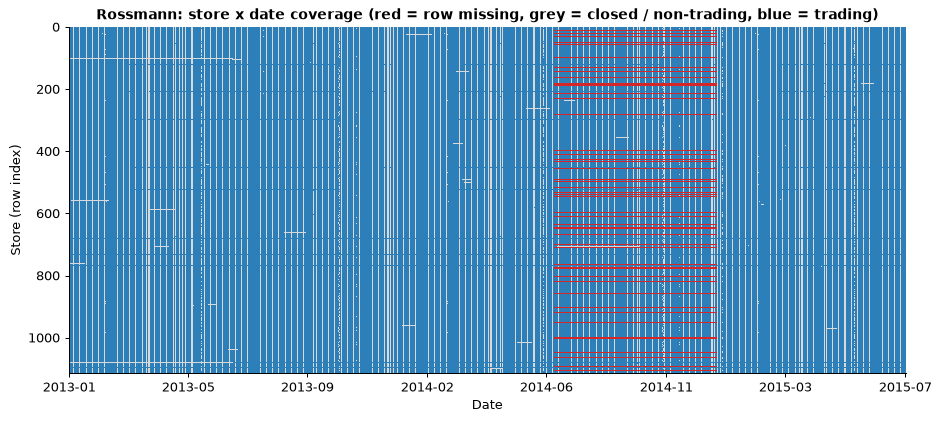

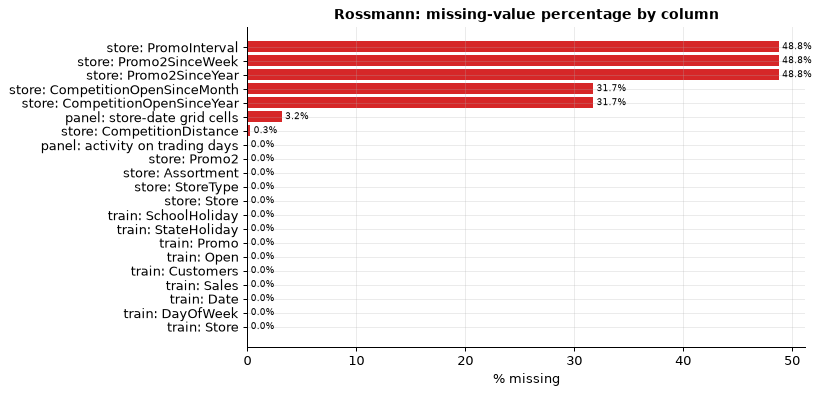

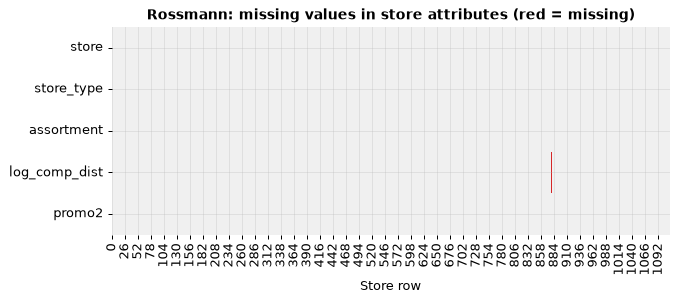

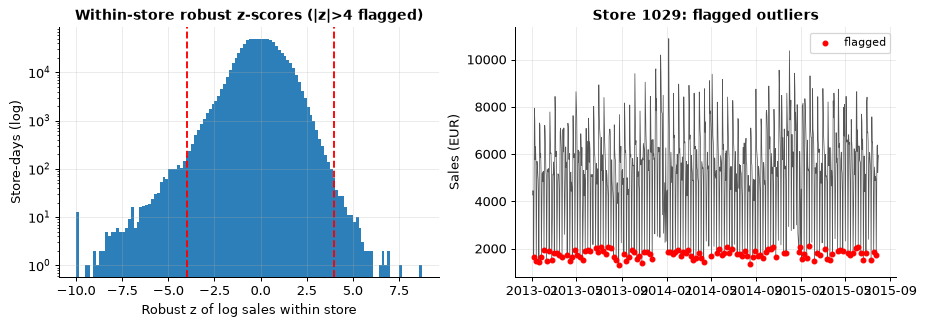

[OK] rossmann | data-quality figures | 8.5s


In [ ]:
def plot_data_quality(ctx, missing_pct):
    d = ctx['daily']
    # (1) coverage heatmap: missing row / non-trading / trading
    piv = d.assign(v=np.where(d.trading, 2, 1)).pivot_table(index='store', columns='date', values='v', aggfunc='max')
    full = pd.date_range(d.date.min(), d.date.max())
    piv = piv.reindex(columns=full).fillna(0)
    fig, ax = plt.subplots(figsize=(12, 5))
    cmap = matplotlib.colors.ListedColormap(['#d62728', '#d9d9d9', '#2c7fb8'])
    ax.imshow(piv.values, aspect='auto', interpolation='nearest', cmap=cmap, vmin=0, vmax=2)
    tick = np.linspace(0, len(full) - 1, 8).astype(int)
    ax.set_xticks(tick); ax.set_xticklabels([full[i].strftime('%Y-%m') for i in tick])
    ax.set_xlabel('Date'); ax.set_ylabel('Store (row index)')
    ax.set_title(f"{ctx['name'].title()}: store x date coverage (red = row missing, grey = closed / non-trading, blue = trading)")
    ax.grid(False)
    save_fig(ctx, fig, 'fig01a_missing_heatmap_grid', 'Store-date coverage heatmap.')
    # (2) missing-value percentage per column
    rows = [(t, c, v) for t, s in missing_pct.items() for c, v in s.items()]
    mp = pd.DataFrame(rows, columns=['table', 'column', 'pct'])
    mp = pd.concat([mp, pd.DataFrame([('panel', 'activity on trading days',
                                       d.loc[d.trading, 'activity'].isna().mean() * 100),
                                      ('panel', 'store-date grid cells', (piv.values == 0).mean() * 100)],
                                     columns=mp.columns)])
    mp['label'] = mp.table + ': ' + mp.column
    mp = mp.sort_values('pct')
    fig, ax = plt.subplots(figsize=(8, max(3, 0.22 * len(mp))))
    ax.barh(mp.label, mp.pct, color=np.where(mp.pct > 0, '#d62728', '#bdbdbd'))
    for y, v in enumerate(mp.pct):
        ax.text(v + 0.3, y, f'{v:.1f}%', va='center', fontsize=7)
    ax.set_xlabel('% missing'); ax.set_title(f"{ctx['name'].title()}: missing-value percentage by column")
    save_fig(ctx, fig, 'fig01b_missing_pct', 'Missing-value percentages.')
    # (3) mask heatmap of the static table
    st = ctx['static'][[c for c in ctx['static'].columns if not c.endswith('_code')]]
    fig, ax = plt.subplots(figsize=(8, 3))
    sns.heatmap(st.isna().T, cbar=False, cmap=['#f0f0f0', '#d62728'], ax=ax)
    ax.set_title(f"{ctx['name'].title()}: missing values in store attributes (red = missing)"); ax.set_xlabel('Store row')
    save_fig(ctx, fig, 'fig01c_missing_store_attrs', 'Store attribute missingness.')
    # (4) outliers
    oz = ctx['outlier_z']
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
    axs[0].hist(oz.robust_z.clip(-10, 10).dropna(), bins=120, color='#2c7fb8')
    axs[0].axvline(4, color='r', ls='--'); axs[0].axvline(-4, color='r', ls='--')
    axs[0].set_yscale('log'); axs[0].set_xlabel('Robust z of log sales within store'); axs[0].set_ylabel('Store-days (log)')
    axs[0].set_title('Within-store robust z-scores (|z|>4 flagged)')
    s0 = oz.groupby('store').robust_z.apply(lambda z: (z.abs() > 4).sum()).idxmax()
    e = oz[oz.store == s0]
    axs[1].plot(e.date, e.sales, lw=0.6, color='#555')
    f = e[e.robust_z.abs() > 4]
    axs[1].scatter(f.date, f.sales, color='r', s=14, zorder=3, label='flagged')
    axs[1].set_title(f'Store {s0}: flagged outliers'); axs[1].set_ylabel(ctx['sales_label']); axs[1].legend()
    save_fig(ctx, fig, 'fig01d_outliers', 'Outlier screen.')

run_step(R, 'data-quality figures', plot_data_quality, R, R_missing)

**Interpretation: missingness and outliers.**

* The coverage heatmap (Fig. 01a) shows that missingness is **structural, not random**: one contiguous six-month block for 180 stores. This is why the features include `days_since_obs`. When those stores reappear in January 2015, their history windows reach back across the gap, and the model needs to know that the information is stale.
* The column-missingness chart (Fig. 01b) confirms that the target and activity variables are complete. Only the store master data has gaps.
* The outlier screen (Fig. 01d) shows isolated spikes rather than corrupted series.

## 6. Exploratory data analysis



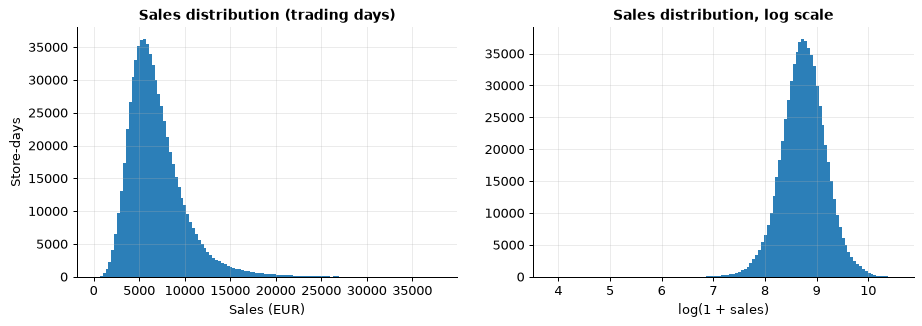

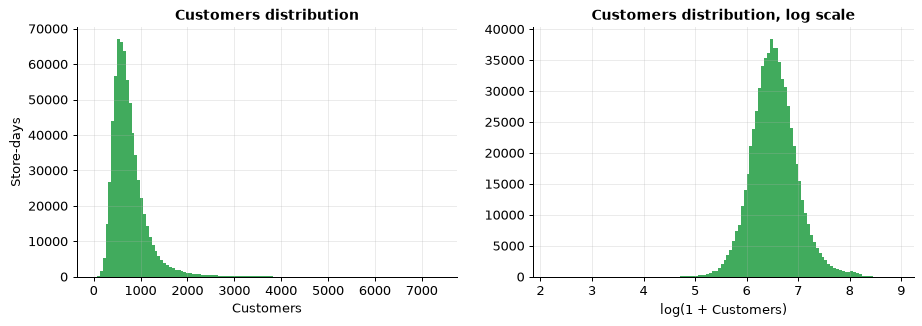

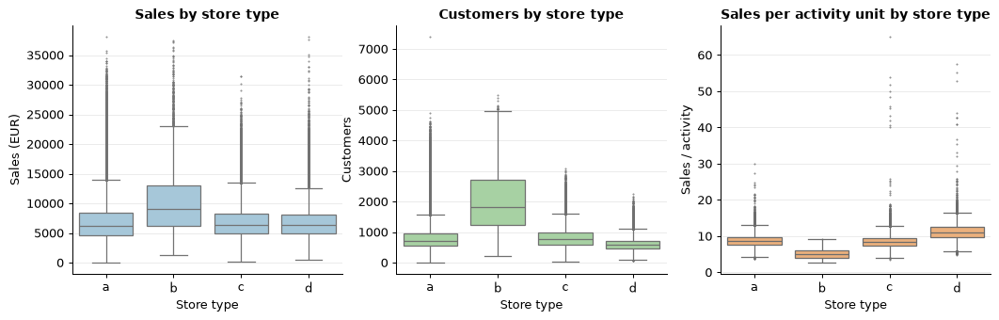

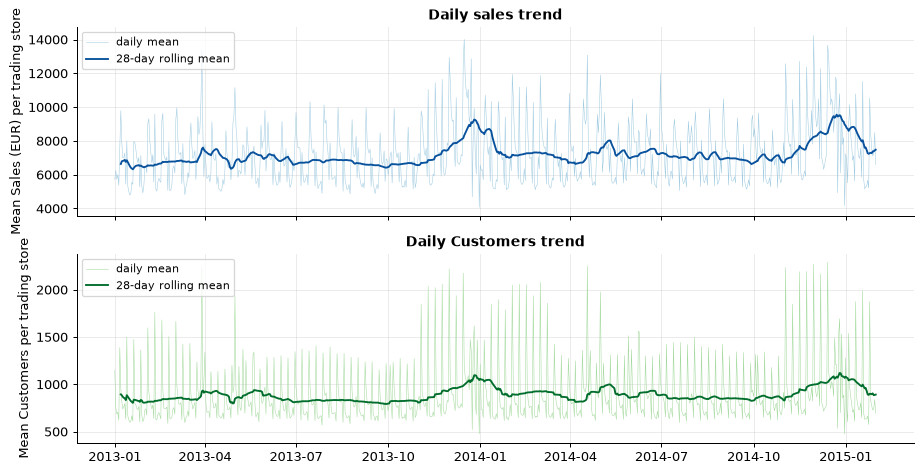

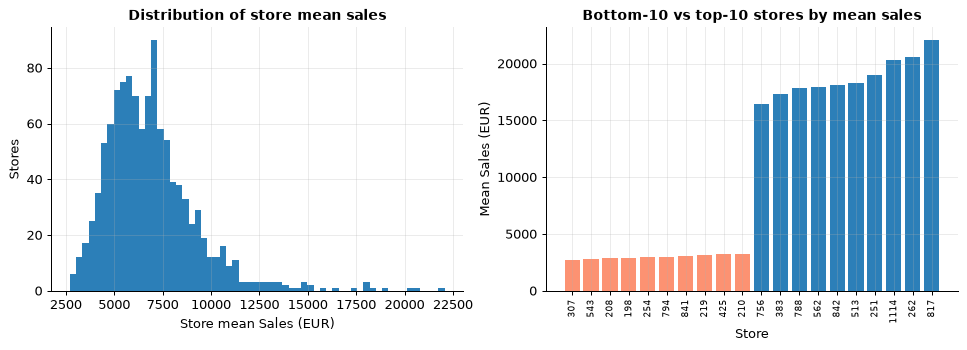

[OK] rossmann | EDA overview | 10.7s


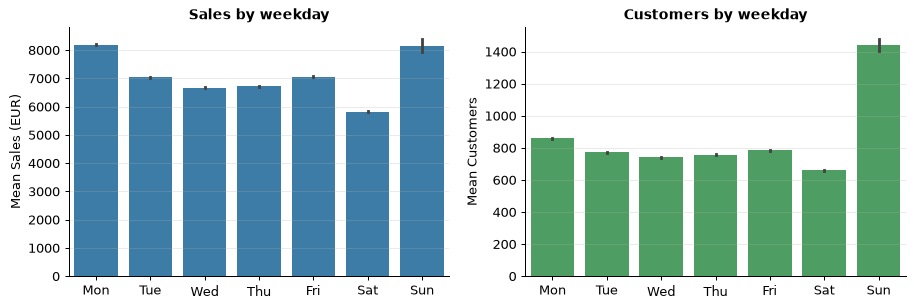

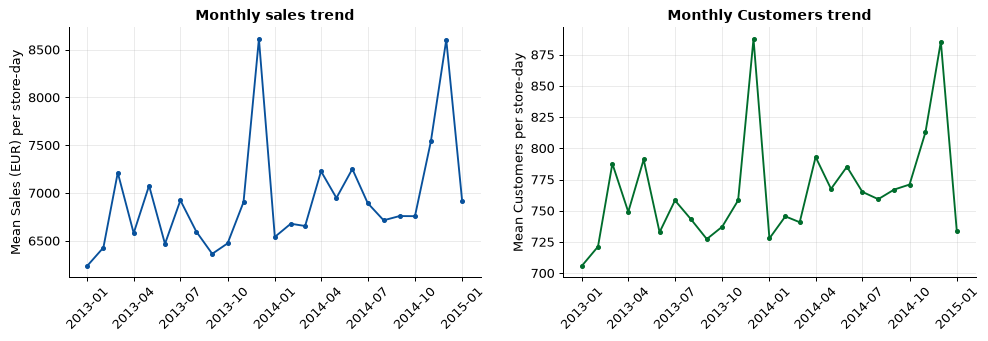

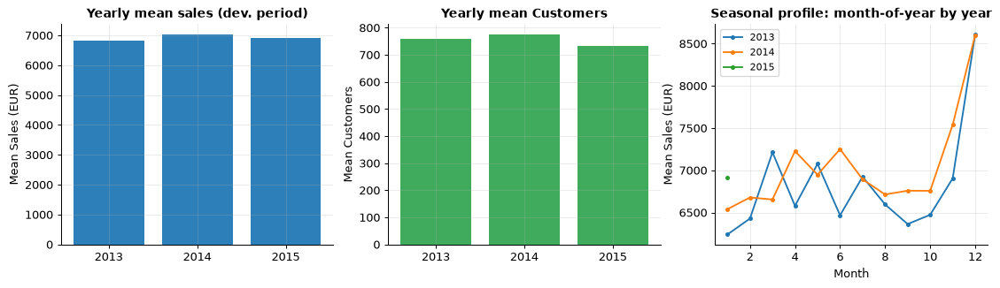

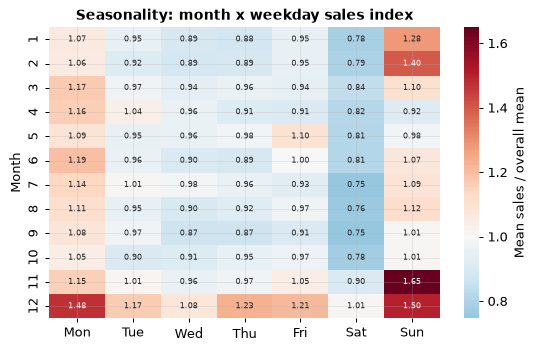

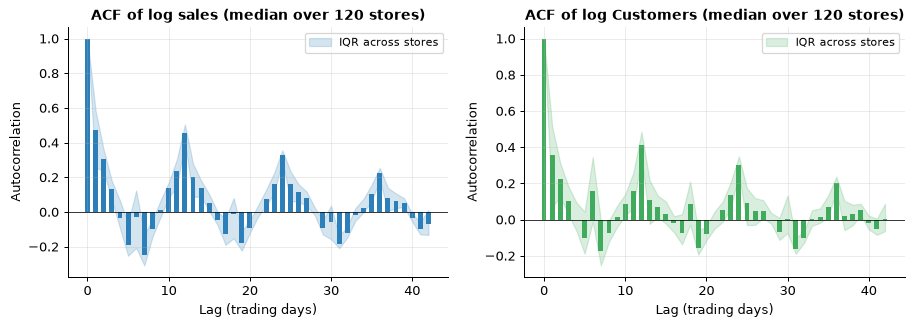

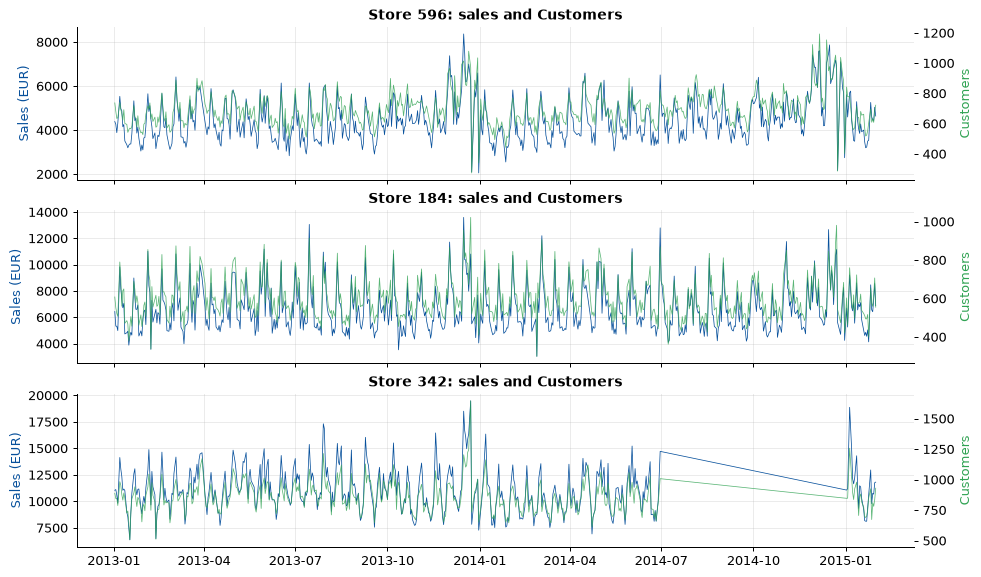

[OK] rossmann | EDA temporal | 14.6s


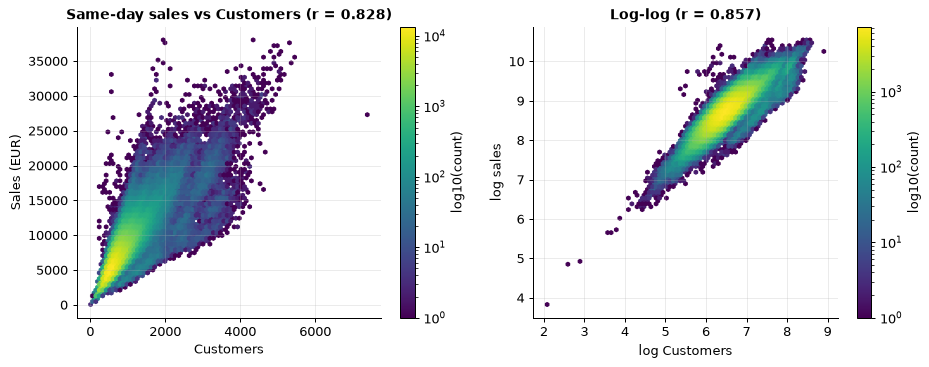

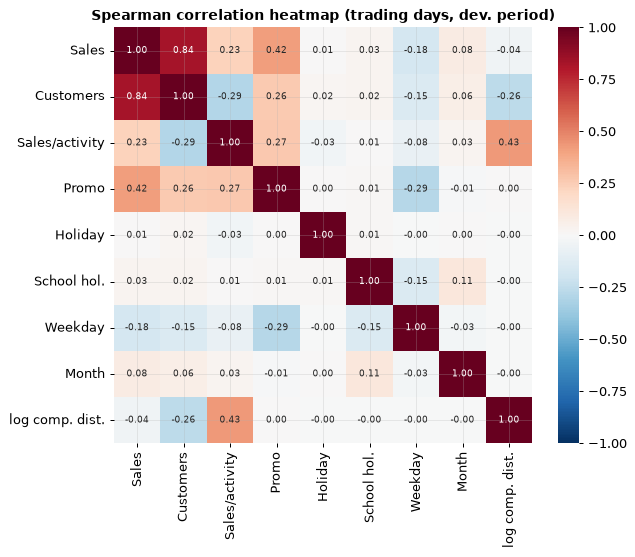

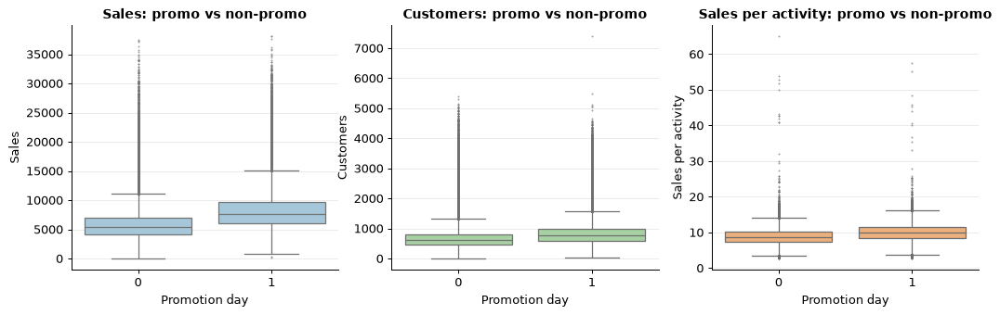

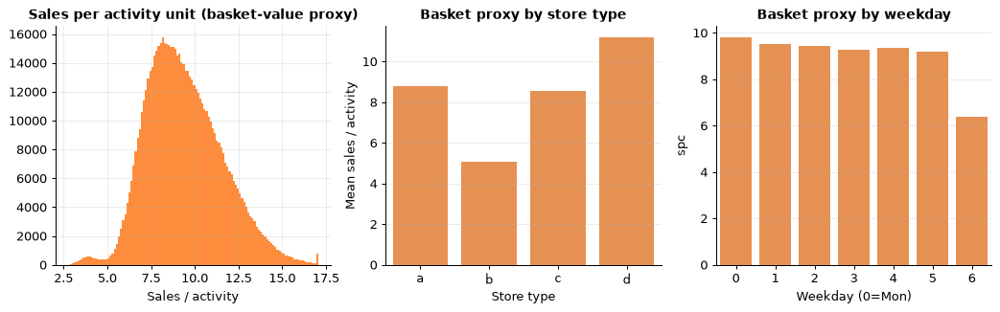

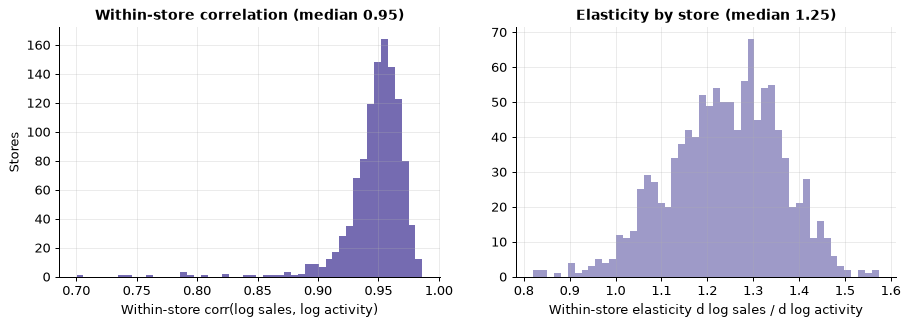

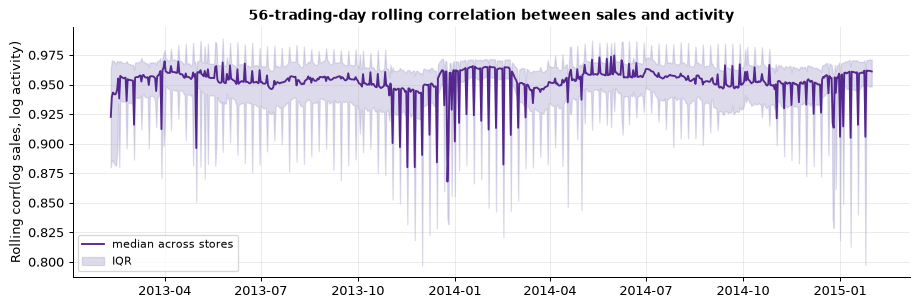

[OK] rossmann | EDA relationships | 20.9s


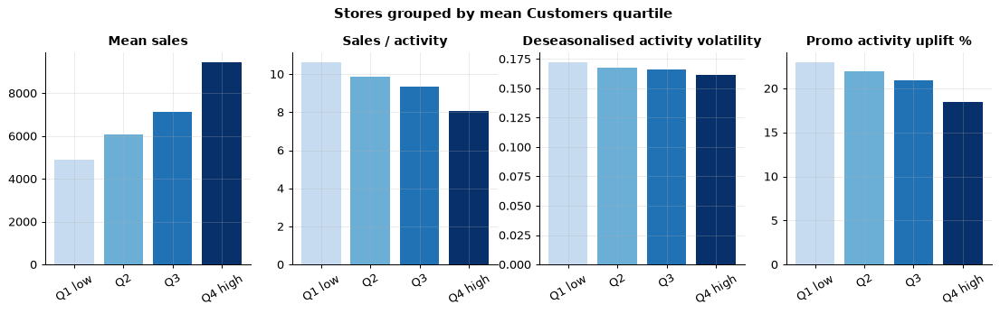

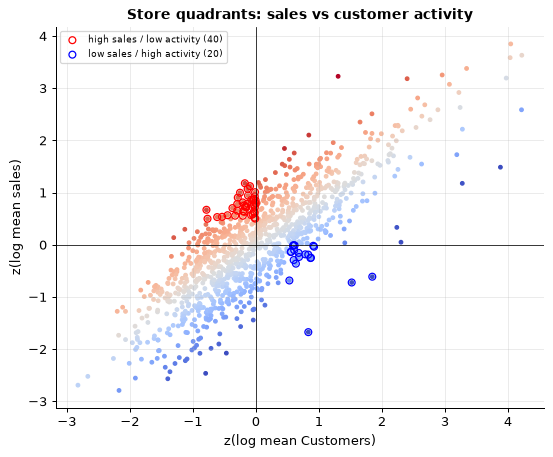

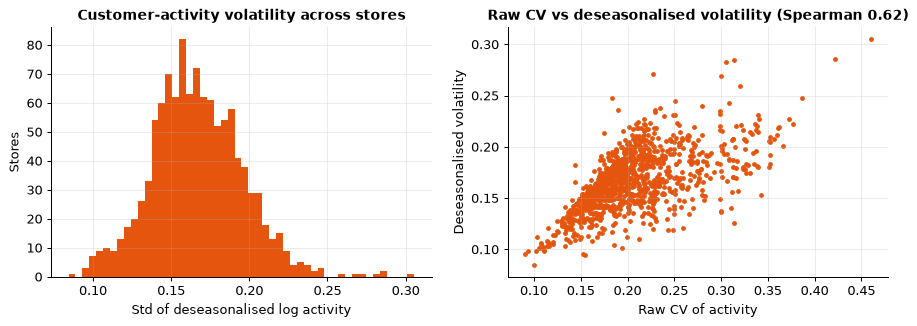

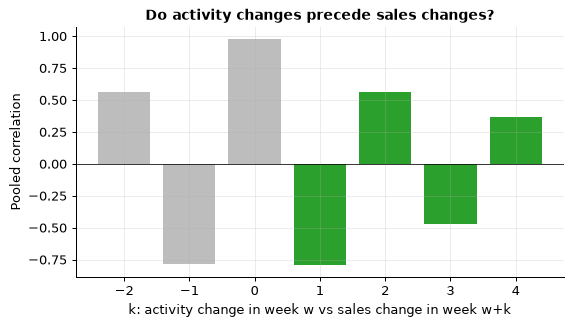

[OK] rossmann | EDA advanced | 12.8s
{
 "rows_dev": 677072,
 "stores": 1115,
 "sales_skew": 1.6090836765008105,
 "sales_mean": 6915.8445630597635,
 "sales_median": 6325.0,
 "act_skew": 2.7517389215458743,
 "act_mean": 764.473894947657,
 "store_mean_ratio_p90_p10": 2.1513405395930825,
 "weekday_sales": {
  "0": 8192.8,
  "1": 7036.8,
  "2": 6671.9,
  "3": 6719.2,
  "4": 7064.8,
  "5": 5824.2,
  "6": 8143.0
 },
 "weekday_act": {
  "0": 860.3,
  "1": 771.4,
  "2": 740.3,
  "3": 756.4,
  "4": 785.7,
  "5": 660.2,
  "6": 1439.7
 },
 "weekday_n": {
  "0": 110785,
  "1": 114992,
  "2": 112963,
  "3": 107432,
  "4": 111859,
  "5": 116197,
  "6": 2844
 },
 "yearly": {
  "sales": {
   "2013": 6814.8,
   "2014": 7026.1,
   "2015": 6913.2
  },
  "act": {
   "2013": 757.6,
   "2014": 774.8,
   "2015": 733.9
  },
  "days": {
   "2013": 365,
   "2014": 365,
   "2015": 31
  }
 },
 "acf_sales_lag1": 0.47077837725792326,
 "acf_sales_lag6_7": [
  -0.193,
  -0.026,
  -0.248
 ],
 "acf_act_lag1": 0.35450815

In [ ]:
def eda_frame(ctx):
    d = ctx['daily']
    dev = d[d.trading & (d.date <= ctx['splits']['val_end'])].merge(ctx['static'], on='store', how='left').copy()
    dev['spc'] = dev.sales / dev.activity
    dev['year'] = dev.date.dt.year; dev['month'] = dev.date.dt.month
    dev['ym'] = dev.date.dt.to_period('M').dt.to_timestamp()
    return dev

def eda_overview(ctx, dev):
    S = {}
    al, sl = ctx['act_label'], ctx['sales_label']
    # Sales distribution
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
    axs[0].hist(dev.sales, bins=120, color='#2c7fb8'); axs[0].set_xlabel(sl); axs[0].set_ylabel('Store-days')
    axs[0].set_title('Sales distribution (trading days)')
    axs[1].hist(np.log1p(dev.sales), bins=120, color='#2c7fb8'); axs[1].set_xlabel('log(1 + sales)')
    axs[1].set_title('Sales distribution, log scale')
    save_fig(ctx, fig, 'fig02_sales_distribution', 'Sales distribution.')
    S['sales_skew'] = float(stats.skew(dev.sales)); S['sales_mean'] = float(dev.sales.mean()); S['sales_median'] = float(dev.sales.median())
    # Activity distribution
    a = dev.activity.dropna()
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
    axs[0].hist(a, bins=120, color='#41ab5d'); axs[0].set_xlabel(al); axs[0].set_ylabel('Store-days')
    axs[0].set_title(f'{al} distribution')
    axs[1].hist(np.log1p(a), bins=120, color='#41ab5d'); axs[1].set_xlabel(f'log(1 + {al})')
    axs[1].set_title(f'{al} distribution, log scale')
    save_fig(ctx, fig, 'fig03_activity_distribution', 'Customer-activity distribution.')
    S['act_skew'] = float(stats.skew(a)); S['act_mean'] = float(a.mean())
    # Boxplots by store type
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
    order = sorted(dev.store_type.unique())
    sns.boxplot(data=dev, x='store_type', y='sales', order=order, ax=axs[0], fliersize=0.5, color='#9ecae1')
    sns.boxplot(data=dev, x='store_type', y='activity', order=order, ax=axs[1], fliersize=0.5, color='#a1d99b')
    sns.boxplot(data=dev, x='store_type', y='spc', order=order, ax=axs[2], fliersize=0.5, color='#fdae6b')
    axs[0].set_title('Sales by store type'); axs[1].set_title(f'{al} by store type'); axs[2].set_title('Sales per activity unit by store type')
    axs[0].set_ylabel(sl); axs[1].set_ylabel(al); axs[2].set_ylabel('Sales / activity')
    for ax in axs: ax.set_xlabel('Store type')
    save_fig(ctx, fig, 'fig04_boxplots', 'Boxplots of sales, activity and sales per activity.')
    # Daily trends (mean per trading store so that changing panel size does not bias the trend)
    daily_mean = dev.groupby('date').agg(sales=('sales', 'mean'), act=('activity', 'mean'), n=('store', 'size'))
    fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    axs[0].plot(daily_mean.index, daily_mean.sales, lw=0.4, color='#9ecae1', label='daily mean')
    axs[0].plot(daily_mean.index, daily_mean.sales.rolling(28, min_periods=7).mean(), color='#08519c', label='28-day rolling mean')
    axs[0].set_ylabel(f'Mean {sl} per trading store'); axs[0].set_title('Daily sales trend'); axs[0].legend()
    axs[1].plot(daily_mean.index, daily_mean.act, lw=0.4, color='#a1d99b', label='daily mean')
    axs[1].plot(daily_mean.index, daily_mean.act.rolling(28, min_periods=7).mean(), color='#006d2c', label='28-day rolling mean')
    axs[1].set_ylabel(f'Mean {al} per trading store'); axs[1].set_title(f'Daily {al} trend'); axs[1].legend()
    save_fig(ctx, fig, 'fig05_daily_trends', 'Daily sales and activity trends.')
    # Store-wise comparison
    sm_ = dev.groupby('store').agg(sales=('sales', 'mean'), act=('activity', 'mean')).sort_values('sales')
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
    axs[0].hist(sm_.sales, bins=60, color='#2c7fb8'); axs[0].set_xlabel(f'Store mean {sl}'); axs[0].set_ylabel('Stores')
    axs[0].set_title('Distribution of store mean sales')
    sel = pd.concat([sm_.head(10), sm_.tail(10)])
    axs[1].bar(range(len(sel)), sel.sales, color=['#fc9272'] * 10 + ['#2c7fb8'] * 10)
    axs[1].set_xticks(range(len(sel))); axs[1].set_xticklabels(sel.index.astype(str), rotation=90, fontsize=7)
    axs[1].set_title('Bottom-10 vs top-10 stores by mean sales'); axs[1].set_ylabel(f'Mean {sl}'); axs[1].set_xlabel('Store')
    save_fig(ctx, fig, 'fig06_store_comparison', 'Store-wise sales comparison.')
    S['store_mean_ratio_p90_p10'] = float(sm_.sales.quantile(.9) / sm_.sales.quantile(.1))
    return S

def eda_temporal(ctx, dev):
    S = {}
    al, sl = ctx['act_label'], ctx['sales_label']
    days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
    w = dev.groupby('dow').agg(sales=('sales', 'mean'), act=('activity', 'mean'), n=('store', 'size'))
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
    sns.barplot(data=dev, x='dow', y='sales', ax=axs[0], color='#2c7fb8', errorbar=('ci', 95), n_boot=200)
    sns.barplot(data=dev, x='dow', y='activity', ax=axs[1], color='#41ab5d', errorbar=('ci', 95), n_boot=200)
    for ax, t, y in [(axs[0], 'Sales by weekday', sl), (axs[1], f'{al} by weekday', al)]:
        ax.set_xticks(range(len(w))); ax.set_xticklabels([days[i] for i in w.index]); ax.set_title(t); ax.set_ylabel(f'Mean {y}'); ax.set_xlabel('')
    save_fig(ctx, fig, 'fig07_weekday', 'Sales and activity by weekday (95% CI).')
    S['weekday_sales'] = w.sales.round(1).to_dict(); S['weekday_act'] = w.act.round(1).to_dict(); S['weekday_n'] = w.n.to_dict()
    m = dev.groupby('ym').agg(sales=('sales', 'mean'), act=('activity', 'mean'))
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
    axs[0].plot(m.index, m.sales, marker='o', ms=3, color='#08519c'); axs[0].set_title('Monthly sales trend'); axs[0].set_ylabel(f'Mean {sl} per store-day')
    axs[1].plot(m.index, m.act, marker='o', ms=3, color='#006d2c'); axs[1].set_title(f'Monthly {al} trend'); axs[1].set_ylabel(f'Mean {al} per store-day')
    for ax in axs: ax.tick_params(axis='x', rotation=45)
    save_fig(ctx, fig, 'fig08_monthly_trends', 'Monthly sales and activity trends.')
    y = dev.groupby('year').agg(sales=('sales', 'mean'), act=('activity', 'mean'), days=('date', 'nunique'))
    moy = dev.groupby(['year', 'month']).sales.mean().unstack(0)
    fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
    axs[0].bar(y.index.astype(str), y.sales, color='#2c7fb8'); axs[0].set_title('Yearly mean sales (dev. period)'); axs[0].set_ylabel(f'Mean {sl}')
    axs[1].bar(y.index.astype(str), y.act, color='#41ab5d'); axs[1].set_title(f'Yearly mean {al}'); axs[1].set_ylabel(f'Mean {al}')
    for c in moy.columns:
        axs[2].plot(moy.index, moy[c], marker='o', ms=3, label=str(c))
    axs[2].set_title('Seasonal profile: month-of-year by year'); axs[2].set_xlabel('Month'); axs[2].set_ylabel(f'Mean {sl}'); axs[2].legend()
    save_fig(ctx, fig, 'fig09_yearly_seasonal', 'Yearly trends and seasonal profile.')
    S['yearly'] = y.round(1).to_dict()
    hm = dev.pivot_table(index='month', columns='dow', values='sales', aggfunc='mean')
    fig, ax = plt.subplots(figsize=(7, 4.2))
    sns.heatmap(hm / hm.values.mean(), cmap='RdBu_r', center=1, annot=True, fmt='.2f', annot_kws={'size': 6.5}, ax=ax,
                cbar_kws={'label': 'Mean sales / overall mean'})
    ax.set_xticklabels([days[int(i)] for i in hm.columns]); ax.set_title('Seasonality: month x weekday sales index'); ax.set_xlabel(''); ax.set_ylabel('Month')
    save_fig(ctx, fig, 'fig10_seasonal_heatmap', 'Month x weekday seasonal index.')
    # ACF: median over a random sample of stores, computed on the trading-day sequence
    rng = np.random.RandomState(CONFIG['seed'])
    stores = rng.choice(dev.store.unique(), min(120, dev.store.nunique()), replace=False)
    acs, aca = [], []
    for s in stores:
        e = dev[dev.store == s].sort_values('date')
        if len(e) > 120:
            acs.append(acf(np.log(e.sales.values), nlags=42, fft=True))
            av = np.log(e.activity.values)
            if np.isfinite(av).mean() > 0.95:
                aca.append(acf(pd.Series(av).interpolate().bfill().values, nlags=42, fft=True))
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
    for ax, arr, col, t in [(axs[0], np.array(acs), '#2c7fb8', 'log sales'), (axs[1], np.array(aca), '#41ab5d', f'log {al}')]:
        if len(arr):
            med = np.median(arr, 0); lo, hi = np.percentile(arr, [25, 75], 0)
            ax.bar(range(len(med)), med, color=col, width=0.6); ax.fill_between(range(len(med)), lo, hi, color=col, alpha=0.2, label='IQR across stores')
            ax.axhline(0, color='k', lw=0.6); ax.set_title(f'ACF of {t} (median over {len(arr)} stores)')
            ax.set_xlabel('Lag (trading days)'); ax.set_ylabel('Autocorrelation'); ax.legend()
    save_fig(ctx, fig, 'fig11_acf', 'Autocorrelation functions.')
    if len(acs):
        S['acf_sales_lag1'] = float(np.median(np.array(acs)[:, 1])); S['acf_sales_lag6_7'] = np.median(np.array(acs)[:, 5:8], 0).round(3).tolist()
    if len(aca):
        S['acf_act_lag1'] = float(np.median(np.array(aca)[:, 1]))
    # Example store time series
    sm_ = dev.groupby('store').sales.mean().sort_values()
    ex = [sm_.index[int(q * (len(sm_) - 1))] for q in (0.1, 0.5, 0.95)]
    fig, axs = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
    for ax, s in zip(axs, ex):
        e = dev[dev.store == s].sort_values('date')
        ax.plot(e.date, e.sales, color='#08519c', lw=0.6, label='Sales')
        ax2 = ax.twinx(); ax2.plot(e.date, e.activity, color='#31a354', lw=0.6, alpha=0.8, label=al)
        ax.set_ylabel(sl, color='#08519c'); ax2.set_ylabel(al, color='#31a354'); ax2.grid(False)
        ax.set_title(f'Store {s}: sales and {al}')
    save_fig(ctx, fig, 'fig12_store_timeseries', 'Sales and activity time series for three stores.')
    return S

def eda_relationships(ctx, dev):
    S = {}
    al, sl = ctx['act_label'], ctx['sales_label']
    v = dev.dropna(subset=['activity'])
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
    hb = axs[0].hexbin(v.activity, v.sales, gridsize=80, bins='log', cmap='viridis', mincnt=1)
    plt.colorbar(hb, ax=axs[0], label='log10(count)'); axs[0].set_xlabel(al); axs[0].set_ylabel(sl)
    r = np.corrcoef(v.activity, v.sales)[0, 1]; rl = np.corrcoef(np.log(v.activity), np.log(v.sales))[0, 1]
    axs[0].set_title(f'Same-day sales vs {al} (r = {r:.3f})')
    hb = axs[1].hexbin(np.log(v.activity), np.log(v.sales), gridsize=80, bins='log', cmap='viridis', mincnt=1)
    plt.colorbar(hb, ax=axs[1], label='log10(count)'); axs[1].set_xlabel(f'log {al}'); axs[1].set_ylabel('log sales')
    axs[1].set_title(f'Log-log (r = {rl:.3f})')
    save_fig(ctx, fig, 'fig13_sales_vs_activity', 'Sales versus customer activity.')
    S['corr_same_day'] = float(r); S['corr_same_day_log'] = float(rl)
    cols = {'sales': 'Sales', 'activity': al, 'spc': 'Sales/activity', 'promo': 'Promo', 'holiday': 'Holiday', 'school': 'School hol.',
            'dow': 'Weekday', 'month': 'Month'}
    if 'log_comp_dist' in v: cols['log_comp_dist'] = 'log comp. dist.'
    if 'promo_int' in v and ctx['name'] != 'rossmann': cols['promo_int'] = 'Promo intensity'
    cm = v[list(cols)].rename(columns=cols)
    cm = cm.loc[:, cm.std() > 0].corr(method='spearman')
    fig, ax = plt.subplots(figsize=(7.5, 6))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax, annot_kws={'size': 7.5})
    ax.set_title('Spearman correlation heatmap (trading days, dev. period)')
    save_fig(ctx, fig, 'fig14_correlation_heatmap', 'Correlation heatmap.')
    # Promotion analysis
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
    for ax, col, t, c in [(axs[0], 'sales', 'Sales', '#9ecae1'), (axs[1], 'activity', al, '#a1d99b'), (axs[2], 'spc', 'Sales per activity', '#fdae6b')]:
        sns.boxplot(data=v, x='promo', y=col, ax=ax, fliersize=0.4, color=c)
        ax.set_title(f'{t}: promo vs non-promo'); ax.set_xlabel('Promotion day'); ax.set_ylabel(t)
    save_fig(ctx, fig, 'fig15_promotion', 'Promotion analysis.')
    wk = v[v.dow < 5]
    up = wk.groupby('promo')[['sales', 'activity', 'spc']].mean()
    if up.shape[0] == 2:
        S['promo_uplift_sales_pct'] = float((up.loc[1, 'sales'] / up.loc[0, 'sales'] - 1) * 100)
        S['promo_uplift_act_pct'] = float((up.loc[1, 'activity'] / up.loc[0, 'activity'] - 1) * 100)
        S['promo_uplift_spc_pct'] = float((up.loc[1, 'spc'] / up.loc[0, 'spc'] - 1) * 100)
    # Sales per customer
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
    axs[0].hist(v.spc.clip(upper=v.spc.quantile(0.999)), bins=120, color='#fd8d3c'); axs[0].set_xlabel('Sales / activity'); axs[0].set_title('Sales per activity unit (basket-value proxy)')
    sns.barplot(data=v, x='store_type', y='spc', ax=axs[1], color='#fd8d3c', errorbar=None, order=sorted(v.store_type.unique()))
    axs[1].set_title('Basket proxy by store type'); axs[1].set_xlabel('Store type'); axs[1].set_ylabel('Mean sales / activity')
    sns.barplot(data=v, x='dow', y='spc', ax=axs[2], color='#fd8d3c', errorbar=None); axs[2].set_title('Basket proxy by weekday'); axs[2].set_xlabel('Weekday (0=Mon)')
    save_fig(ctx, fig, 'fig16_sales_per_customer', 'Sales per customer analysis.')
    S['spc_store_cv'] = float(v.groupby('store').spc.mean().std() / v.groupby('store').spc.mean().mean())
    # Within-store relationship
    g = v.groupby('store')
    ws = pd.DataFrame({'r': g.apply(lambda e: np.corrcoef(np.log(e.sales), np.log(e.activity))[0, 1] if len(e) > 30 else np.nan),
                       'elast': g.apply(lambda e: np.polyfit(np.log(e.activity), np.log(e.sales), 1)[0] if len(e) > 30 else np.nan)}).dropna()
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
    axs[0].hist(ws.r, bins=50, color='#756bb1'); axs[0].set_xlabel('Within-store corr(log sales, log activity)'); axs[0].set_ylabel('Stores')
    axs[0].set_title(f'Within-store correlation (median {ws.r.median():.2f})')
    axs[1].hist(ws.elast, bins=50, color='#9e9ac8'); axs[1].set_xlabel('Within-store elasticity d log sales / d log activity')
    axs[1].set_title(f'Elasticity by store (median {ws.elast.median():.2f})')
    save_fig(ctx, fig, 'fig17_within_store_relationship', 'Sales-activity relationship by store.')
    S['within_store_r_median'] = float(ws.r.median()); S['elasticity_median'] = float(ws.elast.median())
    # Rolling correlation (56 trading days) - median across stores over time
    v2 = v.sort_values(['store', 'date']).copy()
    v2['ls'], v2['la'] = np.log(v2.sales), np.log(v2.activity)
    rc = v2.groupby('store')[['ls', 'la']].rolling(56, min_periods=40).corr().xs('la', level=-1)['ls']
    v2['rcorr'] = rc.reset_index(level=0, drop=True).sort_index().reindex(v2.index).values
    rq = v2.groupby('date').rcorr.quantile([0.25, 0.5, 0.75]).unstack()
    fig, ax = plt.subplots(figsize=(12, 3.6))
    ax.plot(rq.index, rq[0.5], color='#54278f', label='median across stores')
    ax.fill_between(rq.index, rq[0.25], rq[0.75], color='#9e9ac8', alpha=0.35, label='IQR')
    ax.set_ylabel('Rolling corr(log sales, log activity)'); ax.set_title('56-trading-day rolling correlation between sales and activity'); ax.legend()
    save_fig(ctx, fig, 'fig18_rolling_correlation', 'Rolling sales-activity correlation.')
    S['rolling_corr_median'] = float(rq[0.5].median())
    return S

def eda_advanced(ctx, dev):
    S = {}
    al = ctx['act_label']
    v = dev.dropna(subset=['activity']).sort_values(['store', 'date']).copy()
    v['la'] = np.log(v.activity)
    prev = v.groupby(['store', 'dow']).la.transform(lambda x: x.shift(1).rolling(4, min_periods=2).mean())
    v['r'] = v.la - prev                          # deseasonalised activity deviation
    prof = v.groupby('store').agg(sales=('sales', 'mean'), act=('activity', 'mean'), spc=('spc', 'mean'),
                                  vol=('r', 'std'), cv_raw=('activity', lambda x: x.std() / x.mean()))
    wk = v[v.dow < 5]
    pu = wk.groupby(['store', 'promo']).activity.mean().unstack()
    prof['promo_uplift'] = (pu[1] / pu[0] - 1) * 100 if (1 in pu and 0 in pu) else np.nan
    prof['act_q'] = pd.qcut(prof.act, 4, labels=['Q1 low', 'Q2', 'Q3', 'Q4 high'])
    comp = prof.groupby('act_q', observed=True)[['sales', 'act', 'spc', 'vol', 'promo_uplift']].mean()
    fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
    for ax, c, t in zip(axs, ['sales', 'spc', 'vol', 'promo_uplift'], ['Mean sales', 'Sales / activity', 'Deseasonalised activity volatility', 'Promo activity uplift %']):
        ax.bar(comp.index.astype(str), comp[c], color=['#c6dbef', '#6baed6', '#2171b5', '#08306b']); ax.set_title(t); ax.tick_params(axis='x', rotation=30)
    fig.suptitle(f'Stores grouped by mean {al} quartile', y=1.04, fontweight='bold')
    save_fig(ctx, fig, 'fig19_high_vs_low_activity', 'High- vs low-activity stores.')
    S['activity_quartiles'] = comp.round(3).to_dict()
    # Quadrants: residual of log store sales on log store activity
    x, y = np.log(prof.act), np.log(prof.sales)
    b = np.polyfit(x, y, 1); prof['resid'] = y - np.polyval(b, x)
    zx, zy = (x - x.mean()) / x.std(), (y - y.mean()) / y.std()
    hs_la = prof[(zy > 0.5) & (zx < 0)].sort_values('resid', ascending=False)
    ls_ha = prof[(zy < 0) & (zx > 0.5)].sort_values('resid')
    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.scatter(zx, zy, s=8, c=prof.resid, cmap='coolwarm', vmin=-0.5, vmax=0.5)
    ax.scatter(zx[hs_la.index], zy[hs_la.index], s=30, facecolors='none', edgecolors='r', label=f'high sales / low activity ({len(hs_la)})')
    ax.scatter(zx[ls_ha.index], zy[ls_ha.index], s=30, facecolors='none', edgecolors='b', label=f'low sales / high activity ({len(ls_ha)})')
    ax.axhline(0, color='k', lw=0.6); ax.axvline(0, color='k', lw=0.6)
    ax.set_xlabel(f'z(log mean {al})'); ax.set_ylabel('z(log mean sales)'); ax.set_title('Store quadrants: sales vs customer activity'); ax.legend(fontsize=7)
    save_fig(ctx, fig, 'fig20_store_quadrants', 'High-sales/low-activity and low-sales/high-activity stores.')
    S['n_high_sales_low_act'] = len(hs_la); S['n_low_sales_high_act'] = len(ls_ha)
    S['examples_high_sales_low_act'] = hs_la.index[:8].tolist(); S['examples_low_sales_high_act'] = ls_ha.index[:8].tolist()
    # Stability
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
    axs[0].hist(prof.vol.dropna(), bins=50, color='#e6550d'); axs[0].set_xlabel('Std of deseasonalised log activity'); axs[0].set_ylabel('Stores')
    axs[0].set_title('Customer-activity volatility across stores')
    axs[1].scatter(prof.cv_raw, prof.vol, s=8, color='#e6550d'); axs[1].set_xlabel('Raw CV of activity'); axs[1].set_ylabel('Deseasonalised volatility')
    rr = prof[['cv_raw', 'vol']].corr(method='spearman').iloc[0, 1]
    axs[1].set_title(f'Raw CV vs deseasonalised volatility (Spearman {rr:.2f})')
    save_fig(ctx, fig, 'fig21_activity_stability', 'Activity stability.')
    S['vol_median'] = float(prof.vol.median()); S['vol_p90_p10'] = float(prof.vol.quantile(.9) / prof.vol.quantile(.1))
    S['rawcv_vs_deseason_spearman'] = float(rr)
    # Lead-lag: weekly log changes
    v['week'] = v.date.dt.to_period('W').dt.start_time
    wkly = v.groupby(['store', 'week']).agg(s=('sales', 'sum'), a=('activity', 'sum'), n=('date', 'size'))
    wkly = wkly[wkly.n >= 5].reset_index().sort_values(['store', 'week'])
    wkly['ds'] = np.log(wkly.s / wkly.n) - np.log((wkly.s / wkly.n).groupby(wkly.store).shift(1))
    wkly['da'] = np.log(wkly.a / wkly.n) - np.log((wkly.a / wkly.n).groupby(wkly.store).shift(1))
    out = []
    for k in range(-2, 5):
        fut = wkly.groupby('store').ds.shift(-k)
        m = wkly.da.notna() & fut.notna()
        out.append((k, np.corrcoef(wkly.da[m], fut[m])[0, 1]))
    ll = pd.DataFrame(out, columns=['lead_weeks', 'corr'])
    wkly['ds_next'] = wkly.groupby('store').ds.shift(-1)
    reg = wkly.dropna(subset=['ds', 'da', 'ds_next'])
    X = sm.add_constant(reg[['ds', 'da']])
    ols = sm.OLS(reg.ds_next, X).fit(cov_type='cluster', cov_kwds={'groups': reg.store})
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.bar(ll.lead_weeks, ll['corr'], color=np.where(ll.lead_weeks > 0, '#2ca02c', '#bdbdbd'))
    ax.axhline(0, color='k', lw=0.6); ax.set_xlabel('k: activity change in week w vs sales change in week w+k')
    ax.set_ylabel('Pooled correlation'); ax.set_title('Do activity changes precede sales changes?')
    save_fig(ctx, fig, 'fig22_activity_change_leadlag', 'Activity change vs subsequent sales change.')
    S['leadlag_corr'] = ll.set_index('lead_weeks')['corr'].round(3).to_dict()
    S['next_week_reg'] = {'coef_ds': float(ols.params['ds']), 'coef_da': float(ols.params['da']), 'p_da': float(ols.pvalues['da']),
                          't_da': float(ols.tvalues['da']), 'n': int(ols.nobs)}
    ctx['eda_store_profile'] = prof
    return S

def run_eda(ctx):
    dev = eda_frame(ctx)
    S = {'rows_dev': len(dev), 'stores': int(dev.store.nunique())}
    for name, fn in [('overview', eda_overview), ('temporal', eda_temporal), ('relationships', eda_relationships), ('advanced', eda_advanced)]:
        out = run_step(ctx, f'EDA {name}', fn, ctx, dev)
        if out: S.update(out)
    ctx['eda_stats'] = S
    return S

R_eda = run_eda(R)
print(json.dumps(R_eda, indent=1, default=str))

**Interpretation: exploratory analysis (development period only, test untouched).**

*Distributions (Figs. 02–06).* Sales are right-skewed (skew 1.61; mean 6,916 EUR vs median 6,325 EUR) and customers more so (skew 2.75). This supports a log-transformed target. Store mean sales differ by a factor of 2.2 between the 90th and 10th percentile, so global models need store-level history features. The chain-wide daily mean rises sharply every December, and customers follow the same pattern.

*Temporal patterns (Figs. 07–12).*
* Among Monday–Saturday, Monday has the highest sales (8,193 EUR) and Saturday the lowest (5,824 EUR). Customers follow the same pattern.
* Sunday's high means (8,143 EUR; 1,440 customers) come from only **2,844** store-days, a handful of stores that trade on Sundays, so they are not a chain-wide effect.
* The trading-day ACF has lag-1 autocorrelation 0.47 and *negative* values at lags 5–7 (−0.19, −0.03, −0.25). This is the footprint of Rossmann's alternating promotion weeks, which recurs in every later analysis.

*Sales and customers (Figs. 13–18).*
* Same-day sales and customers correlate at r = 0.83 (log-log 0.86). Within a store the median correlation is 0.95, with an elasticity of 1.25.
* This strong contemporaneous link is exactly the signal that is **not available at the forecast origin**. The oracle diagnostic (Section 16) measures how much it would be worth.
* Promotions raise weekday sales by 38.7 %, customers by 19.9 % and sales per customer by 15.1 %, so promotions increase both traffic and basket value.
* The 56-day rolling correlation stays near 0.95 throughout, which is a stable relationship.

*Advanced (Figs. 19–22).*
* Stores in the highest customer-activity quartile sell more (9,456 vs 4,902 EUR). They also have **smaller baskets** (8.06 vs 10.64 EUR per customer) and weaker promotion uplift (18.5 % vs 23.0 %).
* 40 stores have high sales but low traffic (large-basket stores) and 20 the reverse.
* Deseasonalised activity volatility is fairly homogeneous: the 90th/10th-percentile ratio is 1.53.
* Week-to-week activity changes and the following week's sales changes have **alternating** correlations (k = 1: −0.80, k = 2: +0.56). That is the fortnightly promotion rhythm, not customer behaviour that leads sales.
* A regression of next week's sales change on this week's sales and activity changes gives a positive activity coefficient (0.47, t = 23, store-clustered SE). Activity changes carry some information beyond sales changes, but much of the weekly dynamics is promotion-calendar driven.

## 7. Temporal feature engineering

### 7.1 Forecast origin and the as-of state

Let $y_{s,t}$ be the sales of store $s$ on trading day $t$. For horizon $h\in\{1,7,14,28\}$ calendar days, the **forecast origin** is $o=t-h$. A feature is admissible only if it can be computed from information available at the end of day $o$:

* **History features** come from the store's own trading days up to and including the last trading day $\le o$.
* **Calendar features of the target day** (weekday, month, planned promotion, state/school holiday, scheduled closures next to the day, and store master data) are known in advance. They are the same information Kaggle supplies in its test files.

**Implementation.** For every store and trading day $d$ we compute an **as-of state vector**, in which every window ends at $d$ inclusive. A target row $(s,t,h)$ is then joined to the state of the **last trading day $\le t-h$** with a backward `merge_asof`. The state vector therefore cannot contain anything dated after the origin. For example, a feature used to forecast $t$ at $h=7$ never contains days $t-6 \dots t$. The leakage audit in Section 16 tests this executably.

`*_lagk` is the value on the *k*-th most recent trading day at the origin, so `s_lag1` is the last observed day. `*_maw` is the mean over the last *w* trading days. `s_dow_t` is the mean log sales of the last four trading days that fall on the **target's** weekday.

### 7.2 Target-date mapping

| horizon h | origin | newest information used | example: target 2015-03-20 (Fri) |
|---|---|---|---|
| 1 | t − 1 | trading day ≤ 2015-03-19 | Thu 19 Mar |
| 7 | t − 7 | trading day ≤ 2015-03-13 | Fri 13 Mar |
| 14 | t − 14 | trading day ≤ 2015-03-06 | Fri 6 Mar |
| 28 | t − 28 | trading day ≤ 2015-02-20 | Fri 20 Feb |

One **direct** model is trained per horizon, so errors do not accumulate across recursive steps.

## 8. CVI construction

The five components are computed from **activity history only**, with every window closing at the origin. To avoid the calendar confounding that affects naive windows (weekly cycles, Rossmann's fortnightly promotion rhythm), stability is measured on *deseasonalised* activity, and momentum compares windows of **14 vs 56 trading days**, both whole multiples of the weekly and fortnightly cycles.

| Component | Score (higher = more "value") | Sub-features kept for analysis |
|---|---|---|
| C1 Activity level | $\log \overline{A}_{28}$, mean activity over the last 28 trading days | 7/14/28/90-day means |
| C2 Spending proxy | $\log(\sum S/\sum A)$ over 28 trading days: **basket-value proxy, not lifetime value** | 7-day SPC, SPC change, SPC CV |
| C3 Stability | $-\mathrm{sd}_{56}(r_d)$, with $r_d=\log A_d-\overline{\log A}$ over the previous 4 same-weekday trading days | raw rolling std / CV |
| C4 Momentum | $\log(\overline{A}_{14}/\overline{A}_{56})$ | 7-vs-28 growth, 56-day log-linear slope |
| C5 Promotion responsiveness | mean log activity on promo weekdays minus non-promo weekdays, last 112 trading days (Mon–Fri only) | promo / non-promo means |

Promotion **history** (≤ origin) is used for C5. The target day's planned promotion is a calendar feature shared by all configurations.

**Standardisation and composite index.** Each component is z-scored with the mean and standard deviation of **training-period** state rows only. A missing z-score (insufficient history) is set to 0, the training mean, and its rate is reported. Three weightings are estimated on training data only:
1. **Equal weights** (pre-specified primary composite, `cvi_eq`): $\mathrm{CVI}=\tfrac15\sum_k z_k$.
2. **Data-driven weights** (`cvi_dd`): ridge regression of the standardised log mean sales of the *next* 28 days on $z_1..z_5$. It is fitted only on origins whose 28-day window closes inside the training period, and the weights are normalised so that $\sum|w|=1$.
3. **PCA weights** (`cvi_pca`, exploratory only): first principal component loadings. A high PCA weight means the component shares variance with the others, which is not the same as customer value.

In [ ]:
COMP_RAW = ['c1_level', 'c2_spend', 'c3_stability', 'c4_momentum', 'c5_promo']
COMP = ['z_' + c for c in COMP_RAW]
COMP_NAMES = dict(zip(COMP, ['C1 Activity level', 'C2 Spending proxy', 'C3 Stability', 'C4 Momentum', 'C5 Promo responsiveness']))
ACT_RAW = ['a_lag1', 'a_lag7', 'a_ma7', 'a_ma14', 'a_ma28', 'a_dow_t']
SALES_HIST = ['s_lag1', 's_lag7', 's_lag14', 's_lag28', 's_ma7', 's_ma14', 's_ma28', 's_dow_t', 'days_since_obs']
PLACEBO = ['p_stability', 'p_momentum', 'p_promo']
SUB_FEATURES = ['a_ma90', 'spc_7', 'spc_change', 'spc_cv28', 'a_cv28', 'a_growth_7_28', 'a_slope56']

def _roll(x, keys, w, fn='mean', minp=None):
    """Rolling statistic over each store's trading-day sequence, window ending at (and including) the row."""
    minp = max(2, w // 2) if minp is None else minp
    keys = keys if isinstance(keys, list) else [keys]
    r = getattr(x.groupby(keys, sort=False).rolling(w, min_periods=minp), fn)()
    return r.reset_index(level=list(range(len(keys))), drop=True).sort_index()

def build_state(ctx, daily):
    td = daily[daily.trading].sort_values(['store', 'date']).reset_index(drop=True)
    st, dw = td.store, td.dow
    sales, act = td.sales.astype(float), td.activity.astype(float)
    ls, la, lap = np.log1p(sales), np.log(act), np.log1p(act)
    S = td[['store', 'date', 'dow', 'promo']].copy()
    S['pos'] = np.arange(len(td))
    S['n_obs'] = td.groupby('store').cumcount() + 1
    # ---- sales history (baseline) ---------------------------------------------
    for k in [1, 7, 14, 28]:
        S[f's_lag{k}'] = ls.groupby(st).shift(k - 1)
    for w in [7, 14, 28, 56]:
        S[f's_ma{w}'] = np.log1p(_roll(sales, st, w))
    sd4 = _roll(ls, [st, dw], 4, 'mean', 1)
    for w in range(7):
        S[f'sdow_{w}'] = sd4.where(dw == w).groupby(st).ffill()
    # ---- raw activity history (config E) ----------------------------------------
    S['a_lag1'] = lap
    S['a_lag7'] = lap.groupby(st).shift(6)
    for w in [7, 14, 28]:
        S[f'a_ma{w}'] = np.log1p(_roll(act, st, w))
    ad4 = _roll(lap, [st, dw], 4, 'mean', 1)
    for w in range(7):
        S[f'adow_{w}'] = ad4.where(dw == w).groupby(st).ffill()
    # ---- CVI components -------------------------------------------------------
    both = sales.where(act.notna())
    m28 = _roll(act, st, 28, 'mean', 14)
    S['c1_level'] = np.log(m28)
    S['c2_spend'] = np.log(_roll(both, st, 28, 'sum', 14) / _roll(act, st, 28, 'sum', 14))
    prev4 = _roll(la.groupby([st, dw]).shift(1), [st, dw], 4, 'mean', 2)
    r = la - prev4
    S['c3_stability'] = -_roll(r, st, 56, 'std', 20)
    S['c4_momentum'] = np.log(_roll(act, st, 14, 'mean', 7) / _roll(act, st, 56, 'mean', 28))
    wk = dw < 5
    S['c5_promo'] = (_roll(la.where(wk & (td.promo == 1)), st, 112, 'mean', 5)
                     - _roll(la.where(wk & (td.promo == 0)), st, 112, 'mean', 5))
    # ---- component sub-features (documentation / interpretation) ------------------
    S['a_ma90'] = np.log1p(_roll(act, st, 90, 'mean', 45))
    S['spc_7'] = np.log(_roll(both, st, 7, 'sum', 4) / _roll(act, st, 7, 'sum', 4))
    S['spc_change'] = S['spc_7'] - S['c2_spend']
    spc = sales / act
    S['spc_cv28'] = _roll(spc, st, 28, 'std', 14) / _roll(spc, st, 28, 'mean', 14)
    S['a_cv28'] = _roll(act, st, 28, 'std', 14) / m28
    S['a_growth_7_28'] = np.log(_roll(act, st, 7, 'mean', 4) / m28)
    i = S['n_obs'].astype(float); yf = la.groupby(st).ffill()
    mi, my = _roll(i, st, 56, 'mean', 28), _roll(yf, st, 56, 'mean', 28)
    miy, mii = _roll(i * yf, st, 56, 'mean', 28), _roll(i * i, st, 56, 'mean', 28)
    S['a_slope56'] = (miy - mi * my) / (mii - mi ** 2) * 28
    # ---- sales-analogue control (same recipe on sales, no customer data) ----------
    ps4 = _roll(ls.groupby([st, dw]).shift(1), [st, dw], 4, 'mean', 2)
    S['p_stability'] = -_roll(ls - ps4, st, 56, 'std', 20)
    S['p_momentum'] = np.log(_roll(sales, st, 14, 'mean', 7) / _roll(sales, st, 56, 'mean', 28))
    S['p_promo'] = (_roll(ls.where(wk & (td.promo == 1)), st, 112, 'mean', 5)
                    - _roll(ls.where(wk & (td.promo == 0)), st, 112, 'mean', 5))
    # ---- 28-day forward mean sales (ONLY for fitting data-driven CVI weights on training data)
    S['f28'] = future_log_mean_sales(td)
    S = S.replace([np.inf, -np.inf], np.nan)
    return S, td

def future_log_mean_sales(td, horizon=28):
    stores = pd.Index(td.store.unique())
    dates = pd.date_range(td.date.min(), td.date.max() + pd.Timedelta(days=horizon))
    si, di = stores.get_indexer(td.store), dates.get_indexer(td.date)
    tot = np.zeros((len(stores), len(dates) + 1)); cnt = np.zeros_like(tot)
    np.add.at(tot, (si, di + 1), td.sales.values); np.add.at(cnt, (si, di + 1), 1.0)
    tot, cnt = tot.cumsum(1), cnt.cumsum(1)
    end = np.minimum(di + horizon + 1, len(dates))
    s = tot[si, end] - tot[si, di + 1]; n = cnt[si, end] - cnt[si, di + 1]
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(n > 0, np.log(s / n), np.nan)

def fit_cvi(S, fit_end, min_hist):
    """Standardise components and estimate composite weights on TRAINING-period state rows only."""
    fm = ((S.date <= fit_end) & (S.n_obs >= min_hist)).values
    mu, sd = S.loc[fm, COMP_RAW].mean(), S.loc[fm, COMP_RAW].std()
    Z = (S[COMP_RAW] - mu) / sd
    miss = Z.isna().mean().round(4).to_dict()
    Z = Z.fillna(0.0)
    for c in COMP_RAW:
        S['z_' + c] = Z[c].values
    S['cvi_eq'] = Z.mean(axis=1).values
    pca = PCA(n_components=5, random_state=CONFIG['seed']).fit(Z.values[fm])
    load = pca.components_[0] * (1 if pca.components_[0][0] >= 0 else -1)
    w_pca = load / np.abs(load).sum()
    S['cvi_pca'] = Z.values @ w_pca
    dm = fm & ((S.date + pd.Timedelta(days=28)) <= fit_end).values & np.isfinite(S.f28.values)
    y = S.f28.values[dm]; y = (y - y.mean()) / y.std()
    rr = Ridge(alpha=1.0).fit(Z.values[dm], y)
    w_dd = rr.coef_ / np.abs(rr.coef_).sum()
    S['cvi_dd'] = Z.values @ w_dd
    meta = dict(fit_end=str(pd.Timestamp(fit_end).date()), fit_rows=int(fm.sum()), dd_fit_rows=int(dm.sum()),
                mean=mu.to_dict(), std=sd.to_dict(), missing_rate_before_impute=miss,
                w_equal=dict(zip(COMP, [0.2] * 5)), w_pca=dict(zip(COMP, w_pca.round(4))),
                pca_explained=pca.explained_variance_ratio_.round(4).tolist(),
                w_data_driven=dict(zip(COMP, w_dd.round(4))), dd_r2_train=float(rr.score(Z.values[dm], y)),
                fit_max_state_date=str(S.date[fm].max().date()))
    return meta

R_state = run_step(R, 'build state', build_state, R, R_daily)
R['state'], R['td'] = R_state
R['cvi_meta'] = run_step(R, 'fit CVI', fit_cvi, R['state'], R['splits']['train_end'], CONFIG['min_history'])
print(json.dumps(R['cvi_meta'], indent=1, default=str))

[OK] rossmann | build state | 12.0s


[OK] rossmann | fit CVI | 0.5s
{
 "fit_end": "2014-07-31",
 "fit_rows": 467473,
 "dd_fit_rows": 444856,
 "mean": {
  "c1_level": 6.554501896126908,
  "c2_spend": 2.2260151121841605,
  "c3_stability": -0.16098269299529167,
  "c4_momentum": 0.0009792258446025554,
  "c5_promo": 0.19481566975859482
 },
 "std": {
  "c1_level": 0.38692525556142643,
  "c2_spend": 0.21639223009742545,
  "c3_stability": 0.047880425527326576,
  "c4_momentum": 0.06191444639438401,
  "c5_promo": 0.06551437346272707
 },
 "missing_rate_before_impute": {
  "c1_level": 0.0172,
  "c2_spend": 0.0172,
  "c3_stability": 0.041,
  "c4_momentum": 0.0357,
  "c5_promo": 0.0146
 },
 "w_equal": {
  "z_c1_level": 0.2,
  "z_c2_spend": 0.2,
  "z_c3_stability": 0.2,
  "z_c4_momentum": 0.2,
  "z_c5_promo": 0.2
 },
 "w_pca": {
  "z_c1_level": 0.2448,
  "z_c2_spend": -0.2602,
  "z_c3_stability": 0.2057,
  "z_c4_momentum": 0.031,
  "z_c5_promo": -0.2583
 },
 "pca_explained": [
  0.3916,
  0.2268,
  0.1893,
  0.101,
  0.0913
 ],
 "w_data

**Interpretation: CVI estimation.**

* All standardisation and weighting statistics were fitted on training-period state rows only (fit window ends 2014-07-31). Before imputation, 1.5–4.1 % of component values were missing (insufficient history).
* The **data-driven weights** load on activity level (0.58) and the spending proxy (0.32), with near-zero weight on stability, momentum and promotion response. A target of "next-28-day sales level" mostly rewards store size.
* The PCA first component explains only 39 % of variance, and its loadings carry *opposite* signs on spending and promotion response. A PCA "index" therefore does **not** describe customer value, as anticipated in the protocol.

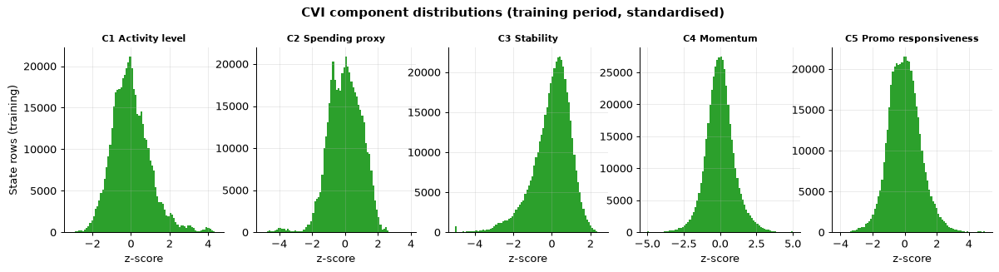

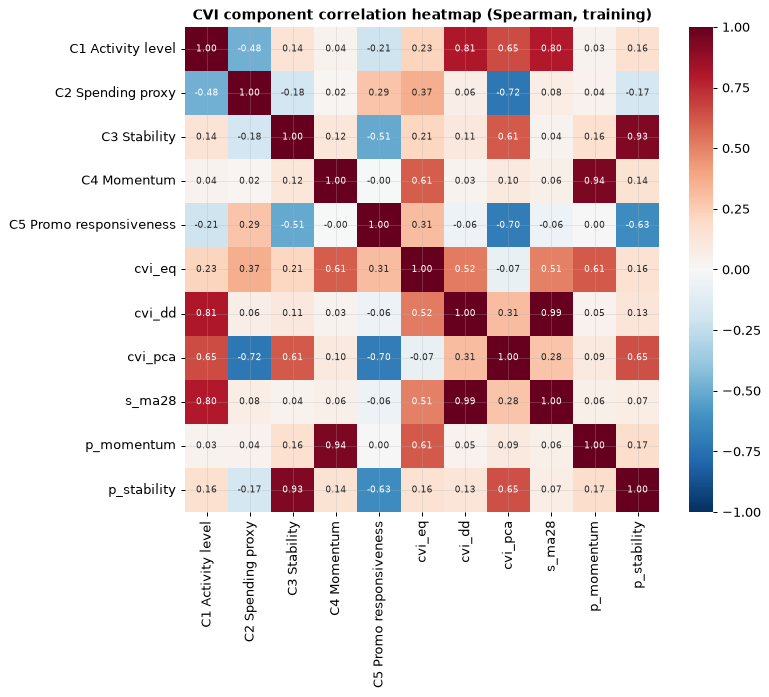

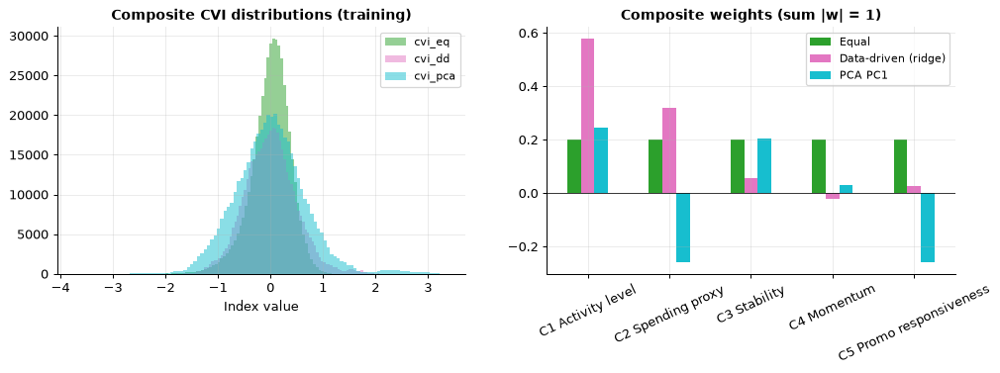

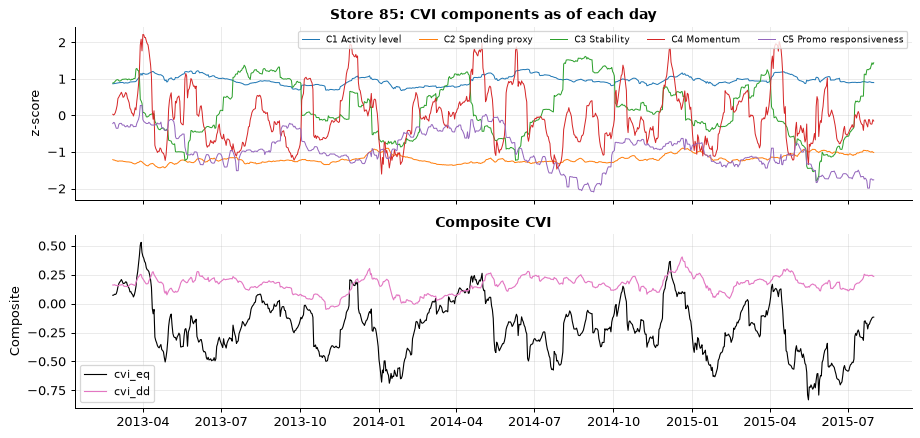

[OK] rossmann | CVI figures | 12.4s


,z_c1_level,z_c2_spend,z_c3_stability,z_c4_momentum,z_c5_promo,cvi_eq,cvi_dd,cvi_pca,s_ma28,p_momentum,p_stability
z_c1_level,1.0000,-0.4830,0.1350,0.0360,-0.2100,0.2260,0.8080,0.6540,0.8040,0.0320,0.1580
z_c2_spend,-0.4830,1.0000,-0.1820,0.0230,0.2870,0.3660,0.0640,-0.7230,0.0770,0.0420,-0.1740
z_c3_stability,0.1350,-0.1820,1.0000,0.1220,-0.5100,0.2140,0.1090,0.6130,0.0380,0.1600,0.9250
z_c4_momentum,0.0360,0.0230,0.1220,1.0000,-0.0040,0.6070,0.0340,0.0950,0.0560,0.9390,0.1420
z_c5_promo,-0.2100,0.2870,-0.5100,-0.0040,1.0000,0.3090,-0.0610,-0.7010,-0.0610,0.0010,-0.6270
cvi_eq,0.2260,0.3660,0.2140,0.6070,0.3090,1.0000,0.5230,-0.0700,0.5070,0.6100,0.1560
cvi_dd,0.8080,0.0640,0.1090,0.0340,-0.0610,0.5230,1.0000,0.3120,0.9940,0.0460,0.1310
cvi_pca,0.6540,-0.7230,0.6130,0.0950,-0.7010,-0.0700,0.3120,1.0000,0.2820,0.0940,0.6460
s_ma28,0.8040,0.0770,0.0380,0.0560,-0.0610,0.5070,0.9940,0.2820,1.0000,0.0620,0.0730
p_momentum,0.0320,0.0420,0.1600,0.9390,0.0010,0.6100,0.0460,0.0940,0.0620,1.0000,0.1740


Correlation with share of promo days in last 14 trading days: {'naive 7/28 momentum': 0.296, 'C4 momentum (14/56)': 0.258, 'C3 stability': 0.007}


In [ ]:
def cvi_figures(ctx):
    S, sp = ctx['state'], ctx['splits']
    tr = S[(S.date <= sp['train_end']) & (S.n_obs >= CONFIG['min_history'])]
    fig, axs = plt.subplots(1, 5, figsize=(16, 3.2))
    for ax, c in zip(axs, COMP):
        ax.hist(tr[c].clip(-5, 5), bins=80, color='#2ca02c'); ax.set_title(COMP_NAMES[c], fontsize=9); ax.set_xlabel('z-score')
    axs[0].set_ylabel('State rows (training)')
    fig.suptitle('CVI component distributions (training period, standardised)', y=1.05, fontweight='bold')
    save_fig(ctx, fig, 'fig23_cvi_component_distributions', 'CVI component distributions.')
    cols = COMP + ['cvi_eq', 'cvi_dd', 'cvi_pca', 's_ma28', 'p_momentum', 'p_stability']
    cm = tr[cols].corr(method='spearman')
    lab = [COMP_NAMES.get(c, c) for c in cols]
    fig, ax = plt.subplots(figsize=(8.5, 7))
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, xticklabels=lab, yticklabels=lab, ax=ax, annot_kws={'size': 7})
    ax.set_title('CVI component correlation heatmap (Spearman, training)')
    save_fig(ctx, fig, 'fig24_cvi_component_correlation', 'CVI component correlation heatmap.')
    m = ctx['cvi_meta']
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.6))
    for c, col in [('cvi_eq', '#2ca02c'), ('cvi_dd', '#e377c2'), ('cvi_pca', '#17becf')]:
        axs[0].hist(tr[c].clip(-4, 4), bins=100, alpha=0.5, label=c, color=col)
    axs[0].set_title('Composite CVI distributions (training)'); axs[0].set_xlabel('Index value'); axs[0].legend()
    W = pd.DataFrame({'Equal': m['w_equal'], 'Data-driven (ridge)': m['w_data_driven'], 'PCA PC1': m['w_pca']}).rename(index=COMP_NAMES)
    W.plot.bar(ax=axs[1], color=['#2ca02c', '#e377c2', '#17becf']); axs[1].set_title('Composite weights (sum |w| = 1)'); axs[1].tick_params(axis='x', rotation=25)
    axs[1].axhline(0, color='k', lw=0.6)
    save_fig(ctx, fig, 'fig25_composite_cvi_distribution', 'Composite CVI distribution and weights.')
    # one store through time + a confounding diagnostic
    s0 = S.groupby('store').size().idxmax()
    e = S[(S.store == s0) & (S.n_obs >= CONFIG['min_history'])]
    fig, axs = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
    for c in COMP:
        axs[0].plot(e.date, e[c], lw=0.8, label=COMP_NAMES[c])
    axs[0].legend(ncol=5, fontsize=7); axs[0].set_ylabel('z-score'); axs[0].set_title(f'Store {s0}: CVI components as of each day')
    axs[1].plot(e.date, e.cvi_eq, color='k', lw=0.9, label='cvi_eq'); axs[1].plot(e.date, e.cvi_dd, color='#e377c2', lw=0.9, label='cvi_dd')
    axs[1].legend(); axs[1].set_ylabel('Composite'); axs[1].set_title('Composite CVI')
    save_fig(ctx, fig, 'fig26_cvi_store_example', 'CVI components for one store over time.')
    # confounding check: correlation of momentum / stability with share of promo days in the last 14 trading days
    pr14 = S.promo.groupby(S.store).transform(lambda x: x.rolling(14, min_periods=7).mean())
    naive_mom = np.log(_roll(ctx['td'].activity.astype(float), ctx['td'].store, 7, 'mean', 4) /
                       _roll(ctx['td'].activity.astype(float), ctx['td'].store, 28, 'mean', 14))
    msk = ((S.date <= sp['train_end']) & (S.n_obs >= CONFIG['min_history'])).values
    conf = pd.Series({'naive 7/28 momentum': stats.spearmanr(naive_mom[msk], pr14[msk], nan_policy='omit')[0],
                      'C4 momentum (14/56)': stats.spearmanr(S.c4_momentum[msk], pr14[msk], nan_policy='omit')[0],
                      'C3 stability': stats.spearmanr(S.c3_stability[msk], pr14[msk], nan_policy='omit')[0]})
    ctx['cvi_confounding'] = conf.round(3).to_dict()
    return dict(train_rows=len(tr), corr=cm.round(3), confounding=ctx['cvi_confounding'])

R_cvi_fig = run_step(R, 'CVI figures', cvi_figures, R)
display(R_cvi_fig['corr']); print('Correlation with share of promo days in last 14 trading days:', R_cvi_fig['confounding'])

**Interpretation: CVI components (Figs. 23–26).**

*The five components do measure different things.* Their pairwise correlations are mostly small. The exceptions are level vs spending (−0.48), meaning high-traffic stores have smaller baskets, and stability vs promotion response (−0.51), meaning promotion-sensitive stores are less stable.

*Two warnings for the forecasting results:*
1. Customer-based **stability** correlates 0.93 with its sales analogue, and customer **momentum** 0.94 with its sales analogue. Activity level correlates 0.80 with the 28-day sales level, and `cvi_dd` 0.99. Much of what the CVI says is therefore already recoverable from the sales history. This is why the sales-analogue control (config P) is essential.
2. The 14-vs-56-day momentum definition reduced its correlation with the share of promotion days in the last 14 trading days only slightly, from 0.30 (naive 7/28 ratio) to 0.26. The de-confounding of momentum is **partial**. Stability is essentially unconfounded (0.007).

The equal-weighted composite mixes these dimensions roughly evenly. It correlates 0.61 with momentum and 0.51 with the sales level.

## 9. Temporal train / validation / test split

The split is chronological on the target date and is never shuffled. Hyperparameters, early stopping and composite-weight comparisons use **validation only**. The test period is scored once.

* All models are trained on **training** targets only. Validation is used for tuning and early stopping, and there is no refit on train + validation, so every model family follows the identical protocol, including the LSTM, which needs validation for early stopping.
* CVI standardisation and composite weights, imputers, scalers and encoders are fitted on **training** rows only.
* **Evaluation rows are identical** across models, configurations and horizons: a target row is used only if its store has at least 56 trading days of history at the origin **for every horizon**. The LSTM is trained on a seeded random subset of stores for compute reasons, and every model is additionally reported on that same subset so the deep-learning comparison is like-for-like.
* In addition, expanding-window rolling-origin cross-validation (Section 13.3) checks the stability of the main contrast.

In [ ]:
CAL_COMMON = ['dow_t', 'month_t', 'dom_t', 'woy_t', 'is_weekend_t', 'days_to_month_end_t', 'promo_t', 'holiday_t',
              'school_t', 'hol_prev_t', 'hol_next_t', 'closed_prev_t', 'closed_next_t']

def build_targets(ctx):
    d, sp = ctx['daily'], ctx['splits']
    T = d[d.trading & (d.date >= sp['train_start']) & (d.date <= sp['test_end'])].copy()
    T = T[['store', 'date', 'sales', 'activity', 'promo', 'promo_int', 'holiday', 'school', 'hol_prev', 'hol_next',
           'closed_prev', 'closed_next']].rename(columns={'promo': 'promo_t', 'promo_int': 'promo_int_t', 'holiday': 'holiday_t',
           'school': 'school_t', 'hol_prev': 'hol_prev_t', 'hol_next': 'hol_next_t', 'closed_prev': 'closed_prev_t', 'closed_next': 'closed_next_t'})
    T['y'] = T.pop('sales').astype(float)
    T['a_same_day'] = np.log1p(T.pop('activity'))          # ORACLE diagnostic only
    T['dow_t'] = T.date.dt.dayofweek; T['month_t'] = T.date.dt.month; T['dom_t'] = T.date.dt.day
    T['woy_t'] = T.date.dt.isocalendar().week.astype(int).values; T['is_weekend_t'] = (T.dow_t >= 5).astype(int)
    T['days_to_month_end_t'] = (T.date.dt.days_in_month - T.date.dt.day).astype(int)
    T['split'] = np.select([T.date <= sp['train_end'], (T.date >= sp['val_start']) & (T.date <= sp['val_end']),
                            T.date >= sp['test_start']], ['train', 'val', 'test'], 'gap')
    T = target_extras(ctx, T)
    T = T.merge(ctx['static'], on='store', how='left')
    return T.reset_index(drop=True)

def build_frame(T, S, h):
    F = T.copy()
    F['origin'] = F.date - pd.Timedelta(days=h)
    F = F.sort_values('origin')
    Sx = S.drop(columns=['dow', 'promo', 'f28']).rename(columns={'date': 'state_date'}).sort_values('state_date')
    F = pd.merge_asof(F, Sx, left_on='origin', right_on='state_date', by='store', direction='backward', allow_exact_matches=True)
    F['days_since_obs'] = (F.origin - F.state_date).dt.days.astype(float)
    ix = np.arange(len(F)); dw = F.dow_t.values.astype(int)
    F['s_dow_t'] = F[[f'sdow_{w}' for w in range(7)]].to_numpy(dtype=float)[ix, dw]
    F['a_dow_t'] = F[[f'adow_{w}' for w in range(7)]].to_numpy(dtype=float)[ix, dw]
    F = F.drop(columns=[f'sdow_{w}' for w in range(7)] + [f'adow_{w}' for w in range(7)])
    F['h'] = h
    return F

def feature_sets(ctx):
    cal = CAL_COMMON + ctx['extra_cal']
    if ctx['name'] == 'favorita':
        cal = [c for c in cal if c != 'school_t'] + ['promo_int_t']
    static = [c + '_code' for c in ctx['static_cat']] + ctx['static_num']
    base = cal + static + SALES_HIST
    sets = {'A': base, 'B': base + COMP, 'C': base + ['cvi_eq'], 'D': base + COMP + ['cvi_eq'], 'E': base + ACT_RAW,
            'C_dd': base + ['cvi_dd'], 'P': base + PLACEBO, 'ORACLE': base + ['a_same_day']}
    for c in COMP:
        sets['A+' + c.replace('z_', '')] = base + [c]
    ctx['cat_features'] = [c + '_code' for c in ctx['static_cat']]
    ctx['feature_sets'] = sets
    return sets

def build_all_frames(ctx):
    T = build_targets(ctx)
    frames = {h: build_frame(T, ctx['state'], h) for h in CONFIG['horizons']}
    # common eligibility across horizons: >= min_history trading days at the origin for EVERY horizon
    keys = None
    for h, F in frames.items():
        k = set(map(tuple, F.loc[F.n_obs.fillna(0) >= CONFIG['min_history'], ['store', 'date']].astype('int64').to_numpy()))
        keys = k if keys is None else keys & k
    for h in frames:
        F = frames[h]
        kk = pd.Series(list(map(tuple, F[['store', 'date']].astype('int64').to_numpy()))).isin(keys).values
        F = F[kk & (F.split != 'gap')].sort_values(['date', 'store']).reset_index(drop=True)
        num = F.select_dtypes(include=['float64']).columns
        F[num] = F[num].astype('float32')
        frames[h] = F
    ctx['frames'] = frames
    ctx['targets_all'] = len(T)
    return frames

FEATURE_SETS_R = feature_sets(R)
run_step(R, 'build horizon frames', build_all_frames, R)

def split_table(ctx):
    F = ctx['frames'][CONFIG['horizons'][0]]
    t = F.groupby('split').agg(rows=('y', 'size'), stores=('store', 'nunique'), first=('date', 'min'), last=('date', 'max'),
                               days=('date', 'nunique'), mean_sales=('y', 'mean')).loc[['train', 'val', 'test']]
    return t

R_split = split_table(R); display(R_split)
for k, v in R['feature_sets'].items():
    if k in 'ABCDE' or k in ('P', 'ORACLE', 'C_dd'):
        print(f'{k:7s} ({len(v):2d} features): {v[-12:]}')

[OK] rossmann | build horizon frames | 31.2s


,rows,stores,first,last,days,mean_sales
split,,,,,,
train,417240,1115,2013-05-01,2014-07-31,457,"6,897.7300"
val,148274,1115,2014-08-01,2015-01-31,184,"7,194.6079"
test,167266,1115,2015-02-01,2015-07-31,181,"7,118.3379"


A       (29 features): ['assortment_code', 'log_comp_dist', 'promo2', 's_lag1', 's_lag7', 's_lag14', 's_lag28', 's_ma7', 's_ma14', 's_ma28', 's_dow_t', 'days_since_obs']
B       (34 features): ['s_lag14', 's_lag28', 's_ma7', 's_ma14', 's_ma28', 's_dow_t', 'days_since_obs', 'z_c1_level', 'z_c2_spend', 'z_c3_stability', 'z_c4_momentum', 'z_c5_promo']
C       (30 features): ['log_comp_dist', 'promo2', 's_lag1', 's_lag7', 's_lag14', 's_lag28', 's_ma7', 's_ma14', 's_ma28', 's_dow_t', 'days_since_obs', 'cvi_eq']
D       (35 features): ['s_lag28', 's_ma7', 's_ma14', 's_ma28', 's_dow_t', 'days_since_obs', 'z_c1_level', 'z_c2_spend', 'z_c3_stability', 'z_c4_momentum', 'z_c5_promo', 'cvi_eq']
E       (35 features): ['s_lag28', 's_ma7', 's_ma14', 's_ma28', 's_dow_t', 'days_since_obs', 'a_lag1', 'a_lag7', 'a_ma7', 'a_ma14', 'a_ma28', 'a_dow_t']
C_dd    (30 features): ['log_comp_dist', 'promo2', 's_lag1', 's_lag7', 's_lag14', 's_lag28', 's_ma7', 's_ma14', 's_ma28', 's_dow_t', 'days_since_obs', 'cvi

**Interpretation: split.**

After the common-eligibility rule (at least 56 trading days of history at the origin for every horizon), each horizon frame contains the **same 732,780 Rossmann target rows**: training May 2013 to July 2014, validation August 2014 to January 2015, test February to July 2015. Because the rows are identical across configurations and horizons, the paired tests in Section 15 compare like with like.

## 10. Baseline forecasting

**Target and loss.** Every learner predicts $\log(1+y)$, and predictions are back-transformed with $\max(0, e^{\hat z}-1)$. All metrics are computed in the original units (EUR for Rossmann, units for Favorita).

**Metrics.** Here $e_i=\hat y_i-y_i$ over the $n$ evaluated store-days.

* **MAE** (primary) $=\frac1n\sum|e_i|$
* **RMSE** $=\sqrt{\frac1n\sum e_i^2}$
* **R²** $=1-\sum e_i^2/\sum(y_i-\bar y)^2$
* **WAPE** $=100\cdot\sum|e_i|/\sum|y_i|$
* **Bias** $=\frac1n\sum e_i$ (positive = over-forecast), **Bias %** $=100\cdot\sum e_i/\sum y_i$
* **Macro MAE / Macro WAPE**: the metric computed per store, then averaged over stores

MAPE is not used because daily store sales can be near zero (Favorita in particular). WAPE is the scale-free alternative.

A **seasonal-naive benchmark**, which forecasts the mean of the last four same-weekday trading days available at the origin, anchors the scale of the errors.

In [ ]:
def inv(p):
    return np.clip(np.expm1(np.asarray(p, dtype=float)), 0, None)

def metrics(y, p, store=None):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = p - y
    out = dict(n=len(y), MAE=np.mean(np.abs(e)), RMSE=np.sqrt(np.mean(e ** 2)),
               R2=1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2), WAPE=100 * np.sum(np.abs(e)) / np.sum(np.abs(y)),
               Bias=np.mean(e), BiasPct=100 * np.sum(e) / np.sum(y))
    if store is not None:
        df = pd.DataFrame({'s': store, 'ae': np.abs(e), 'y': np.abs(y)})
        g = df.groupby('s').agg(ae=('ae', 'mean'), sae=('ae', 'sum'), sy=('y', 'sum'))
        out['MacroMAE'] = g.ae.mean(); out['MacroWAPE'] = 100 * (g.sae / g.sy).mean()
    return out

def split_mask(F, split):
    return (F.split == split).values

def store_pred(ctx, model, cfg, h, val=None, test=None, train=None):
    ctx['preds'][(model, cfg, h)] = dict(val=val, test=test, train=train)

def run_naive(ctx):
    for h, F in ctx['frames'].items():
        p = inv(F.s_dow_t.values)
        store_pred(ctx, 'SeasonalNaive', 'A', h, val=p[split_mask(F, 'val')], test=p[split_mask(F, 'test')])

run_step(R, 'seasonal naive', run_naive, R)

[OK] rossmann | seasonal naive | 0.1s


## 11. Machine-learning models

* **Ridge** is the linear baseline. Numeric features use a median imputer with missing indicators and then a scaler. Weekday, month and store categories are one-hot encoded. All transforms are fitted on training rows, and α is chosen on validation MAE.
* **Random Forest** is the non-linear bagging baseline. The median imputer is fitted on training rows, and the hyperparameters are fixed: each tree uses a 25 % bootstrap sample, `min_samples_leaf=5` and `max_features=0.5`.
* **LightGBM** is the primary model. A random search of 8 settings is run **once**, on config A at h = 7, by validation MAE, and the result is frozen for every configuration and horizon, so tuning does not favour CVI. The number of boosting rounds is chosen per run by early stopping on validation.

In [ ]:
def frame_xy(ctx, h, feats, split):
    F = ctx['frames'][h]
    m = split_mask(F, split)
    return F.loc[m, feats], np.log1p(F.loc[m, 'y'].to_numpy(float)), F.loc[m, 'y'].to_numpy(float)

def fit_ridge(ctx, h, cfg):
    feats = ctx['feature_sets'][cfg]
    cat = [c for c in feats if c in ['dow_t', 'month_t'] + ctx['cat_features']]
    num = [c for c in feats if c not in cat]
    pre = ColumnTransformer([('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())]), num),
                             ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat)],
                            sparse_threshold=0.0)
    Xtr, ytr, _ = frame_xy(ctx, h, feats, 'train'); Xva, _, yva = frame_xy(ctx, h, feats, 'val'); Xte, _, _ = frame_xy(ctx, h, feats, 'test')
    Ztr = pre.fit_transform(Xtr); Zva = pre.transform(Xva); Zte = pre.transform(Xte)
    hi = np.log1p(np.nanmax(np.expm1(ytr))) * 1.2
    best = None
    for a in CONFIG['ridge_alphas']:
        m = Ridge(alpha=a).fit(Ztr, ytr)
        mae = np.mean(np.abs(inv(np.clip(m.predict(Zva), 0, hi)) - yva))
        if best is None or mae < best[0]:
            best = (mae, a, m)
    m = best[2]
    store_pred(ctx, 'Ridge', cfg, h, val=inv(np.clip(m.predict(Zva), 0, hi)), test=inv(np.clip(m.predict(Zte), 0, hi)),
               train=inv(np.clip(m.predict(Ztr), 0, hi)))
    ctx['model_info'].append(dict(model='Ridge', cfg=cfg, h=h, alpha=best[1], val_MAE=best[0], n_features=len(feats)))

def fit_rf(ctx, h, cfg):
    feats = ctx['feature_sets'][cfg]
    Xtr, ytr, _ = frame_xy(ctx, h, feats, 'train'); Xva, _, yva = frame_xy(ctx, h, feats, 'val'); Xte, _, _ = frame_xy(ctx, h, feats, 'test')
    imp = SimpleImputer(strategy='median', keep_empty_features=True).fit(Xtr)
    p = CONFIG['rf']
    rf = RandomForestRegressor(n_estimators=p['n_estimators'], min_samples_leaf=p['min_samples_leaf'], max_features=p['max_features'],
                               max_samples=p['max_samples'], n_jobs=-1, random_state=CONFIG['seed'])
    rf.fit(imp.transform(Xtr), ytr)
    pv = inv(rf.predict(imp.transform(Xva)))
    store_pred(ctx, 'RandomForest', cfg, h, val=pv, test=inv(rf.predict(imp.transform(Xte))))
    ctx['model_info'].append(dict(model='RandomForest', cfg=cfg, h=h, val_MAE=float(np.mean(np.abs(pv - yva))), n_features=len(feats), **p))
    del rf

LGB_BASE = dict(objective='regression', learning_rate=CONFIG['lgb']['learning_rate'], num_leaves=63, min_data_in_leaf=50,
                feature_fraction=0.8, bagging_fraction=0.9, bagging_freq=1, lambda_l2=1.0, metric='l1', verbosity=-1,
                seed=CONFIG['seed'], num_threads=CONFIG['lgb']['num_threads'], deterministic=True, force_row_wise=True)

def lgb_train(ctx, h, feats, params, max_rounds, shuffle=False, fixed_rounds=None, frames=None, masks=None):
    F = (frames or ctx['frames'])[h]
    mtr, mva = masks if masks is not None else (split_mask(F, 'train'), split_mask(F, 'val'))
    Xtr, ytr = F.loc[mtr, feats], np.log1p(F.loc[mtr, 'y'].to_numpy(float))
    if shuffle:
        ytr = np.random.RandomState(CONFIG['seed']).permutation(ytr)
    cats = [f for f in feats if f in ctx['cat_features']]
    dtr = lgb.Dataset(Xtr, ytr, categorical_feature=cats, free_raw_data=True)
    if fixed_rounds:
        return lgb.train(params, dtr, num_boost_round=int(fixed_rounds))
    dva = lgb.Dataset(F.loc[mva, feats], np.log1p(F.loc[mva, 'y'].to_numpy(float)), reference=dtr, categorical_feature=cats)
    return lgb.train(params, dtr, num_boost_round=max_rounds, valid_sets=[dva],
                     callbacks=[lgb.early_stopping(CONFIG['lgb']['early_stopping'], verbose=False)])

def tune_lgb(ctx, h=7, cfg='A'):
    rng = np.random.RandomState(CONFIG['seed'])
    space = dict(num_leaves=[31, 63, 127, 255], min_data_in_leaf=[20, 50, 100, 200], feature_fraction=[0.6, 0.8, 1.0],
                 bagging_fraction=[0.7, 0.9, 1.0], lambda_l2=[0.0, 1.0, 10.0], objective=['regression', 'huber', 'regression_l1'])
    h = h if h in ctx['frames'] else CONFIG['horizons'][0]
    F = ctx['frames'][h]; yva = F.loc[split_mask(F, 'val'), 'y'].to_numpy(float)
    feats = ctx['feature_sets'][cfg]
    rows = []
    for t in range(CONFIG['lgb']['n_trials']):
        p = dict(LGB_BASE); p.update({k: v[rng.randint(len(v))] for k, v in space.items()})
        if t == 0:
            p.update(objective='regression', num_leaves=63, min_data_in_leaf=50, feature_fraction=0.8, bagging_fraction=0.9, lambda_l2=1.0)
        if p['objective'] == 'huber':
            p['alpha'] = 0.15
        bst = lgb_train(ctx, h, feats, p, CONFIG['lgb']['tune_max_rounds'])
        mae = float(np.mean(np.abs(inv(bst.predict(F.loc[split_mask(F, 'val'), feats], num_iteration=bst.best_iteration)) - yva)))
        rows.append(dict(trial=t, val_MAE=mae, best_iter=bst.best_iteration, **{k: p[k] for k in space}))
        print(f'  trial {t}: val MAE {mae:,.2f} iters {bst.best_iteration} {dict((k, p[k]) for k in space)}')
    tab = pd.DataFrame(rows).sort_values('val_MAE')
    best = dict(LGB_BASE); best.update({k: tab.iloc[0][k] for k in space})
    for k in ['num_leaves', 'min_data_in_leaf']:
        best[k] = int(best[k])
    for k in ['feature_fraction', 'bagging_fraction', 'lambda_l2']:
        best[k] = float(best[k])
    if best['objective'] == 'huber':
        best['alpha'] = 0.15
    ctx['lgb_params'], ctx['lgb_tuning'] = best, tab
    return tab

def fit_lgb(ctx, h, cfg, shuffle=False, save=False):
    feats = ctx['feature_sets'][cfg]
    F = ctx['frames'][h]
    bst = lgb_train(ctx, h, feats, ctx['lgb_params'], CONFIG['lgb']['max_rounds'], shuffle=shuffle)
    it = bst.best_iteration or bst.current_iteration()
    pr = {s: inv(bst.predict(F.loc[split_mask(F, s), feats], num_iteration=it)) for s in ['train', 'val', 'test']}
    name = 'LightGBM' + ('_shuffled' if shuffle else '')
    store_pred(ctx, name, cfg, h, **pr)
    yva = F.loc[split_mask(F, 'val'), 'y'].to_numpy(float)
    ctx['model_info'].append(dict(model=name, cfg=cfg, h=h, best_iter=int(it), val_MAE=float(np.mean(np.abs(pr['val'] - yva))), n_features=len(feats)))
    if save:
        ctx.setdefault('lgb_models', {})[(cfg, h)] = bst
        bst.save_model(str(ctx['dirs']['models'] / f'lgb_{cfg}_h{h}.txt'), num_iteration=it)
    return bst

R_tune = run_step(R, 'LightGBM tuning (config A, h=7, validation)', tune_lgb, R)
display(R_tune); print('Frozen LightGBM params:', R.get('lgb_params'))

  trial 0: val MAE 712.91 iters 2236 {'num_leaves': 63, 'min_data_in_leaf': 50, 'feature_fraction': 0.8, 'bagging_fraction': 0.9, 'lambda_l2': 1.0, 'objective': 'regression'}


  trial 1: val MAE 705.87 iters 2481 {'num_leaves': 31, 'min_data_in_leaf': 100, 'feature_fraction': 0.8, 'bagging_fraction': 1.0, 'lambda_l2': 10.0, 'objective': 'regression_l1'}


  trial 2: val MAE 703.82 iters 2305 {'num_leaves': 127, 'min_data_in_leaf': 200, 'feature_fraction': 0.6, 'bagging_fraction': 1.0, 'lambda_l2': 1.0, 'objective': 'regression'}


  trial 3: val MAE 702.22 iters 2500 {'num_leaves': 63, 'min_data_in_leaf': 200, 'feature_fraction': 0.8, 'bagging_fraction': 0.9, 'lambda_l2': 1.0, 'objective': 'regression'}


  trial 4: val MAE 709.44 iters 2462 {'num_leaves': 31, 'min_data_in_leaf': 200, 'feature_fraction': 0.8, 'bagging_fraction': 0.9, 'lambda_l2': 0.0, 'objective': 'regression'}


  trial 5: val MAE 713.18 iters 1463 {'num_leaves': 31, 'min_data_in_leaf': 100, 'feature_fraction': 1.0, 'bagging_fraction': 1.0, 'lambda_l2': 1.0, 'objective': 'regression_l1'}


  trial 6: val MAE 713.72 iters 1961 {'num_leaves': 63, 'min_data_in_leaf': 50, 'feature_fraction': 1.0, 'bagging_fraction': 0.9, 'lambda_l2': 10.0, 'objective': 'regression_l1'}


  trial 7: val MAE 713.46 iters 2044 {'num_leaves': 255, 'min_data_in_leaf': 200, 'feature_fraction': 0.6, 'bagging_fraction': 1.0, 'lambda_l2': 0.0, 'objective': 'regression_l1'}
[OK] rossmann | LightGBM tuning (config A, h=7, validation) | 595.9s


,trial,val_MAE,best_iter,num_leaves,min_data_in_leaf,feature_fraction,bagging_fraction,lambda_l2,objective
3,3,702.2188,2500,63,200,0.8000,0.9000,1.0000,regression
2,2,703.8178,2305,127,200,0.6000,1.0000,1.0000,regression
1,1,705.8685,2481,31,100,0.8000,1.0000,10.0000,regression_l1
4,4,709.4373,2462,31,200,0.8000,0.9000,0.0000,regression
0,0,712.9107,2236,63,50,0.8000,0.9000,1.0000,regression
5,5,713.1830,1463,31,100,1.0000,1.0000,1.0000,regression_l1
7,7,713.4631,2044,255,200,0.6000,1.0000,0.0000,regression_l1
6,6,713.7207,1961,63,50,1.0000,0.9000,10.0000,regression_l1


Frozen LightGBM params: {'objective': 'regression', 'learning_rate': 0.05, 'num_leaves': 63, 'min_data_in_leaf': 200, 'feature_fraction': 0.8, 'bagging_fraction': 0.9, 'bagging_freq': 1, 'lambda_l2': 1.0, 'metric': 'l1', 'verbosity': -1, 'seed': 42, 'num_threads': 8, 'deterministic': True, 'force_row_wise': True}


**Interpretation: LightGBM tuning.**

* The best validation configuration is L2 objective, 63 leaves, `min_data_in_leaf = 200`, `feature_fraction = 0.8`, validation MAE 702.2 EUR. It was frozen for every configuration and horizon, so the CVI models inherit no tuning advantage.
* The top trials reached the tuning cap of 2,500 rounds, so the search slightly under-explores long boosting runs. The final models are allowed up to 4,000 rounds with early stopping, applied identically to every configuration.

In [ ]:
MAIN_CFGS = ['A', 'B', 'C', 'D', 'E']
EXTRA_CFGS = ['C_dd', 'P', 'ORACLE'] + ['A+' + c.replace('z_', '') for c in COMP]

import pickle

def cached_step(ctx, stage, fn, *args, **kwargs):
    """Run one model fit, or restore it from cvi_outputs/<ds>/cache if an identical run already finished.
    Lets an interrupted execution resume without recomputation. Delete the cache folder to force a fresh run."""
    cdir = ctx['dirs']['base'] / 'cache'; cdir.mkdir(exist_ok=True)
    path = cdir / (stage.replace(' ', '_').replace('=', '').replace('+', 'plus') + '.pkl')
    if path.exists():
        with open(path, 'rb') as f:
            c = pickle.load(f)
        ctx['preds'].update(c['preds']); ctx['model_info'].extend(c['info']); ctx['lstm_hist'].update(c['hist'])
        for (cfg, h) in c.get('lgb_saved', []):
            ctx.setdefault('lgb_models', {})[(cfg, h)] = lgb.Booster(model_file=str(ctx['dirs']['models'] / f'lgb_{cfg}_h{h}.txt'))
        log_event(ctx['name'], stage, 'OK (restored from cache)', str(path.name))
        return
    p0, i0, h0 = set(ctx['preds']), len(ctx['model_info']), set(ctx['lstm_hist'])
    m0 = set(ctx.get('lgb_models', {}))
    run_step(ctx, stage, fn, *args, **kwargs)   # a failed step adds no predictions and is therefore not cached
    c = dict(preds={k: v for k, v in ctx['preds'].items() if k not in p0}, info=ctx['model_info'][i0:],
             hist={k: v for k, v in ctx['lstm_hist'].items() if k not in h0},
             lgb_saved=[k for k in ctx.get('lgb_models', {}) if k not in m0])
    if c['preds']:
        with open(path, 'wb') as f:
            pickle.dump(c, f)

def run_tabular_models(ctx, models=('LightGBM', 'Ridge', 'RandomForest')):
    for h in CONFIG['horizons']:
        for cfg in MAIN_CFGS:
            if 'LightGBM' in models:
                cached_step(ctx, f'LightGBM {cfg} h={h}', fit_lgb, ctx, h, cfg, save=cfg in ('A', 'D'))
            if 'Ridge' in models:
                cached_step(ctx, f'Ridge {cfg} h={h}', fit_ridge, ctx, h, cfg)
            if 'RandomForest' in models:
                cached_step(ctx, f'RandomForest {cfg} h={h}', fit_rf, ctx, h, cfg)
        if 'LightGBM' in models:
            for cfg in EXTRA_CFGS:
                cached_step(ctx, f'LightGBM {cfg} h={h}', fit_lgb, ctx, h, cfg)

t0 = time.time()
run_tabular_models(R)
print(f'tabular models: {(time.time() - t0) / 60:.1f} min')
display(pd.DataFrame(R['model_info']).tail(12))

[OK (restored from cache)] rossmann | LightGBM A h=1 | LightGBM_A_h1.pkl


[OK (restored from cache)] rossmann | Ridge A h=1 | Ridge_A_h1.pkl
[OK (restored from cache)] rossmann | RandomForest A h=1 | RandomForest_A_h1.pkl
[OK (restored from cache)] rossmann | LightGBM B h=1 | LightGBM_B_h1.pkl
[OK (restored from cache)] rossmann | Ridge B h=1 | Ridge_B_h1.pkl
[OK (restored from cache)] rossmann | RandomForest B h=1 | RandomForest_B_h1.pkl
[OK (restored from cache)] rossmann | LightGBM C h=1 | LightGBM_C_h1.pkl
[OK (restored from cache)] rossmann | Ridge C h=1 | Ridge_C_h1.pkl


[OK (restored from cache)] rossmann | RandomForest C h=1 | RandomForest_C_h1.pkl
[OK (restored from cache)] rossmann | LightGBM D h=1 | LightGBM_D_h1.pkl
[OK (restored from cache)] rossmann | Ridge D h=1 | Ridge_D_h1.pkl
[OK (restored from cache)] rossmann | RandomForest D h=1 | RandomForest_D_h1.pkl
[OK (restored from cache)] rossmann | LightGBM E h=1 | LightGBM_E_h1.pkl
[OK (restored from cache)] rossmann | Ridge E h=1 | Ridge_E_h1.pkl
[OK (restored from cache)] rossmann | RandomForest E h=1 | RandomForest_E_h1.pkl
[OK (restored from cache)] rossmann | LightGBM C_dd h=1 | LightGBM_C_dd_h1.pkl
[OK (restored from cache)] rossmann | LightGBM P h=1 | LightGBM_P_h1.pkl
[OK (restored from cache)] rossmann | LightGBM ORACLE h=1 | LightGBM_ORACLE_h1.pkl
[OK (restored from cache)] rossmann | LightGBM A+c1_level h=1 | LightGBM_Aplusc1_level_h1.pkl
[OK (restored from cache)] rossmann | LightGBM A+c2_spend h=1 | LightGBM_Aplusc2_spend_h1.pkl


[OK (restored from cache)] rossmann | LightGBM A+c3_stability h=1 | LightGBM_Aplusc3_stability_h1.pkl
[OK (restored from cache)] rossmann | LightGBM A+c4_momentum h=1 | LightGBM_Aplusc4_momentum_h1.pkl


[OK (restored from cache)] rossmann | LightGBM A+c5_promo h=1 | LightGBM_Aplusc5_promo_h1.pkl


[OK (restored from cache)] rossmann | LightGBM A h=7 | LightGBM_A_h7.pkl
[OK (restored from cache)] rossmann | Ridge A h=7 | Ridge_A_h7.pkl
[OK (restored from cache)] rossmann | RandomForest A h=7 | RandomForest_A_h7.pkl
[OK (restored from cache)] rossmann | LightGBM B h=7 | LightGBM_B_h7.pkl
[OK (restored from cache)] rossmann | Ridge B h=7 | Ridge_B_h7.pkl
[OK (restored from cache)] rossmann | RandomForest B h=7 | RandomForest_B_h7.pkl
[OK (restored from cache)] rossmann | LightGBM C h=7 | LightGBM_C_h7.pkl
[OK (restored from cache)] rossmann | Ridge C h=7 | Ridge_C_h7.pkl
[OK (restored from cache)] rossmann | RandomForest C h=7 | RandomForest_C_h7.pkl
[OK (restored from cache)] rossmann | LightGBM D h=7 | LightGBM_D_h7.pkl
[OK (restored from cache)] rossmann | Ridge D h=7 | Ridge_D_h7.pkl
[OK (restored from cache)] rossmann | RandomForest D h=7 | RandomForest_D_h7.pkl
[OK (restored from cache)] rossmann | LightGBM E h=7 | LightGBM_E_h7.pkl
[OK (restored from cache)] rossmann | Ridge

... (44 outputs left out)

[OK] rossmann | LightGBM A+c3_stability h=28 | 108.6s


[OK] rossmann | LightGBM A+c4_momentum h=28 | 171.6s


[OK] rossmann | LightGBM A+c5_promo h=28 | 166.1s
tabular models: 74.8 min


,model,cfg,h,best_iter,val_MAE,n_features,alpha,n_estimators,min_samples_leaf,max_features,max_samples
80,RandomForest,D,28,NaN,786.0523,35,NaN,100.0000,5.0000,0.5000,0.2500
81,LightGBM,E,28,"2,433.0000",769.9241,35,NaN,NaN,NaN,NaN,NaN
82,Ridge,E,28,NaN,"5,304.0936",35,0.1000,NaN,NaN,NaN,NaN
83,RandomForest,E,28,NaN,813.0904,35,NaN,100.0000,5.0000,0.5000,0.2500
84,LightGBM,C_dd,28,"3,128.0000",766.1813,30,NaN,NaN,NaN,NaN,NaN
85,LightGBM,P,28,"4,000.0000",713.8383,32,NaN,NaN,NaN,NaN,NaN
86,LightGBM,ORACLE,28,"4,000.0000",419.7408,30,NaN,NaN,NaN,NaN,NaN
87,LightGBM,A+c1_level,28,"3,672.0000",764.2982,30,NaN,NaN,NaN,NaN,NaN
88,LightGBM,A+c2_spend,28,"3,947.0000",759.3362,30,NaN,NaN,NaN,NaN,NaN
89,LightGBM,A+c3_stability,28,"2,185.0000",765.6700,30,NaN,NaN,NaN,NaN,NaN


## 12. LSTM neural-network training

**Sequence construction.** Each sample is the store's last $L=28$ **trading days up to the origin** $o=t-h$. The window is gathered from the trading-day array with positions $[\,p_o-27,\ p_o\,]$, where $p_o$ is the position of the last trading day $\le o$, so the target day and anything after the origin are excluded by construction. Every eligible origin has at least 56 days of history, so a window never crosses into another store.

* **Baseline LSTM (A):** per-step channels are log sales (relative to the origin's 28-day level), promotion, weekday (sin/cos), holiday, school holiday, and the gap since the previous trading day.
* **CVI-enhanced LSTM (D):** the same channels plus the five component z-scores and `cvi_eq` *as of each step*.
* **Both:** a dense branch takes the same target-day calendar and store features as config A, so the two networks differ only by the CVI channels.

**Target.** $\log(1+y_t)-\log(1+\overline{S}_{28}(o))$, the deviation from the store's recent level. The prediction is converted back to sales units.

**Architecture and training.**

* Network: 2-layer LSTM (64 units, dropout 0.2), then concatenation with the static branch, then Dense(64, ReLU), Dropout(0.2), Dense(1).
* Loss: Huber (δ = 0.1 in log space). Optimiser: Adam (lr = 1e-3, ReduceLROnPlateau ×0.5 after 4 flat epochs), batch size 1024, gradient clipping at 1.
* **Epochs:** at most 100, with early stopping on validation loss (patience 10). The best-epoch weights are checkpointed to disk and restored before testing. The number of epochs actually run is reported. Runs that stop early are not described as 100 epochs.

**Store subset.** Training uses a seeded random subset of stores (all stores for Favorita) because CPU training on every store is not feasible. Section 13 compares all models on this subset as well.

A **TCN** (dilated causal convolutions, dilations 1–8) is trained with the same data, loss and protocol as an optional comparison.

In [ ]:
class LSTMNet(nn.Module):
    def __init__(self, c_in, s_in, hidden=64, layers=2, dropout=0.2):
        super().__init__()
        self.rnn = nn.LSTM(c_in, hidden, num_layers=layers, batch_first=True, dropout=dropout)
        self.head = nn.Sequential(nn.Linear(hidden + s_in, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x, z):
        out, _ = self.rnn(x)
        return self.head(torch.cat([out[:, -1, :], z], 1)).squeeze(1)

class CausalBlock(nn.Module):
    def __init__(self, c_in, c_out, k, d, dropout):
        super().__init__()
        self.pad = (k - 1) * d
        self.c1 = nn.Conv1d(c_in, c_out, k, dilation=d); self.c2 = nn.Conv1d(c_out, c_out, k, dilation=d)
        self.drop = nn.Dropout(dropout); self.res = nn.Conv1d(c_in, c_out, 1) if c_in != c_out else nn.Identity()
    def forward(self, x):
        y = self.drop(torch.relu(self.c1(nn.functional.pad(x, (self.pad, 0)))))
        y = self.drop(torch.relu(self.c2(nn.functional.pad(y, (self.pad, 0)))))
        return torch.relu(y + self.res(x))

class TCNNet(nn.Module):
    def __init__(self, c_in, s_in, ch=32, k=3, dil=(1, 2, 4, 8), dropout=0.2):
        super().__init__()
        blocks, c = [], c_in
        for d in dil:
            blocks.append(CausalBlock(c, ch, k, d, dropout)); c = ch
        self.net = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.Linear(ch + s_in, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x, z):
        y = self.net(x.transpose(1, 2))[:, :, -1]
        return self.head(torch.cat([y, z], 1)).squeeze(1)

def prep_sequences(ctx):
    td, S, sp = ctx['td'], ctx['state'], ctx['splits']
    assert (S.pos.values == np.arange(len(td))).all() and (S.store.values == td.store.values).all()
    gap = td.groupby('store').date.diff().dt.days.fillna(1).values
    dw = td.dow.values
    base = np.column_stack([np.log1p(td.sales.values), td.promo.values, np.sin(2 * np.pi * dw / 7), np.cos(2 * np.pi * dw / 7),
                            td.holiday.values, td.school.values, np.log1p(gap)]).astype(np.float32)
    cvi = S[COMP + ['cvi_eq']].to_numpy(np.float32)
    SEQ = np.column_stack([base, cvi])
    trm = (td.date <= sp['train_end']).values
    mu, sd = SEQ[trm].mean(0), SEQ[trm].std(0) + 1e-6
    ctx['seq'] = dict(SEQ=SEQ, mu=mu, sd=sd, ch={'A': list(range(base.shape[1])), 'D': list(range(SEQ.shape[1]))},
                      base_names=['log_sales_rel', 'promo', 'dow_sin', 'dow_cos', 'holiday', 'school', 'log_gap'], cvi_names=COMP + ['cvi_eq'])
    F0 = ctx['frames'][CONFIG['horizons'][0]]
    elig = sorted(set(F0.loc[F0.split == 'train', 'store']) & set(F0.loc[F0.split == 'test', 'store']))
    n = min(CONFIG['lstm']['n_stores'], len(elig))
    ctx['lstm_stores'] = sorted(np.random.RandomState(CONFIG['seed']).choice(elig, n, replace=False).tolist())
    return dict(n_stores=n, channels_A=len(ctx['seq']['ch']['A']), channels_D=len(ctx['seq']['ch']['D']))

def seq_static(ctx, F, fit_on=None):
    """Static branch = config-A target-day calendar + store features + origin sales history (anchor-relative)."""
    feats = ctx['feature_sets']['A']
    onehot = ['dow_t', 'month_t'] + ctx['cat_features']
    num = [c for c in feats if c not in onehot]
    X = F[num].astype(float).copy()
    anchor = F.s_ma28.astype(float).values
    for c in ['s_lag1', 's_lag7', 's_lag14', 's_lag28', 's_ma7', 's_ma14', 's_dow_t']:
        if c in X:
            X[c] = X[c] - anchor
    X['days_since_obs'] = np.log1p(X['days_since_obs'].clip(lower=0))
    if fit_on is None:
        med = X.median(); Xf = X.fillna(med); mu, sd = Xf.mean(), Xf.std().replace(0, 1)
        cats = {c: sorted(F[c].dropna().unique()) for c in onehot}
        fit_on = dict(med=med, mu=mu, sd=sd, cats=cats)
    Xn = ((X.fillna(fit_on['med']) - fit_on['mu']) / fit_on['sd']).to_numpy(np.float32)
    oh = [np.stack([(F[c].values == v) for v in fit_on['cats'][c]], 1).astype(np.float32) for c in onehot]
    return np.column_stack([Xn] + oh), fit_on

def train_seq_model(ctx, kind, cfg, h):
    set_seeds(CONFIG['seed'])
    P, sq = CONFIG['lstm'], ctx['seq']
    F = ctx['frames'][h]
    sub = F.store.isin(ctx['lstm_stores']).values
    parts = {}
    stat_fit = None
    for s in ['train', 'val', 'test']:
        m = sub & split_mask(F, s)
        Fs = F[m]
        Zs, stat_fit = seq_static(ctx, Fs, stat_fit if s != 'train' else None)
        parts[s] = dict(mask=m, pos=Fs.pos.to_numpy(np.int64), n_obs=Fs.n_obs.to_numpy(), anchor=Fs.s_ma28.to_numpy(np.float64),
                        y=Fs.y.to_numpy(np.float64), Z=Zs)
        assert (parts[s]['n_obs'] >= P['seq_len']).all(), 'sequence would cross store boundary'
    L = P['seq_len']; OFF = np.arange(-L + 1, 1); ch = sq['ch'][cfg]
    # standardisation of the anchor-relative log-sales channel uses training samples only
    tr_rel = sq['SEQ'][parts['train']['pos'][:, None] + OFF, 0] - parts['train']['anchor'][:, None]
    mu, sd = sq['mu'].copy(), sq['sd'].copy(); mu[0], sd[0] = tr_rel.mean(), tr_rel.std() + 1e-6
    mu, sd = mu[ch], sd[ch]
    def batch(part, rows):
        x = sq['SEQ'][part['pos'][rows][:, None] + OFF][:, :, ch].copy()
        x[:, :, 0] -= part['anchor'][rows][:, None]
        x = (x - mu) / sd
        r = np.log1p(part['y'][rows]) - part['anchor'][rows]
        return (torch.from_numpy(x.astype(np.float32)).to(DEVICE), torch.from_numpy(part['Z'][rows]).to(DEVICE),
                torch.from_numpy(r.astype(np.float32)).to(DEVICE))
    net = (LSTMNet(len(ch), parts['train']['Z'].shape[1], P['hidden'], P['layers'], P['dropout']) if kind == 'LSTM'
           else TCNNet(len(ch), parts['train']['Z'].shape[1], dropout=P['dropout'])).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=P['lr'])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
    lossf = nn.HuberLoss(delta=P['huber_delta'])
    ckpt = ctx['dirs']['checkpoints'] / f'{kind.lower()}_{cfg}_h{h}.pt'
    rng = np.random.RandomState(CONFIG['seed'])
    ntr, bs = len(parts['train']['y']), P['batch_size']
    def predict(part):
        net.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(part['y']), 4096):
                rows = np.arange(i, min(i + 4096, len(part['y'])))
                x, z, _ = batch(part, rows); out.append(net(x, z).cpu().numpy())
        r = np.concatenate(out)
        return r, inv(r + part['anchor'])
    hist, best, best_ep, wait = [], np.inf, 0, 0
    t0 = time.time()
    for ep in range(1, P['max_epochs'] + 1):
        net.train(); perm = rng.permutation(ntr); tl, tae = 0.0, 0.0
        for i in range(0, ntr, bs):
            rows = perm[i:i + bs]
            x, z, r = batch(parts['train'], rows)
            opt.zero_grad(); pr = net(x, z); loss = lossf(pr, r); loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
            tl += loss.item() * len(rows)
            tae += np.abs(inv(pr.detach().cpu().numpy() + parts['train']['anchor'][rows]) - parts['train']['y'][rows]).sum()
        rv, pv = predict(parts['val'])
        vl = float(lossf(torch.from_numpy(rv), torch.from_numpy((np.log1p(parts['val']['y']) - parts['val']['anchor']).astype(np.float32))))
        vmae = float(np.mean(np.abs(pv - parts['val']['y'])))
        hist.append(dict(epoch=ep, train_loss=tl / ntr, val_loss=vl, train_MAE=tae / ntr, val_MAE=vmae, lr=opt.param_groups[0]['lr'],
                         seconds=time.time() - t0))
        sched.step(vl)
        if vl < best - 1e-7:
            best, best_ep, wait = vl, ep, 0
            torch.save(net.state_dict(), ckpt)
        else:
            wait += 1
            if wait >= P['patience']:
                break
    net.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    H = pd.DataFrame(hist)
    out = {}
    for s in ['val', 'test']:
        full = np.full(split_mask(F, s).sum(), np.nan)
        full[sub[split_mask(F, s)]] = predict(parts[s])[1]
        out[s] = full
    store_pred(ctx, kind, cfg, h, **out)
    ctx['lstm_hist'][(kind, cfg, h)] = H
    info = dict(model=kind, cfg=cfg, h=h, epochs_run=len(H), best_epoch=best_ep, stopped_early=len(H) < P['max_epochs'],
                best_val_loss=best, val_MAE_best=float(H.loc[H.epoch == best_ep, 'val_MAE'].iloc[0]), train_samples=ntr,
                minutes=(time.time() - t0) / 60, checkpoint=str(ckpt), n_params=sum(p.numel() for p in net.parameters()))
    ctx['model_info'].append(info)
    print(f"  {kind} {cfg} h={h}: {len(H)} epochs run (best epoch {best_ep}), val MAE {info['val_MAE_best']:,.1f}, {info['minutes']:.1f} min")
    return info

def run_seq_models(ctx):
    kinds = ['LSTM'] + (['TCN'] if CONFIG['lstm']['run_tcn'] else [])
    for kind in kinds:
        for h in CONFIG['horizons']:
            for cfg in ['A', 'D']:
                cached_step(ctx, f'{kind} {cfg} h={h}', train_seq_model, ctx, kind, cfg, h)

print(run_step(R, 'prepare sequences', prep_sequences, R))
t0 = time.time()
run_seq_models(R)
print(f'sequence models: {(time.time() - t0) / 60:.1f} min')

[OK] rossmann | prepare sequences | 0.6s
{'n_stores': 150, 'channels_A': 7, 'channels_D': 13}


  LSTM A h=1: 27 epochs run (best epoch 17), val MAE 683.4, 5.4 min
[OK] rossmann | LSTM A h=1 | 330.1s


  LSTM D h=1: 28 epochs run (best epoch 18), val MAE 698.0, 5.9 min
[OK] rossmann | LSTM D h=1 | 353.4s


  LSTM A h=7: 40 epochs run (best epoch 30), val MAE 732.9, 8.1 min
[OK] rossmann | LSTM A h=7 | 489.2s


  LSTM D h=7: 29 epochs run (best epoch 19), val MAE 735.4, 6.1 min
[OK] rossmann | LSTM D h=7 | 363.9s


  LSTM A h=14: 36 epochs run (best epoch 26), val MAE 768.7, 7.3 min
[OK] rossmann | LSTM A h=14 | 437.3s


... (7 outputs left out)

  TCN A h=14: 25 epochs run (best epoch 15), val MAE 847.4, 8.8 min
[OK] rossmann | TCN A h=14 | 528.9s


  TCN D h=14: 26 epochs run (best epoch 16), val MAE 805.6, 9.5 min
[OK] rossmann | TCN D h=14 | 572.9s


  TCN A h=28: 38 epochs run (best epoch 28), val MAE 856.7, 13.3 min
[OK] rossmann | TCN A h=28 | 799.7s


  TCN D h=28: 23 epochs run (best epoch 13), val MAE 833.3, 8.4 min
[OK] rossmann | TCN D h=28 | 501.8s
sequence models: 130.6 min


**Interpretation: LSTM / TCN training protocol.**

* **No sequence model ran for 100 epochs.** Every run was stopped by early stopping (patience 10):
  * Rossmann LSTM: 17–48 epochs run, best epochs 7–38.
  * Rossmann TCN: 22–38 epochs run.
* The best-epoch weights were restored from the checkpoint in each case.
* The LSTM was trained on a seeded subset of 150 Rossmann stores (56,202 training sequences), as documented in Section 12.

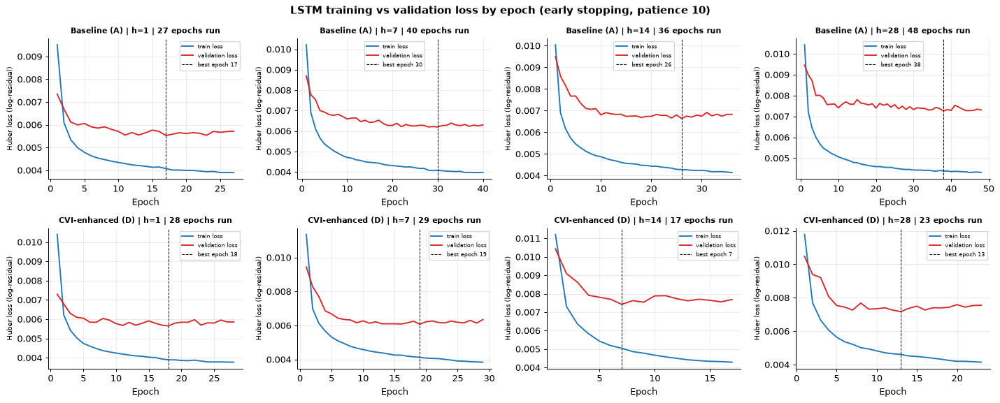

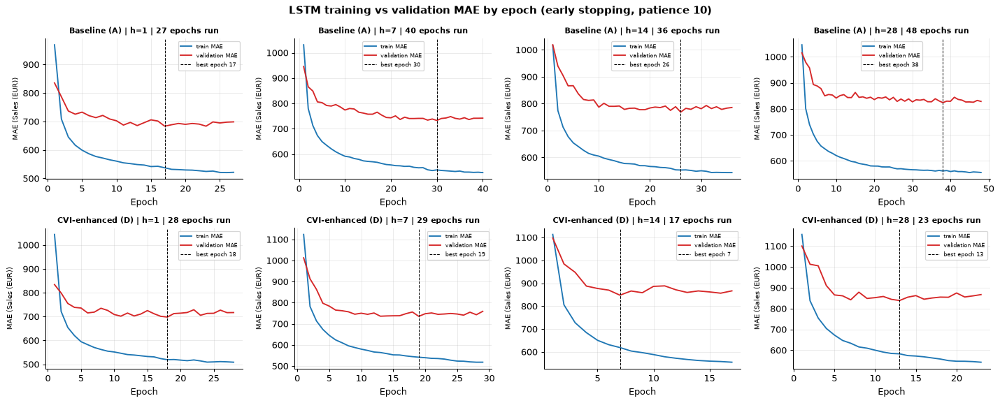

,model,cfg,h,epochs_run,best_epoch,stopped_early,best_val_loss,val_MAE_best,train_samples,minutes,checkpoint,n_params
0,LSTM,A,1,27,17,True,0.0055,683.4486,56202,5.4078,cvi_outputs\rossmann\checkpoints\lstm_A_h1.pt,59457
1,LSTM,D,1,28,18,True,0.0057,698.0388,56202,5.8790,cvi_outputs\rossmann\checkpoints\lstm_D_h1.pt,60993
2,LSTM,A,7,40,30,True,0.0062,732.8546,56202,8.1414,cvi_outputs\rossmann\checkpoints\lstm_A_h7.pt,59457
3,LSTM,D,7,29,19,True,0.0061,735.4498,56202,6.0532,cvi_outputs\rossmann\checkpoints\lstm_D_h7.pt,60993
4,LSTM,A,14,36,26,True,0.0066,768.7201,56202,7.2768,cvi_outputs\rossmann\checkpoints\lstm_A_h14.pt,59457
5,LSTM,D,14,17,7,True,0.0074,847.8893,56202,3.5651,cvi_outputs\rossmann\checkpoints\lstm_D_h14.pt,60993
6,LSTM,A,28,48,38,True,0.0073,824.0616,56202,9.7476,cvi_outputs\rossmann\checkpoints\lstm_A_h28.pt,59457
7,LSTM,D,28,23,13,True,0.0072,838.6929,56202,4.9451,cvi_outputs\rossmann\checkpoints\lstm_D_h28.pt,60993


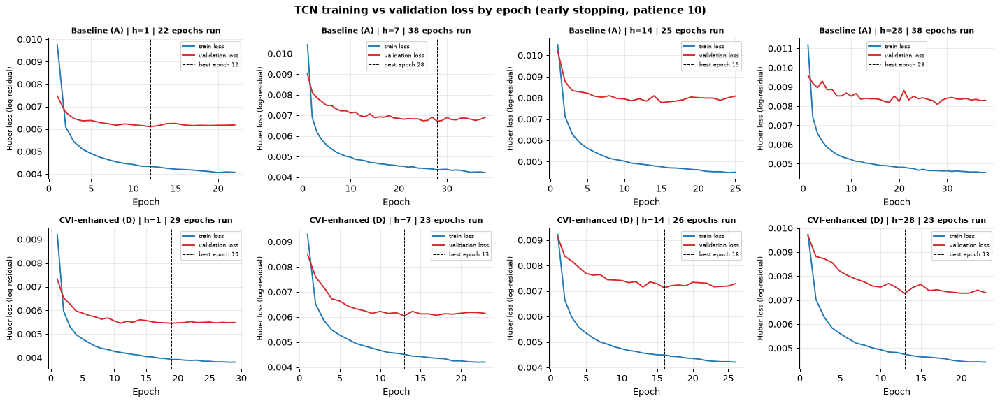

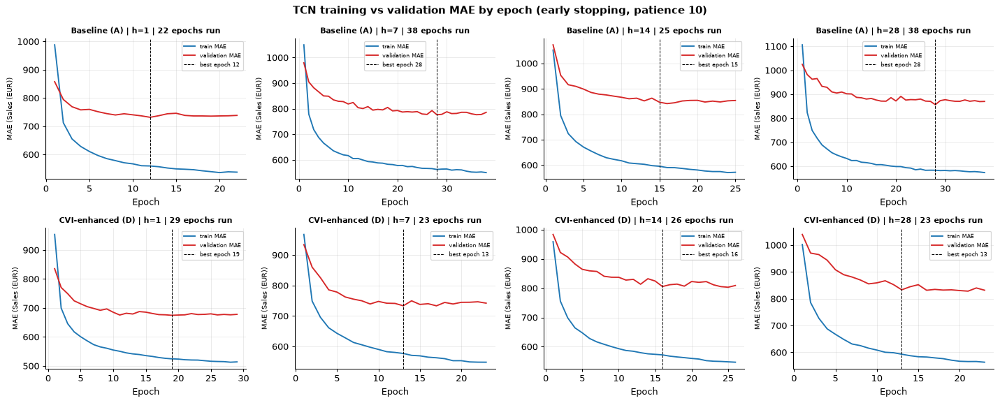

,model,cfg,h,epochs_run,best_epoch,stopped_early,best_val_loss,val_MAE_best,train_samples,minutes,checkpoint,n_params
0,TCN,A,1,22,12,True,0.0061,731.6912,56202,7.5528,cvi_outputs\rossmann\checkpoints\tcn_A_h1.pt,28129
1,TCN,D,1,29,19,True,0.0055,674.6718,56202,10.4033,cvi_outputs\rossmann\checkpoints\tcn_D_h1.pt,28897
2,TCN,A,7,38,28,True,0.0067,776.2699,56202,13.0350,cvi_outputs\rossmann\checkpoints\tcn_A_h7.pt,28129
3,TCN,D,7,23,13,True,0.0060,733.5039,56202,8.3279,cvi_outputs\rossmann\checkpoints\tcn_D_h7.pt,28897
4,TCN,A,14,25,15,True,0.0078,847.4475,56202,8.8032,cvi_outputs\rossmann\checkpoints\tcn_A_h14.pt,28129
5,TCN,D,14,26,16,True,0.0071,805.5727,56202,9.5374,cvi_outputs\rossmann\checkpoints\tcn_D_h14.pt,28897
6,TCN,A,28,38,28,True,0.0081,856.6527,56202,13.3167,cvi_outputs\rossmann\checkpoints\tcn_A_h28.pt,28129
7,TCN,D,28,23,13,True,0.0073,833.3273,56202,8.3531,cvi_outputs\rossmann\checkpoints\tcn_D_h28.pt,28897


In [ ]:
def plot_lstm_curves(ctx, kind='LSTM'):
    keys = [k for k in ctx['lstm_hist'] if k[0] == kind]
    if not keys:
        return None
    rows = []
    for metric, ylab, fname in [('loss', 'Huber loss (log-residual)', 'fig27_%s_loss_curves'), ('MAE', f"MAE ({ctx['sales_label']})", 'fig28_%s_mae_curves')]:
        fig, axs = plt.subplots(2, 4, figsize=(16, 6.5), sharex=False)
        for j, h in enumerate(CONFIG['horizons']):
            for i, cfg in enumerate(['A', 'D']):
                ax = axs[i, j]
                if (kind, cfg, h) not in ctx['lstm_hist']:
                    ax.set_visible(False); continue
                H = ctx['lstm_hist'][(kind, cfg, h)]
                be = int(H.loc[H.val_loss.idxmin(), 'epoch'])
                ax.plot(H.epoch, H[f'train_{metric}'], label=f'train {metric}', color='#1f77b4')
                ax.plot(H.epoch, H[f'val_{metric}'], label=f'validation {metric}', color='#d62728')
                ax.axvline(be, color='k', ls='--', lw=0.8, label=f'best epoch {be}')
                ax.set_title(f"{'Baseline (A)' if cfg == 'A' else 'CVI-enhanced (D)'} | h={h} | {len(H)} epochs run", fontsize=9)
                ax.set_xlabel('Epoch'); ax.set_ylabel(ylab, fontsize=8); ax.legend(fontsize=6.5)
        fig.suptitle(f'{kind} training vs validation {metric} by epoch (early stopping, patience {CONFIG["lstm"]["patience"]})', fontweight='bold')
        fig.tight_layout()
        save_fig(ctx, fig, fname % kind.lower(), f'{kind} {metric} learning curves.')
    return pd.DataFrame([i for i in ctx['model_info'] if i['model'] == kind])

display(plot_lstm_curves(R, 'LSTM'))
display(plot_lstm_curves(R, 'TCN'))

**Interpretation: learning curves (Figs. 27–28).**

* Training loss keeps falling while validation loss flattens after roughly 5–15 epochs. Early stopping halts training once the gap opens, which is the overfitting control the protocol asks for.
* The CVI-enhanced LSTMs reach their best validation loss **earlier** at h = 14 and h = 28 (best epochs 7 and 13, vs 26 and 38 for the baseline). The extra CVI channels let the network fit the training stores faster, but they generalise no better, as the test results confirm.
* The MAE curves (in EUR) follow the loss curves, so the log-space Huber objective and the reporting metric agree.

## 13. CVI ablation experiments and results

### 13.1 Evaluation of every model × configuration × horizon
Metrics are computed on the **test period**, once. `subset = all` means every eligible store. `subset = lstm_subset` restricts every model to the LSTM store sample. **Improvement** is always measured against the *same model's* config-A baseline on identical rows.

In [ ]:
def evaluate(ctx):
    rows = []
    sub_stores = set(ctx.get('lstm_stores', []))
    for (model, cfg, h), pr in ctx['preds'].items():
        F = ctx['frames'][h]
        for split in ['val', 'test']:
            p = pr.get(split)
            if p is None:
                continue
            Fs = F[split_mask(F, split)]
            y, st = Fs.y.to_numpy(float), Fs.store.to_numpy()
            ok = ~np.isnan(p)
            insub = Fs.store.isin(sub_stores).to_numpy()
            if ok.all():
                rows.append(dict(model=model, cfg=cfg, h=h, split=split, subset='all', **metrics(y, p, st)))
            if sub_stores:
                m = ok & insub
                rows.append(dict(model=model, cfg=cfg, h=h, split=split, subset='lstm_subset', **metrics(y[m], p[m], st[m])))
    res = pd.DataFrame(rows)
    base = res[res.cfg == 'A'][['model', 'h', 'split', 'subset', 'MAE', 'RMSE']].rename(columns={'MAE': 'MAE_A', 'RMSE': 'RMSE_A'})
    res = res.merge(base, on=['model', 'h', 'split', 'subset'], how='left')
    res['Improvement_%'] = 100 * (res.MAE_A - res.MAE) / res.MAE_A
    res['RMSE_Improvement_%'] = 100 * (res.RMSE_A - res.RMSE) / res.RMSE_A
    res.insert(0, 'dataset', ctx['name'])
    ctx['results'] = res
    return res

CFG_LABEL = {'A': 'Baseline', 'B': 'Baseline + CVI components', 'C': 'Baseline + composite CVI', 'D': 'Baseline + CVI',
             'E': 'Baseline + raw activity', 'C_dd': 'Baseline + data-driven CVI', 'P': 'Baseline + sales analogue',
             'ORACLE': 'ORACLE same-day activity (leaky)'}

def main_comparison_table(ctx):
    r = ctx['results']
    out = []
    for h in CONFIG['horizons']:
        for model in ['Ridge', 'RandomForest', 'LightGBM', 'LSTM', 'TCN']:
            for cfg in ['A', 'D']:
                q = r[(r.model == model) & (r.cfg == cfg) & (r.h == h) & (r.split == 'test')]
                q = q[q.subset == ('lstm_subset' if model in ('LSTM', 'TCN') else 'all')]
                if len(q):
                    q = q.iloc[0]
                    out.append({'Model': model, 'Feature configuration': CFG_LABEL[cfg], 'Horizon': f'{h} day' + ('s' if h > 1 else ''),
                                'Stores': 'LSTM subset' if model in ('LSTM', 'TCN') else 'all', 'MAE': q.MAE, 'RMSE': q.RMSE, 'WAPE_%': q.WAPE,
                                'R2': q.R2, 'Improvement_%': np.nan if cfg == 'A' else q['Improvement_%']})
    return pd.DataFrame(out)

R_res = run_step(R, 'evaluate', evaluate, R)
R_main = main_comparison_table(R)
md('**Required final comparison table: Rossmann (test period)**. Improvement % = (MAE_baseline − MAE_CVI) / MAE_baseline × 100; positive = CVI reduced error.')
display(R_main.style.format({'MAE': '{:,.1f}', 'RMSE': '{:,.1f}', 'WAPE_%': '{:.2f}', 'R2': '{:.4f}', 'Improvement_%': '{:+.2f}'}, na_rep='—'))

[OK] rossmann | evaluate | 30.3s


**Required final comparison table: Rossmann (test period)**. Improvement % = (MAE_baseline − MAE_CVI) / MAE_baseline × 100; positive = CVI reduced error.

,Model,Feature configuration,Horizon,Stores,MAE,RMSE,WAPE_%,R2,Improvement_%
0,Ridge,Baseline,1 day,all,724.1,"1,059.5",10.17,0.8803,—
1,Ridge,Baseline + CVI,1 day,all,721.5,"1,053.2",10.14,0.8817,+0.35
2,RandomForest,Baseline,1 day,all,565.9,844.7,7.95,0.9239,—
3,RandomForest,Baseline + CVI,1 day,all,557.6,834.6,7.83,0.9257,+1.47
4,LightGBM,Baseline,1 day,all,577.8,846.5,8.12,0.9236,—
5,LightGBM,Baseline + CVI,1 day,all,573.5,847.1,8.06,0.9235,+0.74
6,LSTM,Baseline,1 day,LSTM subset,579.2,838.6,7.76,0.9398,—
7,LSTM,Baseline + CVI,1 day,LSTM subset,563.1,811.6,7.55,0.9436,+2.78
8,TCN,Baseline,1 day,LSTM subset,578.7,833.3,7.76,0.9406,—
9,TCN,Baseline + CVI,1 day,LSTM subset,564.3,811.9,7.57,0.9436,+2.48


**Interpretation: the required Baseline vs Baseline + CVI comparison (Rossmann, test).**

| Model | h = 1 | h = 7 | h = 14 | h = 28 |
|---|---|---|---|---|
| LightGBM (primary) | +0.74 % | **+7.10 %** | **+3.10 %** | **+4.65 %** |
| Random Forest | +1.47 % | +3.80 % | +2.54 % | +2.77 % |
| Ridge | +0.35 % | +0.29 % | −0.44 % | −0.69 % |
| LSTM (150-store subset) | +2.78 % | +1.15 % | +1.63 % | −2.37 % |
| TCN (150-store subset) | +2.49 % | +6.82 % | +5.23 % | +0.69 % |

* The tree ensembles benefit consistently. The best absolute MAE is LightGBM-CVI at h ≥ 7 and Random-Forest-CVI at h = 1 (557.6 EUR).
* Ridge gains nothing: the CVI signal is non-linear or interaction-type, or already linear in the sales lags.
* The LSTM effect is small and changes sign at h = 28. The TCN effect is larger, and its pattern matches LightGBM.
* LSTM and TCN figures are on the store subset and are compared only with their own baselines (see the like-for-like subset table below).

In [ ]:
def config_table(ctx, model='LightGBM'):
    r = ctx['results']
    q = r[(r.model == model) & (r.split == 'test') & (r.subset == 'all')]
    t = q.pivot_table(index='cfg', columns='h', values='MAE')
    imp = q.pivot_table(index='cfg', columns='h', values='Improvement_%')
    order = [c for c in MAIN_CFGS + EXTRA_CFGS if c in t.index]
    t, imp = t.loc[order], imp.loc[order]
    t.columns = [f'MAE h={h}' for h in t.columns]; imp.columns = [f'Imp% h={h}' for h in imp.columns]
    out = pd.concat([t, imp], axis=1); out.insert(0, 'configuration', [CFG_LABEL.get(c, c.replace('A+', 'Baseline + ')) for c in out.index])
    return out

md('**LightGBM (primary): MAE and improvement vs baseline by feature configuration, test period**')
display(config_table(R).style.format({c: '{:,.1f}' for c in config_table(R).columns if c.startswith('MAE')} |
                                    {c: '{:+.2f}' for c in config_table(R).columns if c.startswith('Imp')}))
md('**Validation-period LightGBM MAE** (used only for design checks such as the composite-weighting comparison):')
_v = R['results'][(R['results'].model == 'LightGBM') & (R['results'].split == 'val') & (R['results'].subset == 'all')]
display(_v.pivot_table(index='cfg', columns='h', values='Improvement_%').round(2))
md('**All models on the LSTM store subset (like-for-like deep-learning comparison):**')
_s = R['results'][(R['results'].split == 'test') & (R['results'].subset == 'lstm_subset') & R['results'].cfg.isin(['A', 'D'])]
display(_s.pivot_table(index=['model', 'cfg'], columns='h', values='MAE').round(1))

**LightGBM (primary): MAE and improvement vs baseline by feature configuration, test period**

,configuration,MAE h=1,MAE h=7,MAE h=14,MAE h=28,Imp% h=1,Imp% h=7,Imp% h=14,Imp% h=28
cfg,,,,,,,,,
A,Baseline,577.8,660.6,652.5,667.8,+0.00,+0.00,+0.00,+0.00
B,Baseline + CVI components,570.2,617.6,631.1,639.4,+1.31,+6.52,+3.28,+4.25
C,Baseline + composite CVI,576.5,649.2,656.4,664.2,+0.23,+1.73,-0.59,+0.54
D,Baseline + CVI,573.5,613.7,632.3,636.7,+0.74,+7.10,+3.10,+4.65
E,Baseline + raw activity,572.1,646.2,649.4,660.1,+0.98,+2.18,+0.48,+1.14
C_dd,Baseline + data-driven CVI,577.4,647.8,654.2,656.6,+0.07,+1.94,-0.26,+1.67
P,Baseline + sales analogue,570.9,605.7,625.2,635.8,+1.19,+8.31,+4.19,+4.79
ORACLE,ORACLE same-day activity (leaky),415.0,440.2,441.8,433.6,+28.17,+33.37,+32.29,+35.07
A+c1_level,Baseline + c1_level,576.0,647.4,653.1,655.2,+0.31,+2.00,-0.09,+1.88


**Validation-period LightGBM MAE** (used only for design checks such as the composite-weighting comparison):

h,1,7,14,28
cfg,,,,
A,0.0000,0.0000,0.0000,0.0000
A+c1_level,3.1700,2.0800,0.6800,2.5900
A+c2_spend,2.3900,1.6900,1.0000,3.2200
A+c3_stability,1.9300,1.9900,0.5500,2.4100
A+c4_momentum,1.5700,-0.2000,0.2100,3.3600
A+c5_promo,2.0600,2.2900,3.5900,4.9300
B,3.4500,1.2000,5.1800,8.7600
C,2.7800,1.1000,-0.2000,0.9300
C_dd,1.3700,-0.2500,0.5000,2.3500


**All models on the LSTM store subset (like-for-like deep-learning comparison):**

h                         1          7          14         28
model         cfg                                            
LSTM          A     579.2000   633.9000   657.1000   638.7000
              D     563.1000   626.6000   646.4000   653.8000
LightGBM      A     593.5000   678.5000   670.6000   684.4000
              D     588.3000   631.7000   650.0000   654.8000
RandomForest  A     584.1000   665.8000   668.2000   680.9000
              D     575.4000   641.6000   652.4000   664.0000
Ridge         A     746.9000   751.4000   748.2000   793.9000
              D     743.7000   747.6000   752.1000   800.3000
SeasonalNaive A   1,301.2000 1,301.2000 1,202.5000 1,257.6000
TCN           A     578.7000   654.9000   655.9000   660.5000
              D     564.3000   610.3000   621.6000   656.0000

**Interpretation: feature-configuration ablation (LightGBM).**

* **Components beat the composite.** B (five components) gains +1.3 / +6.5 / +3.3 / +4.3 %. C (composite only) gains just +0.2 / +1.7 / −0.6 / +0.5 %, and the data-driven composite (C_dd) is no better. Adding the composite to the components (D) changes little compared with B.
* **Raw activity history (E)** helps only modestly (+1.0 / +2.2 / +0.5 / +1.1 %). The *way* the CVI summarises activity matters more than having activity data.
* **The sales-analogue control (P), which uses no customer data at all, matches or beats the CVI** (+1.2 / +8.3 / +4.2 / +4.8 %). The CVI gain is therefore mostly a feature-construction effect: deseasonalised stability, cycle-balanced momentum and promotion uplift. Customer counts add little beyond it (Section 18, post-hoc test).
* **The ORACLE** (same-day customers, leaky) would cut MAE by 28–35 %. No admissible method gets close, which confirms that the bulk of the customer signal is contemporaneous and unavailable at the forecast origin.
* **One component at a time:** every component alone gives roughly +1 to +2 % on average. Promotion responsiveness has the largest mean gain (+1.97 %), followed by momentum (+1.53 %). Level has the smallest (+1.02 %), consistent with its redundancy with the sales level.

### 13.2 Result figures: accuracy, horizons, configurations, residuals and explanations

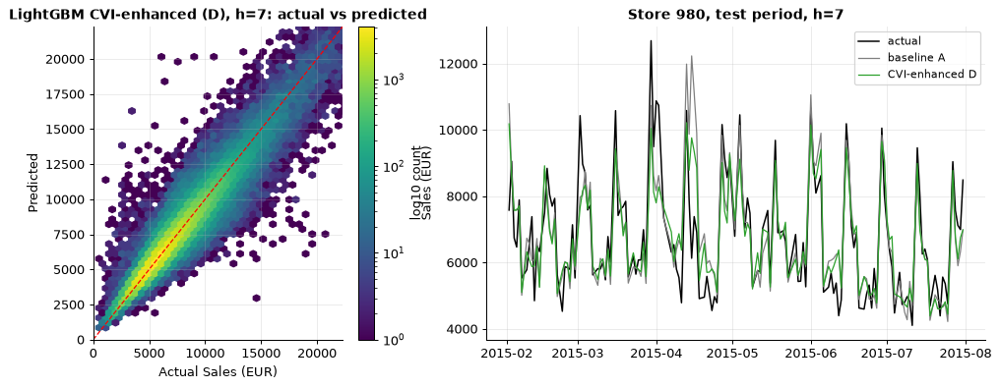

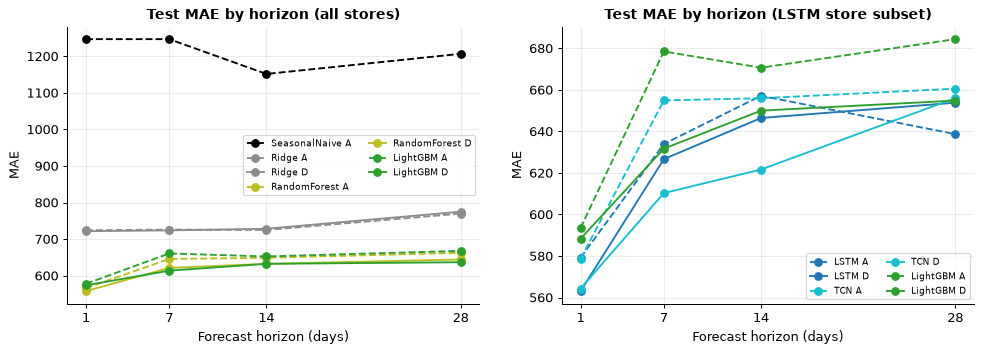

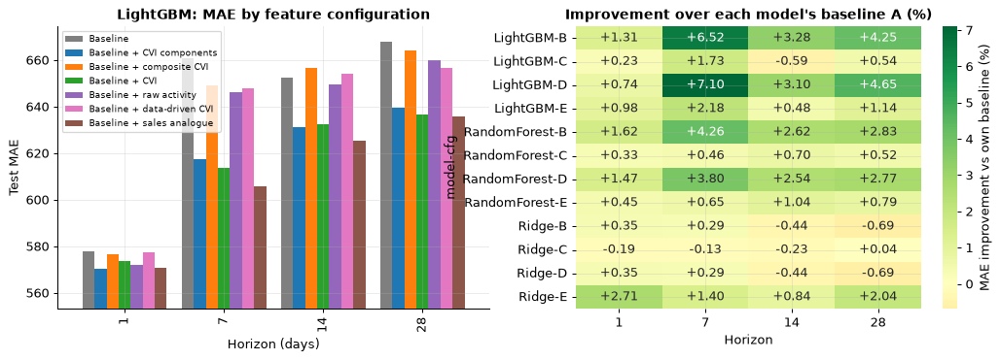

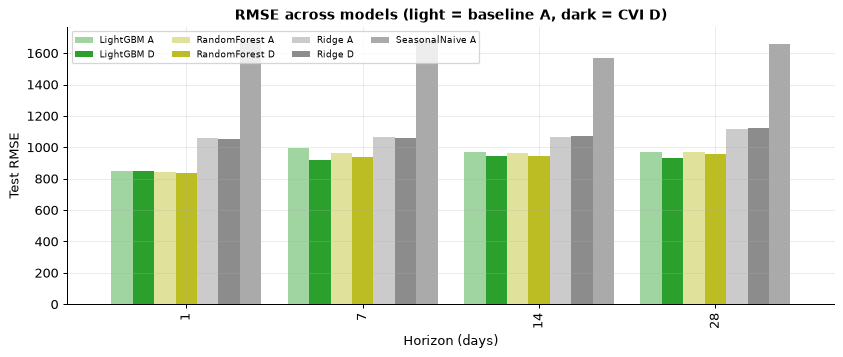

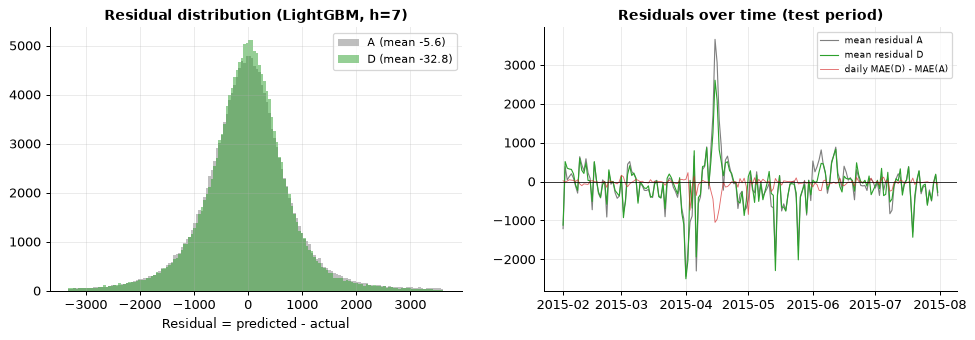

[OK] rossmann | result figures | 8.7s


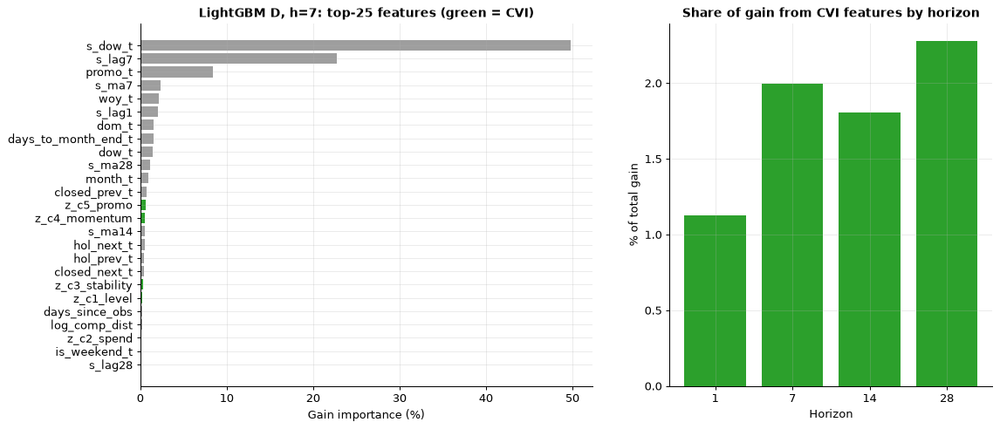

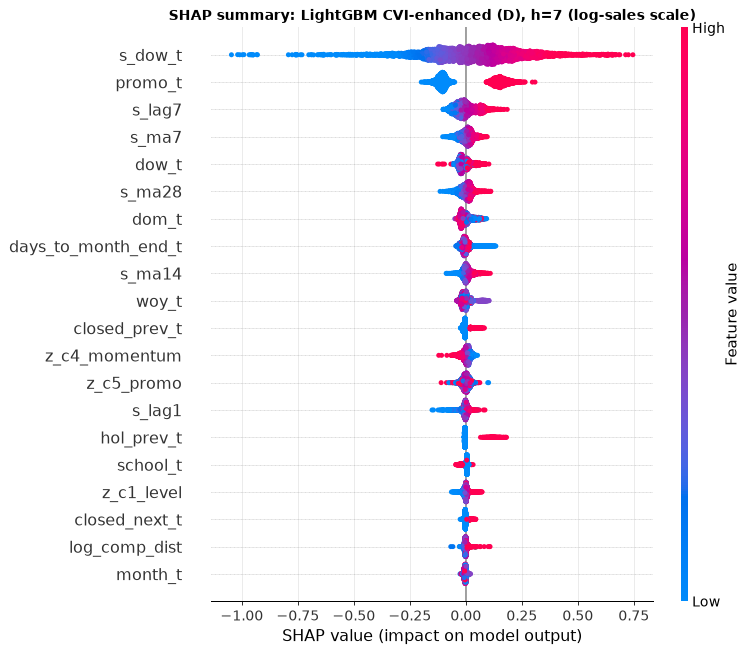

[OK] rossmann | importance & SHAP | 72.6s


,mean|SHAP|,is_CVI
s_dow_t,0.1753,False
promo_t,0.1305,False
s_lag7,0.0373,False
s_ma7,0.0215,False
dow_t,0.0211,False
s_ma28,0.0199,False
dom_t,0.0193,False
days_to_month_end_t,0.0152,False
s_ma14,0.0149,False
woy_t,0.0143,False


C:\Users\Pc Planet\AppData\Local\Temp\ipykernel_18624\2019297612.py:114: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  q['mean'] = q.mean(1)


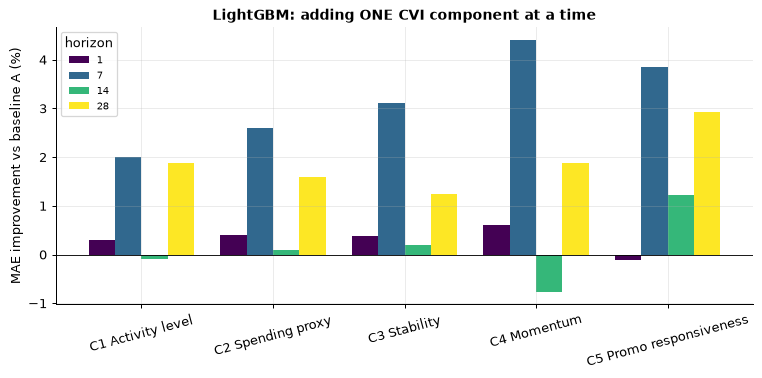

[OK] rossmann | component ablation | 0.9s


h,1,7,14,28,mean
C1 Activity level,0.3060,2.0000,-0.0890,1.8810,1.0250
C2 Spending proxy,0.4120,2.6080,0.0940,1.5940,1.1770
C3 Stability,0.3850,3.1150,0.1960,1.2360,1.2330
C4 Momentum,0.6020,4.4090,-0.7630,1.8870,1.5340
C5 Promo responsiveness,-0.1180,3.8550,1.2280,2.9290,1.9740


In [ ]:
def result_figures(ctx):
    r = ctx['results']; te = r[(r.split == 'test')]
    H = CONFIG['horizons']
    # Actual vs predicted (LightGBM D, h=7)
    h0 = 7 if 7 in H else H[0]
    F = ctx['frames'][h0]; Ft = F[split_mask(F, 'test')].reset_index(drop=True)
    pA, pD = ctx['preds'][('LightGBM', 'A', h0)]['test'], ctx['preds'][('LightGBM', 'D', h0)]['test']
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 1.6]})
    hb = axs[0].hexbin(Ft.y, pD, gridsize=70, bins='log', cmap='viridis', mincnt=1); plt.colorbar(hb, ax=axs[0], label='log10 count')
    lim = np.nanpercentile(Ft.y, 99.8); axs[0].plot([0, lim], [0, lim], 'r--', lw=1); axs[0].set_xlim(0, lim); axs[0].set_ylim(0, lim)
    axs[0].set_xlabel(f"Actual {ctx['sales_label']}"); axs[0].set_ylabel('Predicted'); axs[0].set_title(f'LightGBM CVI-enhanced (D), h={h0}: actual vs predicted')
    s0 = Ft.groupby('store').y.mean().sort_values().index[len(Ft.store.unique()) // 2]
    e = Ft.index[Ft.store == s0]
    axs[1].plot(Ft.date[e], Ft.y[e], 'k-', lw=1.2, label='actual'); axs[1].plot(Ft.date[e], pA[e], color=PALETTE['A'], lw=1, label='baseline A')
    axs[1].plot(Ft.date[e], pD[e], color=PALETTE['D'], lw=1, label='CVI-enhanced D'); axs[1].legend(); axs[1].set_title(f'Store {s0}, test period, h={h0}')
    axs[1].set_ylabel(ctx['sales_label'])
    save_fig(ctx, fig, 'fig29_actual_vs_predicted', 'Actual vs predicted sales.')
    # Performance by horizon
    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    for model in ['SeasonalNaive', 'Ridge', 'RandomForest', 'LightGBM']:
        for cfg, ls_ in [('A', '--'), ('D', '-')]:
            q = te[(te.model == model) & (te.cfg == cfg) & (te.subset == 'all')].sort_values('h')
            if len(q):
                axs[0].plot(q.h, q.MAE, ls_, marker='o', color=MODEL_COLORS.get(model, 'k'), label=f'{model} {cfg}')
    for model in ['LSTM', 'TCN', 'LightGBM']:
        for cfg, ls_ in [('A', '--'), ('D', '-')]:
            q = te[(te.model == model) & (te.cfg == cfg) & (te.subset == 'lstm_subset')].sort_values('h')
            if len(q):
                axs[1].plot(q.h, q.MAE, ls_, marker='o', color=MODEL_COLORS.get(model, 'k'), label=f'{model} {cfg}')
    axs[0].set_title('Test MAE by horizon (all stores)'); axs[1].set_title('Test MAE by horizon (LSTM store subset)')
    for ax in axs: ax.set_xlabel('Forecast horizon (days)'); ax.set_ylabel('MAE'); ax.set_xticks(H); ax.legend(fontsize=7, ncol=2)
    save_fig(ctx, fig, 'fig30_performance_by_horizon', 'Forecasting performance by horizon (dashed = baseline A, solid = CVI D).')
    # MAE across feature configurations (LightGBM)
    q = te[(te.model == 'LightGBM') & (te.subset == 'all') & te.cfg.isin(MAIN_CFGS + ['C_dd', 'P'])]
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
    piv = q.pivot_table(index='h', columns='cfg', values='MAE')[[c for c in MAIN_CFGS + ['C_dd', 'P'] if c in q.cfg.unique()]]
    piv.plot.bar(ax=axs[0], color=[PALETTE[c] for c in piv.columns], width=0.85)
    axs[0].set_ylim(piv.values.min() * 0.97, piv.values.max() * 1.01); axs[0].set_ylabel('Test MAE'); axs[0].set_xlabel('Horizon (days)')
    axs[0].set_title('LightGBM: MAE by feature configuration'); axs[0].legend([CFG_LABEL[c] for c in piv.columns], fontsize=7)
    hm = te[(te.subset == 'all') & te.cfg.isin(['B', 'C', 'D', 'E']) & te.model.isin(['Ridge', 'RandomForest', 'LightGBM'])]
    hm = hm.pivot_table(index=['model', 'cfg'], columns='h', values='Improvement_%')
    sns.heatmap(hm, annot=True, fmt='+.2f', cmap='RdYlGn', center=0, ax=axs[1], cbar_kws={'label': 'MAE improvement vs own baseline (%)'})
    axs[1].set_title('Improvement over each model\'s baseline A (%)'); axs[1].set_xlabel('Horizon')
    save_fig(ctx, fig, 'fig31_mae_feature_configurations', 'MAE comparison across feature configurations.')
    # RMSE across models
    q = te[te.cfg.isin(['A', 'D']) & (te.subset == 'all') & te.model.isin(['SeasonalNaive', 'Ridge', 'RandomForest', 'LightGBM'])]
    fig, ax = plt.subplots(figsize=(11, 4))
    piv = q.pivot_table(index='h', columns=['model', 'cfg'], values='RMSE')
    piv.plot.bar(ax=ax, width=0.85, color=[MODEL_COLORS.get(m, '#444') if c == 'D' else matplotlib.colors.to_rgba(MODEL_COLORS.get(m, '#444'), 0.45) for m, c in piv.columns])
    ax.set_ylabel('Test RMSE'); ax.set_xlabel('Horizon (days)'); ax.set_title('RMSE across models (light = baseline A, dark = CVI D)')
    ax.legend([f'{m} {c}' for m, c in piv.columns], fontsize=7, ncol=4)
    save_fig(ctx, fig, 'fig32_rmse_across_models', 'RMSE comparison across models.')
    # Residuals
    resA, resD = pA - Ft.y.values, pD - Ft.y.values
    fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
    lo, hi = np.percentile(np.r_[resA, resD], [0.5, 99.5])
    axs[0].hist(resA, bins=150, range=(lo, hi), alpha=0.5, color=PALETTE['A'], label=f'A (mean {resA.mean():.1f})')
    axs[0].hist(resD, bins=150, range=(lo, hi), alpha=0.5, color=PALETTE['D'], label=f'D (mean {resD.mean():.1f})')
    axs[0].set_xlabel('Residual = predicted - actual'); axs[0].set_title(f'Residual distribution (LightGBM, h={h0})'); axs[0].legend()
    dd = pd.DataFrame({'date': Ft.date, 'rA': resA, 'rD': resD, 'aA': np.abs(resA), 'aD': np.abs(resD)}).groupby('date').mean()
    axs[1].plot(dd.index, dd.rA, color=PALETTE['A'], lw=0.9, label='mean residual A'); axs[1].plot(dd.index, dd.rD, color=PALETTE['D'], lw=0.9, label='mean residual D')
    axs[1].plot(dd.index, dd.aD - dd.aA, color='#d62728', lw=0.7, alpha=0.7, label='daily MAE(D) - MAE(A)')
    axs[1].axhline(0, color='k', lw=0.6); axs[1].legend(fontsize=7); axs[1].set_title('Residuals over time (test period)')
    save_fig(ctx, fig, 'fig33_residuals', 'Residual distribution and residuals over time.')
    return None

def importance_figures(ctx):
    models = ctx.get('lgb_models', {})
    h0 = 7 if 7 in CONFIG['horizons'] else CONFIG['horizons'][0]
    if ('D', h0) not in models:
        raise RuntimeError('LightGBM D model not available')
    bst = models[('D', h0)]
    gi = pd.Series(bst.feature_importance('gain'), index=bst.feature_name()).sort_values()
    gi = gi / gi.sum() * 100
    share = {}
    for h in CONFIG['horizons']:
        if ('D', h) in models:
            g = pd.Series(models[('D', h)].feature_importance('gain'), index=models[('D', h)].feature_name())
            share[h] = 100 * g[[c for c in COMP + ['cvi_eq']]].sum() / g.sum()
    fig, axs = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1.4, 1]})
    top = gi.tail(25)
    axs[0].barh(top.index, top.values, color=['#2ca02c' if (c in COMP or c == 'cvi_eq') else '#9e9e9e' for c in top.index])
    axs[0].set_xlabel('Gain importance (%)'); axs[0].set_title(f'LightGBM D, h={h0}: top-25 features (green = CVI)')
    axs[1].bar([str(h) for h in share], list(share.values()), color='#2ca02c'); axs[1].set_xlabel('Horizon'); axs[1].set_ylabel('% of total gain')
    axs[1].set_title('Share of gain from CVI features by horizon')
    save_fig(ctx, fig, 'fig34_feature_importance', 'Feature importance.')
    # SHAP
    F = ctx['frames'][h0]; Xt = F.loc[split_mask(F, 'test'), bst.feature_name()]
    Xs = Xt.sample(min(CONFIG['shap_rows'], len(Xt)), random_state=CONFIG['seed'])
    if HAS_SHAP:
        sv = shap.TreeExplainer(bst).shap_values(Xs)
    else:
        sv = bst.predict(Xs, pred_contrib=True)[:, :-1]
    plt.figure()
    if HAS_SHAP:
        shap.summary_plot(sv, Xs, max_display=20, show=False)
        fig = plt.gcf(); fig.set_size_inches(9, 7); plt.title(f'SHAP summary: LightGBM CVI-enhanced (D), h={h0} (log-sales scale)')
    else:
        fig, ax = plt.subplots(figsize=(9, 7))
        o = np.argsort(np.abs(sv).mean(0))[-20:]
        for k, j in enumerate(o):
            ax.scatter(sv[:, j], np.full(len(sv), k) + np.random.uniform(-0.3, 0.3, len(sv)), c=stats.rankdata(Xs.iloc[:, j]), s=3, cmap='coolwarm')
        ax.set_yticks(range(len(o))); ax.set_yticklabels(Xs.columns[o]); ax.set_xlabel('SHAP value')
    save_fig(ctx, fig, 'fig35_shap_summary', 'SHAP summary plot.')
    mabs = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values(ascending=False)
    ctx['shap_mean_abs'] = mabs
    ctx['cvi_gain_share'] = share
    return pd.DataFrame({'mean|SHAP|': mabs.head(15), 'is_CVI': [c in COMP or c == 'cvi_eq' for c in mabs.head(15).index]})

def component_figure(ctx):
    r = ctx['results']; te = r[(r.split == 'test') & (r.model == 'LightGBM') & (r.subset == 'all')]
    q = te[te.cfg.str.startswith('A+')].pivot_table(index='cfg', columns='h', values='Improvement_%')
    q.index = [COMP_NAMES['z_' + c.replace('A+', '')] for c in q.index]
    q['mean'] = q.mean(1)
    fig, ax = plt.subplots(figsize=(10, 4))
    q.drop(columns='mean').plot.bar(ax=ax, width=0.8, colormap='viridis'); ax.axhline(0, color='k', lw=0.7)
    ax.set_ylabel('MAE improvement vs baseline A (%)'); ax.set_title('LightGBM: adding ONE CVI component at a time'); ax.tick_params(axis='x', rotation=15)
    ax.legend(title='horizon', fontsize=8)
    save_fig(ctx, fig, 'fig36_single_component_ablation', 'Single-component ablation.')
    ctx['component_gain'] = q
    return q.round(3)

run_step(R, 'result figures', result_figures, R)
display(run_step(R, 'importance & SHAP', importance_figures, R))
display(run_step(R, 'component ablation', component_figure, R))

**Interpretation: feature importance and SHAP (Figs. 34–35).**

* The forecast is driven by the same-weekday sales history (`s_dow_t`), the planned promotion and the recent sales lags.
* CVI features enter as **secondary** contributors. Momentum and promotion responsiveness are the CVI features ranked highest by SHAP, with **only 1.1–2.3 % of total gain**. That share rises with the horizon (1.1 % at h = 1, 2.3 % at h = 28), consistent with H3 being reversed.
* SHAP shows that high recent momentum *lowers* the h = 7 forecast. Once the sales lags are known, a recent surge in traffic predicts some reversion, which is consistent with the fortnightly promotion rhythm seen in the EDA.

**Interpretation: result figures (Figs. 29–33).**

* Actual-vs-predicted points cluster tightly around the diagonal (R² = 0.910 at h = 7).
* MAE rises from h = 1 to h = 7, then flattens. Beyond a week, additional horizon costs little because the weekly and promotion calendar is known in advance.
* Residuals are nearly symmetric, and the bias is negligible: within ±33 EUR per store-day, |bias| ≤ 0.5 % of sales, for both A and D.
* The daily MAE(D) − MAE(A) series shows that the CVI gain is **concentrated on particular days**, around promotion switches and holidays, not spread evenly over the test period.

### 13.3 Expanding-window rolling-origin cross-validation (LightGBM, A vs D)
The development period is cut into three consecutive evaluation blocks of about two months each, all inside validation. For each fold, the model is trained on every target dated before the block, the CVI standardisation and weights are **re-fitted on that fold's training window**, and the boosting rounds are fixed at the value early stopping chose for that configuration and horizon. This checks that the A-vs-D contrast is not an artefact of a single split. The test period is not touched.

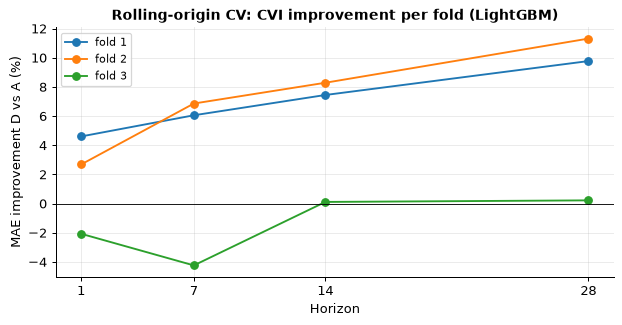

[OK] rossmann | rolling-origin CV | 1271.6s


cfg,fold,h,A,D,Improvement_%
0,1,1,502.8161,479.6541,4.6065
1,1,7,558.5923,524.7537,6.0578
2,1,14,570.9701,528.4366,7.4493
3,1,28,626.9596,565.6798,9.7741
4,2,1,531.3888,517.1193,2.6853
5,2,7,609.6630,567.8212,6.8631
6,2,14,630.4717,578.2128,8.2889
7,2,28,722.5248,640.7696,11.3152
8,3,1,758.1833,773.8563,-2.0672
9,3,7,874.6809,911.7337,-4.2362


In [ ]:
def rolling_origin_cv(ctx):
    sp = ctx['splits']
    blocks = pd.date_range(sp['val_start'], sp['val_end'] + pd.Timedelta(days=1), periods=CONFIG['cv_folds'] + 1)
    info = pd.DataFrame(ctx['model_info']); info = info[info.model == 'LightGBM']
    T = build_targets(ctx)
    rows = []
    for k in range(CONFIG['cv_folds']):
        f_start, f_end = blocks[k].normalize(), (blocks[k + 1] - pd.Timedelta(days=1)).normalize()
        fit_end = f_start - pd.Timedelta(days=1)
        S = ctx['state'].copy()
        fit_cvi(S, fit_end, CONFIG['min_history'])
        for h in CONFIG['horizons']:
            F = build_frame(T, S, h)
            keys = ctx['frames'][h][['store', 'date']]
            F = F.merge(keys, on=['store', 'date'], how='inner')
            mtr = ((F.date >= sp['train_start']) & (F.date <= fit_end)).values
            mte = ((F.date >= f_start) & (F.date <= f_end)).values
            frames = {h: F}
            for cfg in ['A', 'D']:
                it = int(info[(info.cfg == cfg) & (info.h == h)].best_iter.iloc[0])
                bst = lgb_train(ctx, h, ctx['feature_sets'][cfg], ctx['lgb_params'], None, fixed_rounds=it, frames=frames, masks=(mtr, None))
                p = inv(bst.predict(F.loc[mte, ctx['feature_sets'][cfg]]))
                rows.append(dict(fold=k + 1, eval_start=f_start.date(), eval_end=f_end.date(), train_end=fit_end.date(), h=h, cfg=cfg,
                                 MAE=float(np.mean(np.abs(p - F.y.values[mte]))), n=int(mte.sum())))
    cv = pd.DataFrame(rows)
    w = cv.pivot_table(index=['fold', 'h'], columns='cfg', values='MAE').reset_index()
    w['Improvement_%'] = 100 * (w.A - w.D) / w.A
    ctx['cv'] = w
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for f, g in w.groupby('fold'):
        ax.plot(g.h, g['Improvement_%'], marker='o', label=f'fold {f}')
    ax.axhline(0, color='k', lw=0.7); ax.set_xticks(CONFIG['horizons']); ax.set_xlabel('Horizon'); ax.set_ylabel('MAE improvement D vs A (%)')
    ax.set_title('Rolling-origin CV: CVI improvement per fold (LightGBM)'); ax.legend()
    save_fig(ctx, fig, 'fig37_rolling_origin_cv', 'Expanding-window CV.')
    return w

display(run_step(R, 'rolling-origin CV', rolling_origin_cv, R))

**Interpretation: rolling-origin CV.**

* In the first two folds (August to November 2014) the CVI model beats the baseline at every horizon, by 2.7–11.3 %.
* In the third fold (December 2014 to January 2015, the Christmas season) the gain disappears or reverses: −2.1 % at h = 1, −4.2 % at h = 7, and about 0 at h = 14 and h = 28.

The benefit is **episodic and season-dependent**, not uniform. This is an important caveat on the test-period result.

## 14. Store segmentation and customer-behaviour analysis

The store profiles are averages of the **training-period** as-of state: activity level, stability, spending proxy, momentum, promotion responsiveness and composite CVI. They are standardised across stores, so the test period plays no part in the segmentation.

* **Number of clusters:** k-means is run for k = 2…8 (20 initialisations). The pre-specified rule is to take the k with the **highest silhouette in 3–6**, so that the segments stay interpretable. The global silhouette maximum is reported too.
* **Cluster names:** each name is generated mechanically from the cluster's profile, using every feature whose mean z is ≥ 0.5 in absolute value. No business label is assigned by hand.
* **Sales-only comparator:** the same procedure is run on a sales-only profile (sales level, sales stability, sales momentum, sales promotion uplift). The Adjusted Rand Index (ARI) between the two segmentations shows whether CVI produces a different grouping (H6).
* **Forecast benefit by segment:** per-store test MAE improvement of LightGBM D over A is compared across segments (H4).

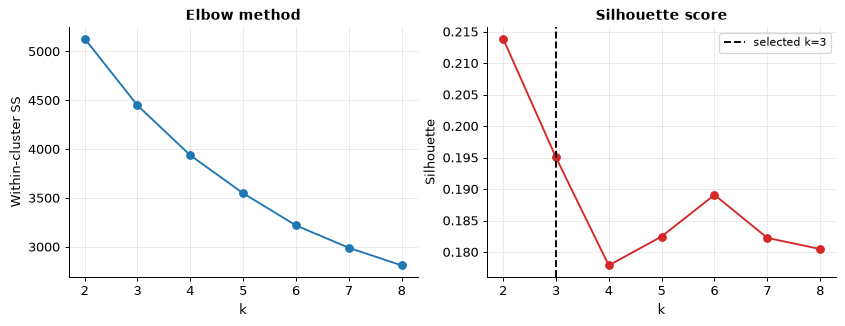

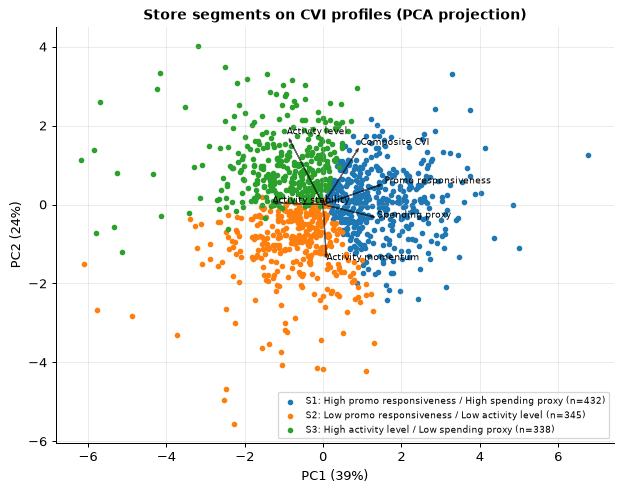

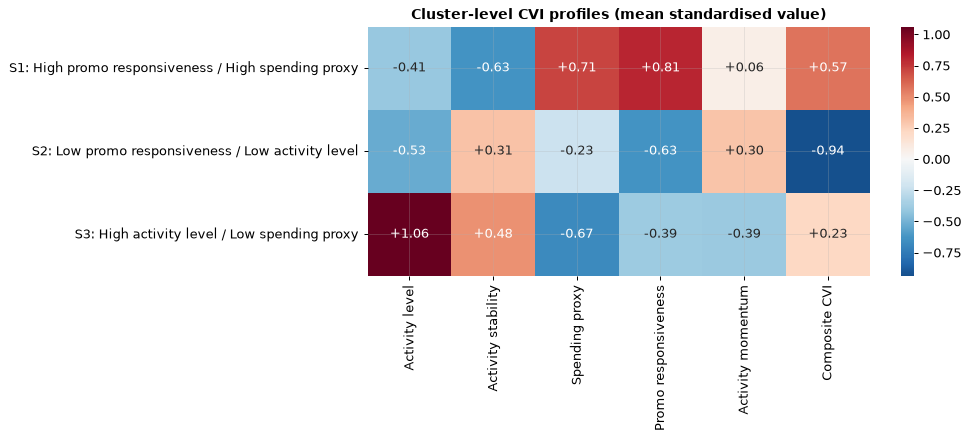

[OK] rossmann | segmentation | 12.9s


,k,inertia,silhouette
0,2,"5,130.5782",0.2139
1,3,"4,447.7959",0.1950
2,4,"3,936.3823",0.1779
3,5,"3,548.3097",0.1825
4,6,"3,218.9120",0.1891
5,7,"2,990.1055",0.1822
6,8,"2,809.5977",0.1805


,Activity level,Activity stability,Spending proxy,Promo responsiveness,Activity momentum,Composite CVI
S1: High promo responsiveness / High spending proxy,-0.4100,-0.6300,0.7100,0.8100,0.0600,0.5700
S2: Low promo responsiveness / Low activity level,-0.5300,0.3100,-0.2300,-0.6300,0.3000,-0.9400
S3: High activity level / Low spending proxy,1.0600,0.4800,-0.6700,-0.3900,-0.3900,0.2300


{'k': 3, 'silhouette': 0.19503075303355044, 'best_k_global': 2, 'ari_vs_sales_only': 0.3270976800157725, 'sales_only_silhouette': 0.2543548385243583, 'all_clusters_distinct': True, 'sizes': {'S1: High promo responsiveness / High spending proxy': 432, 'S2: Low promo responsiveness / Low activity level': 345, 'S3: High activity level / Low spending proxy': 338}}


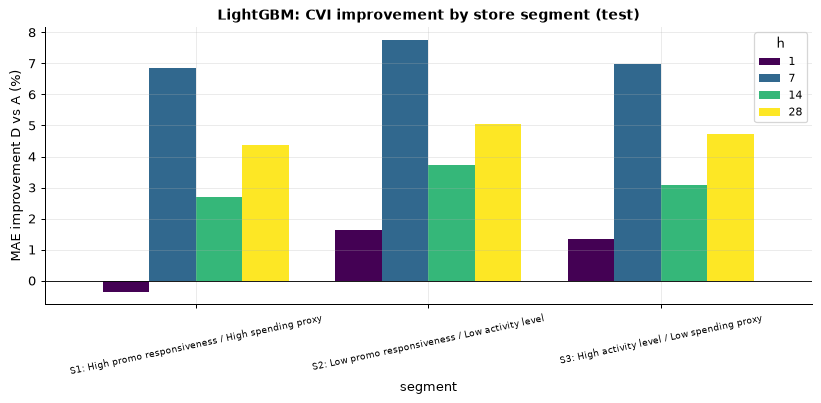

[OK] rossmann | segment performance | 1.9s


,h,segment,stores,pooled_imp_pct,median_store_imp_pct,win_rate_pct,MAE_A,MAE_D
0,1,S1: High promo responsiveness / High spending ...,432,-0.3500,-0.4700,45.6000,586.0500,588.1200
1,1,S2: Low promo responsiveness / Low activity level,345,1.6200,1.0000,59.1300,466.3600,458.8100
2,1,S3: High activity level / Low spending proxy,338,1.3400,1.1000,57.4000,679.4400,670.3100
3,7,S1: High promo responsiveness / High spending ...,432,6.8400,6.7800,95.1400,672.2200,626.2700
4,7,S2: Low promo responsiveness / Low activity level,345,7.7600,7.1500,96.2300,529.8600,488.7100
5,7,S3: High activity level / Low spending proxy,338,6.9700,7.1100,92.9000,777.5800,723.4200
6,14,S1: High promo responsiveness / High spending ...,432,2.7100,2.4600,74.0700,667.3400,649.2900
7,14,S2: Low promo responsiveness / Low activity level,345,3.7400,3.1100,83.1900,522.6200,503.0600
8,14,S3: High activity level / Low spending proxy,338,3.0800,2.1200,74.5600,764.5500,741.0100
9,28,S1: High promo responsiveness / High spending ...,432,4.3600,4.2500,84.0300,681.5300,651.8400


,h,kruskal_p_CVI_segments,kruskal_p_sales_segments,kruskal_p_holm
0,1,0.0000,0.0000,0.0000
1,7,0.1325,0.0110,0.2649
2,14,0.0014,0.0000,0.0043
3,28,0.4861,0.0000,0.4861


In [ ]:
SEG_FEATS = {'z_c1_level': 'Activity level', 'z_c3_stability': 'Activity stability', 'z_c2_spend': 'Spending proxy',
             'z_c5_promo': 'Promo responsiveness', 'z_c4_momentum': 'Activity momentum', 'cvi_eq': 'Composite CVI'}
SALES_SEG = {'s_ma28': 'Sales level', 'p_stability': 'Sales stability', 'p_momentum': 'Sales momentum', 'p_promo': 'Sales promo uplift'}

def cluster_profiles(prof, kmin=2, kmax=8):
    Z = StandardScaler().fit_transform(prof.values)
    rows, labels = [], {}
    for k in range(kmin, min(kmax, len(prof) - 1) + 1):
        km = KMeans(n_clusters=k, n_init=20, random_state=CONFIG['seed']).fit(Z)
        rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(Z, km.labels_)))
        labels[k] = km.labels_
    sel = pd.DataFrame(rows)
    cand = sel[(sel.k >= 3) & (sel.k <= 6)]
    k_star = int(cand.loc[cand.silhouette.idxmax(), 'k'])
    return Z, sel, labels, k_star

def name_cluster(zrow, names):
    parts = [(('High ' if v > 0 else 'Low ') + names[c].lower(), abs(v)) for c, v in zrow.items() if abs(v) >= 0.5 and c != 'cvi_eq']
    parts = [p for p, _ in sorted(parts, key=lambda t: -t[1])][:2]
    return ' / '.join(parts) if parts else 'Average profile'

def segmentation(ctx):
    S, sp = ctx['state'], ctx['splits']
    tr = S[(S.date <= sp['train_end']) & (S.n_obs >= CONFIG['min_history'])]
    prof = tr.groupby('store')[list(SEG_FEATS)].mean().dropna()
    Z, sel, labels, k = cluster_profiles(prof)
    lab = labels[k]
    zprof = pd.DataFrame(Z, index=prof.index, columns=prof.columns)
    cprof = zprof.groupby(lab).mean()
    names = {c: f'S{c + 1}: ' + name_cluster(cprof.loc[c], SEG_FEATS) for c in cprof.index}
    seg = pd.Series([names[l] for l in lab], index=prof.index, name='segment')
    # sales-only comparator
    sprof = tr.groupby('store')[list(SALES_SEG)].mean().reindex(prof.index).dropna()
    Zs = StandardScaler().fit_transform(sprof.values)
    lab_s = KMeans(n_clusters=k, n_init=20, random_state=CONFIG['seed']).fit_predict(Zs)
    ari = adjusted_rand_score(pd.Series(lab, index=prof.index).reindex(sprof.index), lab_s)
    sil_s = silhouette_score(Zs, lab_s)
    ctx['segments'] = seg; ctx['segments_sales'] = pd.Series(lab_s, index=sprof.index)
    # figures
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
    axs[0].plot(sel.k, sel.inertia, marker='o'); axs[0].set_xlabel('k'); axs[0].set_ylabel('Within-cluster SS'); axs[0].set_title('Elbow method')
    axs[1].plot(sel.k, sel.silhouette, marker='o', color='#d62728'); axs[1].axvline(k, ls='--', color='k', label=f'selected k={k}')
    axs[1].set_xlabel('k'); axs[1].set_ylabel('Silhouette'); axs[1].set_title('Silhouette score'); axs[1].legend()
    save_fig(ctx, fig, 'fig38_cluster_selection', 'Elbow and silhouette.')
    pca = PCA(2, random_state=CONFIG['seed']).fit(Z); P2 = pca.transform(Z)
    fig, ax = plt.subplots(figsize=(8, 6))
    for c in sorted(set(lab)):
        m = lab == c
        ax.scatter(P2[m, 0], P2[m, 1], s=12, label=f'{names[c]} (n={m.sum()})')
    for j, f in enumerate(prof.columns):
        ax.arrow(0, 0, pca.components_[0, j] * 2.5, pca.components_[1, j] * 2.5, color='k', alpha=0.6, head_width=0.06)
        ax.text(pca.components_[0, j] * 2.8, pca.components_[1, j] * 2.8, SEG_FEATS[f], fontsize=7)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0] * 100:.0f}%)'); ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1] * 100:.0f}%)')
    ax.set_title('Store segments on CVI profiles (PCA projection)'); ax.legend(fontsize=7)
    save_fig(ctx, fig, 'fig39_store_clusters_pca', 'Store clustering visualisation.')
    fig, ax = plt.subplots(figsize=(9, 0.6 * k + 1.8))
    sns.heatmap(cprof.rename(columns=SEG_FEATS, index=names), annot=True, fmt='+.2f', cmap='RdBu_r', center=0, ax=ax)
    ax.set_title('Cluster-level CVI profiles (mean standardised value)'); ax.set_ylabel('')
    save_fig(ctx, fig, 'fig40_cluster_cvi_profiles', 'Cluster-level CVI profiles.')
    distinct = bool((cprof.drop(columns='cvi_eq').abs().max(axis=1) >= 0.5).all())
    sil = float(sel.loc[sel.k == k, 'silhouette'].iloc[0])
    ctx['seg_summary'] = dict(k=k, silhouette=sil, best_k_global=int(sel.loc[sel.silhouette.idxmax(), 'k']),
                              ari_vs_sales_only=float(ari), sales_only_silhouette=float(sil_s), all_clusters_distinct=distinct,
                              sizes=seg.value_counts().to_dict())
    return sel, cprof.rename(columns=SEG_FEATS, index=names), ctx['seg_summary']

def per_store_errors(ctx, model, cfg, h, split='test'):
    F = ctx['frames'][h]; Fs = F[split_mask(F, split)]
    p = ctx['preds'][(model, cfg, h)][split]
    ok = ~np.isnan(p)
    return pd.DataFrame({'store': Fs.store.values[ok], 'ae': np.abs(p[ok] - Fs.y.values[ok])}).groupby('store').ae.mean()

def segment_performance(ctx):
    seg = ctx['segments']; rows = []; kw = []
    segs_sales = ctx['segments_sales']
    for h in CONFIG['horizons']:
        a, d = per_store_errors(ctx, 'LightGBM', 'A', h), per_store_errors(ctx, 'LightGBM', 'D', h)
        imp = (100 * (a - d) / a).rename('imp')
        df = pd.concat([imp, a.rename('mae_A'), d.rename('mae_D'), seg], axis=1).dropna()
        groups = [g.imp.values for _, g in df.groupby('segment')]
        kw_p = stats.kruskal(*groups).pvalue if len(groups) > 1 else np.nan
        dfs = pd.concat([imp, segs_sales.rename('sseg')], axis=1).dropna()
        kw_ps = stats.kruskal(*[g.imp.values for _, g in dfs.groupby('sseg')]).pvalue
        kw.append(dict(h=h, kruskal_p_CVI_segments=kw_p, kruskal_p_sales_segments=kw_ps))
        for s, g in df.groupby('segment'):
            rows.append(dict(h=h, segment=s, stores=len(g), pooled_imp_pct=100 * (g.mae_A.sum() - g.mae_D.sum()) / g.mae_A.sum(),
                             median_store_imp_pct=g.imp.median(), win_rate_pct=100 * (g.imp > 0).mean(), MAE_A=g.mae_A.mean(), MAE_D=g.mae_D.mean()))
    perf = pd.DataFrame(rows); kw = pd.DataFrame(kw)
    kw['kruskal_p_holm'] = holm(kw.kruskal_p_CVI_segments.values)
    ctx['segment_perf'], ctx['segment_kw'] = perf, kw
    fig, ax = plt.subplots(figsize=(11, 4))
    piv = perf.pivot_table(index='segment', columns='h', values='pooled_imp_pct')
    piv.plot.bar(ax=ax, width=0.8, colormap='viridis'); ax.axhline(0, color='k', lw=0.7)
    ax.set_ylabel('MAE improvement D vs A (%)'); ax.set_title('LightGBM: CVI improvement by store segment (test)'); ax.tick_params(axis='x', rotation=12)
    for lbl in ax.get_xticklabels(): lbl.set_fontsize(7.5)
    save_fig(ctx, fig, 'fig41_performance_by_segment', 'Performance by store segment.')
    return perf, kw

def holm(p):
    p = np.asarray(p, float); n = len(p); o = np.argsort(p); out = np.empty(n); run = 0
    for i, j in enumerate(o):
        run = max(run, min(1.0, (n - i) * p[j])); out[j] = run
    return out

R_seg = run_step(R, 'segmentation', segmentation, R)
if R_seg:
    display(R_seg[0]); display(R_seg[1].round(2)); print(R_seg[2])
R_segperf = run_step(R, 'segment performance', segment_performance, R)
if R_segperf:
    display(R_segperf[0].round(2)); display(R_segperf[1])

**Interpretation: forecast benefit by segment.**

* At h = 7 every segment gains about 7 % (6.8–7.8 %, win rates 93–96 %), so the main effect is broad-based.
* The segments differ significantly at h = 1 and h = 14 (Kruskal–Wallis, Holm p < 0.005). At h = 1 the promotion-driven segment S1 gains nothing (−0.35 %), while S2 and S3 gain 1.3–1.6 %.
* However, heterogeneity across **sales-only** segments is also significant at every horizon. Differences in CVI benefit exist, but CVI segments are not uniquely better at revealing them.

**Interpretation: segmentation (Figs. 38–40).**

The pre-specified rule selects k = 3. The global silhouette maximum is at k = 2, and the silhouette at k = 3 is low (0.195), so the clusters are **soft tendencies, not sharply separated groups**. The profiles are nevertheless interpretable and agree with the EDA:

| Segment | Stores | Profile |
|---|---|---|
| S1 | 432 | High promotion responsiveness (+0.81) and high spending proxy (+0.71), low stability (−0.63): *promotion-driven, large-basket stores* |
| S2 | 345 | Low promotion response (−0.63) and low activity (−0.53): *quiet, steady stores*, lowest composite CVI |
| S3 | 338 | High traffic (+1.06), smaller baskets (−0.67), stable: *high-footfall convenience stores* |

The ARI against the sales-only segmentation is 0.33. The CVI dimensions therefore group stores **differently** from sales-only profiles; they are not a relabelling of store size.

## 15. Statistical testing

**Paired moving-block bootstrap.** All models are scored on the same store-days. For each comparison we compute **daily sums** of absolute errors for both forecasts. Whole blocks of $b$ consecutive test dates are then resampled with replacement, each sampled date bringing **all its stores**. This keeps the cross-sectional correlation between stores on a day and the serial correlation across days. Within each repetition:

$$\widehat{\Delta}_{\%}=100\cdot\frac{\sum \mathrm{AE}_{A}-\sum \mathrm{AE}_{X}}{\sum \mathrm{AE}_{A}},\qquad \widehat{\Delta}_{\mathrm{MAE}}=\frac{\sum \mathrm{AE}_{A}-\sum \mathrm{AE}_{X}}{n}.$$

* The 95 % CI comes from the bootstrap percentiles, and the two-sided p-value from the centred bootstrap distribution. B = 2000 repetitions. The primary block length is $b=\max(7,h)$, so blocks span at least a week and at least the forecast horizon. A sensitivity analysis uses $b\in\{7,14,28\}$.
* **Multiple comparisons:** Holm correction is applied within the primary family (LightGBM D vs A, 4 horizons) and, separately, across the full secondary family of all models × configurations × horizons.
* **Diebold–Mariano (secondary):** the loss differential is the daily cross-store mean of $|e_A|-|e_X|$. Two kinds of dependence are expected: errors of $h$-step direct forecasts are MA($h-1$), and the weekly cycle adds more. The long-run variance is therefore estimated with a Bartlett HAC using $\max(h-1,7)$ lags, and the Harvey–Leybourne–Newbold small-sample correction is applied with Student-t reference.
* **Per-store paired test:** the Wilcoxon signed-rank test on per-store MAE differences, with the win rate, guards against a pooled result that a few large stores drive.

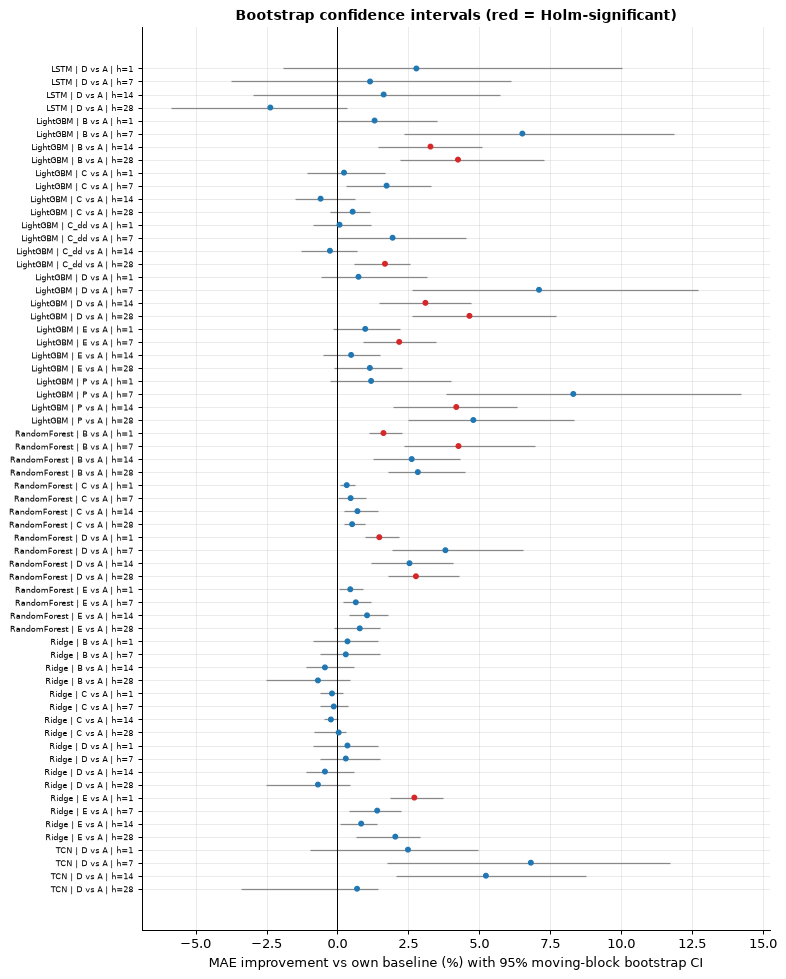

[OK] rossmann | statistical tests | 45.5s


**Primary family: LightGBM D vs A (paired moving-block bootstrap, Holm across 4 horizons)**

,model,comparison,h,block,B,days,rows,MAE_A,MAE_X,dMAE,dMAE_lo,dMAE_hi,imp_pct,imp_lo,imp_hi,p_boot,ci_includes_zero,p_holm
0,LightGBM,D vs A,1,7,2000,181,167266,577.7985,573.5173,4.2812,-3.3374,17.8706,0.7409,-0.5767,3.1505,0.5802,True,0.5802
1,LightGBM,D vs A,7,7,2000,181,167266,660.6226,613.7022,46.9205,15.8313,96.4664,7.1025,2.6145,12.6894,0.0055,False,0.0110
2,LightGBM,D vs A,14,14,2000,181,167266,652.5208,632.2941,20.2267,8.8996,34.2615,3.0998,1.4595,4.6918,0.0005,False,0.0020
3,LightGBM,D vs A,28,28,2000,181,167266,667.7630,636.7051,31.0579,17.1244,51.6871,4.6510,2.6390,7.7121,0.0005,False,0.0020


**Diebold–Mariano (HLN-corrected, Bartlett HAC)**

,model,comparison,h,DM,DM_HLN,p_DM,days,hac_lags,p_holm
0,LightGBM,D vs A,1,1.1621,1.1589,0.2480,181,7,0.2480
1,LightGBM,D vs A,7,2.6188,2.5248,0.0124,181,7,0.0249
2,LightGBM,D vs A,14,4.0769,3.7728,0.0002,181,13,0.0009
3,LightGBM,D vs A,28,3.9911,3.3847,0.0009,181,27,0.0026


**Block-length sensitivity (LightGBM D vs A)**

... (5 outputs left out)

**Per-store paired comparison (D vs A)**

,model,h,stores,win_rate_pct,median_store_imp_pct,wilcoxon_p
0,Ridge,1,1115,67.0852,0.4669,0.0000
1,Ridge,7,1115,60.4484,0.3605,0.0000
2,Ridge,14,1115,37.5785,-0.3736,0.0000
3,Ridge,28,1115,31.9283,-0.6945,0.0000
4,RandomForest,1,1115,62.7803,1.1462,0.0000
5,RandomForest,7,1115,86.6368,3.3855,0.0000
6,RandomForest,14,1115,87.0852,2.5091,0.0000
7,RandomForest,28,1115,82.2422,2.6033,0.0000
8,LightGBM,1,1115,53.3632,0.4199,0.0001
9,LightGBM,7,1115,94.7982,6.9753,0.0000


**Secondary family (all comparisons vs own baseline, Holm across all)**

,model,comparison,h,MAE_A,MAE_X,imp_pct,imp_lo,imp_hi,p_boot,p_holm_all
80,LSTM,D vs A,1,579.1644,563.0630,2.7801,-1.9128,10.0155,0.4338,1.0000
81,LSTM,D vs A,7,633.9102,626.6248,1.1493,-3.7403,6.1030,0.6282,1.0000
82,LSTM,D vs A,14,657.1245,646.4285,1.6277,-2.9657,5.7301,0.4603,1.0000
83,LSTM,D vs A,28,638.6776,653.7880,-2.3659,-5.8783,0.3212,0.1589,1.0000
15,LightGBM,A+c1_level vs A,1,577.7985,576.0326,0.3056,-1.0206,1.4608,0.6492,1.0000
...,...,...,...,...,...,...,...,...,...,...
70,Ridge,E vs A,28,769.6420,753.9550,2.0382,0.6659,2.9213,0.0015,0.1049
84,TCN,D vs A,1,578.6840,564.3055,2.4847,-0.9692,4.9420,0.1239,1.0000
85,TCN,D vs A,7,654.9094,610.2788,6.8148,1.7367,11.7356,0.0075,0.4048
86,TCN,D vs A,14,655.9370,621.6241,5.2311,2.0596,8.7431,0.0030,0.1859


In [ ]:
def daily_sums(ctx, model, cfg, h, rows_mask=None, split='test'):
    F = ctx['frames'][h]; Fs = F[split_mask(F, split)]
    p = ctx['preds'][(model, cfg, h)][split]
    codes, uniq = pd.factorize(Fs.date, sort=True)
    ok = ~np.isnan(p) if rows_mask is None else (~np.isnan(p) & rows_mask)
    ae = np.where(ok, np.abs(p - Fs.y.values), 0.0)
    n = len(uniq)
    return np.bincount(codes, ae, n), np.bincount(codes, ok.astype(float), n), ok

def block_idx(n, b, B, seed):
    rng = np.random.RandomState(seed)
    nb = int(np.ceil(n / b))
    starts = rng.randint(0, n - b + 1, size=(B, nb))
    return (starts[:, :, None] + np.arange(b)).reshape(B, -1)[:, :n]

def paired_bootstrap(ctx, model, cfgX, h, cfgA='A', b=None, B=None, store_set=None, seed=None):
    B = B or CONFIG['bootstrap']['B']; b = b or max(7, h)
    F = ctx['frames'][h]; Fs = F[split_mask(F, 'test')]
    rm = None if store_set is None else Fs.store.isin(store_set).values
    pa, pxx = ctx['preds'][(model, cfgA, h)]['test'], ctx['preds'][(model, cfgX, h)]['test']
    both = ~np.isnan(pa) & ~np.isnan(pxx)
    rm = both if rm is None else (rm & both)
    sa, n, _ = daily_sums(ctx, model, cfgA, h, rm); sx, _, _ = daily_sums(ctx, model, cfgX, h, rm)
    keep = n > 0; sa, sx, n = sa[keep], sx[keep], n[keep]
    idx = block_idx(len(sa), b, B, seed if seed is not None else CONFIG['seed'] + h)
    A, X, N = sa[idx].sum(1), sx[idx].sum(1), n[idx].sum(1)
    imp_b = 100 * (A - X) / A; dmae_b = (A - X) / N
    imp = 100 * (sa.sum() - sx.sum()) / sa.sum(); dmae = (sa.sum() - sx.sum()) / n.sum()
    p = (1 + np.sum(np.abs(imp_b - imp) >= abs(imp))) / (B + 1)
    lo, hi = np.percentile(imp_b, [2.5, 97.5]); dlo, dhi = np.percentile(dmae_b, [2.5, 97.5])
    return dict(model=model, comparison=f'{cfgX} vs {cfgA}', h=h, block=b, B=B, days=len(sa), rows=int(n.sum()),
                MAE_A=sa.sum() / n.sum(), MAE_X=sx.sum() / n.sum(), dMAE=dmae, dMAE_lo=dlo, dMAE_hi=dhi,
                imp_pct=imp, imp_lo=lo, imp_hi=hi, p_boot=p, ci_includes_zero=bool(lo <= 0 <= hi))

def dm_test(ctx, model, cfgX, h, cfgA='A'):
    F = ctx['frames'][h]; Fs = F[split_mask(F, 'test')]
    pa, pxx = ctx['preds'][(model, cfgA, h)]['test'], ctx['preds'][(model, cfgX, h)]['test']
    ok = ~np.isnan(pa) & ~np.isnan(pxx)
    d = pd.Series(np.abs(pa[ok] - Fs.y.values[ok]) - np.abs(pxx[ok] - Fs.y.values[ok])).groupby(Fs.date.values[ok]).mean().values
    n = len(d); L = max(h - 1, 7); dc = d - d.mean()
    v = np.sum(dc ** 2) / n
    for k in range(1, L + 1):
        v += 2 * (1 - k / (L + 1)) * np.sum(dc[k:] * dc[:-k]) / n
    dm = d.mean() / np.sqrt(v / n)
    hln = dm * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return dict(model=model, comparison=f'{cfgX} vs {cfgA}', h=h, DM=dm, DM_HLN=hln, p_DM=2 * stats.t.sf(abs(hln), n - 1), days=n, hac_lags=L)

def statistical_tests(ctx):
    H = CONFIG['horizons']
    prim = pd.DataFrame([paired_bootstrap(ctx, 'LightGBM', 'D', h) for h in H])
    prim['p_holm'] = holm(prim.p_boot.values)
    dm = pd.DataFrame([dm_test(ctx, 'LightGBM', 'D', h) for h in H]); dm['p_holm'] = holm(dm.p_DM.values)
    sec = []
    for (model, cfg, h) in ctx['preds']:
        if cfg == 'A' or model in ('SeasonalNaive', 'LightGBM_shuffled') or (model, 'A', h) not in ctx['preds']:
            continue
        sec.append(paired_bootstrap(ctx, model, cfg, h))
    sec = pd.DataFrame(sec)
    sec['p_holm_all'] = holm(sec.p_boot.values)
    sens = pd.DataFrame([paired_bootstrap(ctx, 'LightGBM', 'D', h, b=b) for h in H for b in CONFIG['bootstrap']['sensitivity_blocks']])
    # H2: components (B) vs composite (C) relative to baseline MAE
    h2 = []
    for h in H:
        F = ctx['frames'][h]; Fs = F[split_mask(F, 'test')]
        sa, n, _ = daily_sums(ctx, 'LightGBM', 'A', h); sb, _, _ = daily_sums(ctx, 'LightGBM', 'B', h); sc, _, _ = daily_sums(ctx, 'LightGBM', 'C', h)
        idx = block_idx(len(sa), max(7, h), CONFIG['bootstrap']['B'], CONFIG['seed'] + 100 + h)
        delta_b = 100 * (sb[idx].sum(1) - sc[idx].sum(1)) / sa[idx].sum(1)
        delta = 100 * (sb.sum() - sc.sum()) / sa.sum()
        lo, hi = np.percentile(delta_b, [2.5, 97.5])
        h2.append(dict(h=h, delta_B_minus_C_pct_of_A=delta, lo=lo, hi=hi, noninferior_margin_0p5=bool(hi < 0.5), components_worse=bool(lo > 0)))
    h2 = pd.DataFrame(h2)
    # H3: joint bootstrap of improvement difference across horizons (same target dates)
    sums = {h: (daily_sums(ctx, 'LightGBM', 'A', h)[0], daily_sums(ctx, 'LightGBM', 'D', h)[0]) for h in H}
    nd = len(sums[H[0]][0]); assert all(len(v[0]) == nd for v in sums.values())
    idx = block_idx(nd, 28 if 28 in H else max(H), CONFIG['bootstrap']['B'], CONFIG['seed'] + 999)
    impb = {h: 100 * (sums[h][0][idx].sum(1) - sums[h][1][idx].sum(1)) / sums[h][0][idx].sum(1) for h in H}
    imp = {h: 100 * (sums[h][0].sum() - sums[h][1].sum()) / sums[h][0].sum() for h in H}
    h3 = []
    for a, bb in [(H[0], H[-1]), (H[1], H[-1]), (H[0], H[1])]:
        dlt = impb[a] - impb[bb]
        h3.append(dict(contrast=f'Imp(h={a}) - Imp(h={bb})', estimate=imp[a] - imp[bb], lo=np.percentile(dlt, 2.5), hi=np.percentile(dlt, 97.5)))
    h3 = pd.DataFrame(h3)
    rho = stats.spearmanr(H, [imp[h] for h in H])[0]
    # per-store Wilcoxon / win rate
    ws = []
    for model in ['Ridge', 'RandomForest', 'LightGBM', 'LSTM', 'TCN']:
        for h in H:
            if (model, 'D', h) not in ctx['preds']:
                continue
            a, d = per_store_errors(ctx, model, 'A', h), per_store_errors(ctx, model, 'D', h)
            diff = (a - d).dropna()
            ws.append(dict(model=model, h=h, stores=len(diff), win_rate_pct=100 * (diff > 0).mean(),
                           median_store_imp_pct=float((100 * (a - d) / a).median()), wilcoxon_p=stats.wilcoxon(diff).pvalue))
    ws = pd.DataFrame(ws)
    ctx['stats'] = dict(primary=prim, dm=dm, secondary=sec, sensitivity=sens, h2=h2, h3=h3, h3_spearman=rho, wilcoxon=ws)
    # forest plot
    q = sec[sec.comparison.isin(['B vs A', 'C vs A', 'D vs A', 'E vs A', 'P vs A', 'C_dd vs A'])].copy()
    q = q[q.model.isin(['LightGBM', 'Ridge', 'RandomForest', 'LSTM', 'TCN'])].sort_values(['model', 'comparison', 'h'])
    fig, ax = plt.subplots(figsize=(9, 0.18 * len(q) + 1.5))
    y = np.arange(len(q))[::-1]
    sig = q.p_holm_all < 0.05
    ax.errorbar(q.imp_pct, y, xerr=[q.imp_pct - q.imp_lo, q.imp_hi - q.imp_pct], fmt='none', ecolor='#888', elinewidth=1)
    ax.scatter(q.imp_pct, y, c=np.where(sig, '#d62728', '#1f77b4'), s=14, zorder=3)
    ax.axvline(0, color='k', lw=0.8)
    ax.set_yticks(y); ax.set_yticklabels([f'{m} | {c} | h={h}' for m, c, h in zip(q.model, q.comparison, q.h)], fontsize=6.5)
    ax.set_xlabel('MAE improvement vs own baseline (%) with 95% moving-block bootstrap CI'); ax.set_title('Bootstrap confidence intervals (red = Holm-significant)')
    save_fig(ctx, fig, 'fig42_bootstrap_ci', 'Bootstrap confidence-interval plot.')
    return ctx['stats']

R_stats = run_step(R, 'statistical tests', statistical_tests, R)
if R_stats:
    md('**Primary family: LightGBM D vs A (paired moving-block bootstrap, Holm across 4 horizons)**'); display(R_stats['primary'].round(4))
    md('**Diebold–Mariano (HLN-corrected, Bartlett HAC)**'); display(R_stats['dm'].round(4))
    md('**Block-length sensitivity (LightGBM D vs A)**'); display(R_stats['sensitivity'][['h', 'block', 'imp_pct', 'imp_lo', 'imp_hi', 'p_boot']].round(4))
    md('**H2: components (B) minus composite (C), % of baseline MAE (negative = components better)**'); display(R_stats['h2'].round(4))
    md(f"**H3: horizon contrasts (LightGBM D vs A)**, Spearman(h, improvement) = {R_stats['h3_spearman']:.2f}"); display(R_stats['h3'].round(4))
    md('**Per-store paired comparison (D vs A)**'); display(R_stats['wilcoxon'].round(4))
    md('**Secondary family (all comparisons vs own baseline, Holm across all)**')
    display(R_stats['secondary'][['model', 'comparison', 'h', 'MAE_A', 'MAE_X', 'imp_pct', 'imp_lo', 'imp_hi', 'p_boot', 'p_holm_all']].sort_values(['model', 'comparison', 'h']).round(4))

**Interpretation: statistical tests (Fig. 42).**

* **Primary family (LightGBM D vs A, block bootstrap, Holm):**
  * h = 1: not significant (+0.74 %, CI −0.58 to +3.15, p = 0.58).
  * h = 7: +7.10 % [2.61, 12.69], p = 0.011.
  * h = 14: +3.10 % [1.46, 4.69], p = 0.002.
  * h = 28: +4.65 % [2.64, 7.71], p = 0.002.
* **Robustness of these results:**
  * Diebold–Mariano with HLN correction agrees: Holm p = 0.25, 0.025, 0.0009 and 0.0026.
  * Block lengths of 7, 14 and 28 days leave every conclusion unchanged.
  * Per store, 95 % of stores improve at h = 7, and 77–84 % at h = 14 and 28.
* **H2:** components minus composite = −1.1 to −4.8 % of baseline MAE. The upper bound stays below the +0.5 % margin at every horizon, so the components are at least as good as the composite, and better at h ≥ 7.
* **H3:** the pre-specified expectation is **reversed**. Imp(h = 1) − Imp(h = 28) = −3.91 pp, CI [−6.08, −0.77]. At h = 1 the freshest sales lag already encodes the store's current state, so behavioural summaries add most when the lags are older.
* **Secondary family** (Holm across all 88 comparisons, which is much stricter): the significant gains are LightGBM B and D at h = 14 and 28, P at h = 14, C_dd and A+C1 at h = 28, and E at h = 7; Random Forest B at h = 1 and 7 and D at h = 1 and 28; and Ridge E at h = 1. The LightGBM D gain at h = 7 is significant in the primary family but not after this all-comparison correction. No LSTM or TCN contrast survives it.

## 16. Leakage audit

Each item in the protocol has an **automated** check. If a check fails, the table shows FAIL and the failure is logged, never hidden.

| # | Risk | Executable check |
|---|---|---|
| 1 | Future sales entering history features | **Perturbation invariance:** every sales and activity value after a cut-off τ is randomly corrupted, the *entire* pipeline (state → CVI fit → frames) is rebuilt, and every feature of every row whose origin ≤ τ must be bit-identical. A **power check** confirms that rows with origin > τ do change |
| 2 | Future activity entering CVI | Same test; it covers all components, all composites and all sub-features |
| 3 | Same-day activity used as a feature | Provenance: the only feature anchored on the target day's *observed* activity is `a_same_day`, and it appears only in ORACLE |
| 4 | Target leakage through rolling windows | For every frame, `state_date ≤ origin = date − h < date` holds for every row |
| 5 | Preprocessing fitted on test data | CVI standardiser fit window ends at the training end; τ is placed after it, so a full-sample fit would break invariance |
| 6 | Scaling / weighting fitted on test data | Same as 5, for the PCA and data-driven weights; model imputers and scalers are fitted on training rows |
| 7 | Store-date duplicates | Each frame has unique `(store, date)` keys |
| 8 | Incorrect split boundaries | train < validation < test in time, with no overlap |
| + | **Shuffled-target sanity test** | LightGBM D at h = 7 trained on a permuted target must show no out-of-sample skill (R² ≤ ~0) |
| + | **Oracle diagnostic** | Measures how much same-day activity *would* inflate accuracy if leaked. It is never used as a forecast |

In [ ]:
def provenance(ctx):
    rows = []
    def add(f, grp, src, window, anchor):
        rows.append(dict(feature=f, group=grp, source=src, window=window, anchor=anchor))
    for f in CAL_COMMON + ctx['extra_cal'] + ['promo_int_t']:
        add(f, 'calendar / planned', 'target-day calendar, planned promotion, store schedule, master data', 'target day', 'target_known_in_advance')
    for f in [c + '_code' for c in ctx['static_cat']] + ctx['static_num']:
        add(f, 'static', 'store master data', '-', 'static')
    desc = {'s_lag': 'log1p sales on k-th most recent trading day', 's_ma': 'log1p mean sales, last w trading days',
            'a_lag': 'log1p activity on k-th most recent trading day', 'a_ma': 'log1p mean activity, last w trading days'}
    for f in SALES_HIST + ACT_RAW + PLACEBO + COMP_RAW + COMP + ['cvi_eq', 'cvi_dd', 'cvi_pca'] + SUB_FEATURES:
        grp = ('sales history' if f in SALES_HIST else 'raw activity' if f in ACT_RAW else 'sales analogue' if f in PLACEBO
               else 'CVI component' if f in COMP + COMP_RAW else 'CVI composite' if f.startswith('cvi') else 'CVI sub-feature')
        add(f, grp, desc.get(f[:5], 'see Section 7-8'), 'trading days <= origin', 'origin')
    add('a_same_day', 'ORACLE', 'activity observed on the target day', 'target day', 'target_day_observed (LEAKAGE - diagnostic only)')
    return pd.DataFrame(rows).drop_duplicates('feature')

def build_targets_for(ctx, daily):
    saved = ctx['daily']; ctx['daily'] = daily
    try:
        return build_targets(ctx)
    finally:
        ctx['daily'] = saved

def perturbation_test(ctx):
    rng = np.random.RandomState(CONFIG['seed'])
    d = ctx['daily']
    stores = rng.choice(d.store.unique(), min(CONFIG['perturb_n_stores'], d.store.nunique()), replace=False)
    d0 = d[d.store.isin(stores)].copy().reset_index(drop=True)
    tau = ctx['splits']['val_start'] + pd.Timedelta(days=60)
    d1 = d0.copy(); m = (d1.date > tau).values
    d1.loc[m, 'sales'] = d1.loc[m, 'sales'].values * np.exp(rng.normal(0, 0.5, m.sum()))
    d1.loc[m, 'activity'] = d1.loc[m, 'activity'].values * np.exp(rng.normal(0, 0.5, m.sum()))
    S0, _ = build_state(ctx, d0); fit_cvi(S0, ctx['splits']['train_end'], CONFIG['min_history'])
    S1, _ = build_state(ctx, d1); fit_cvi(S1, ctx['splits']['train_end'], CONFIG['min_history'])
    T0, T1 = build_targets_for(ctx, d0), build_targets_for(ctx, d1)
    feats = sorted(set(sum([v for k, v in ctx['feature_sets'].items() if k != 'ORACLE'], [])) | {'cvi_pca', 'cvi_dd'} | set(SUB_FEATURES))
    hist = [f for f in feats if f in SALES_HIST + ACT_RAW + PLACEBO + COMP + ['cvi_eq', 'cvi_dd', 'cvi_pca'] + SUB_FEATURES]
    rows = []
    for h in CONFIG['horizons']:
        F0 = build_frame(T0, S0, h).sort_values(['store', 'date']).reset_index(drop=True)
        F1 = build_frame(T1, S1, h).sort_values(['store', 'date']).reset_index(drop=True)
        assert (F0[['store', 'date']].values == F1[['store', 'date']].values).all()
        A0, A1 = F0[feats].to_numpy(float), F1[feats].to_numpy(float)
        eq = (A0 == A1) | (np.isnan(A0) & np.isnan(A1))
        pre = (F0.origin <= tau).values
        hcols = [feats.index(f) for f in hist]
        post_rows = (~pre) & (F0.state_date > tau).values
        rows.append(dict(h=h, tau=str(tau.date()), stores=len(stores), values_checked=int(eq[pre].size), mismatches_pre_cutoff=int((~eq[pre]).sum()),
                         post_rows=int(post_rows.sum()), share_post_rows_changed=float((~eq[post_rows][:, hcols]).any(1).mean()) if post_rows.any() else np.nan))
    return pd.DataFrame(rows)

def leakage_audit(ctx):
    checks = []
    def chk(name, ok, evidence):
        checks.append(dict(check=name, result='PASS' if ok else 'FAIL', evidence=evidence))
    prov = provenance(ctx); ctx['provenance'] = prov
    pmap = prov.set_index('feature').anchor.to_dict()
    bad = {k: [f for f in v if 'target_day_observed' in pmap.get(f, 'UNKNOWN') or f not in pmap] for k, v in ctx['feature_sets'].items() if k != 'ORACLE'}
    chk('Feature provenance: every non-oracle feature anchored at origin / known-in-advance / static', all(len(v) == 0 for v in bad.values()),
        f'{len(prov)} features documented; offending: {[x for v in bad.values() for x in v]}')
    chk('Same-day activity only in ORACLE', all('a_same_day' not in v for k, v in ctx['feature_sets'].items() if k != 'ORACLE'),
        'a_same_day absent from configs A-E, C_dd, P, A+Ck')
    ok_w, ok_d, ev = True, True, []
    for h, F in ctx['frames'].items():
        ok_w &= bool((F.state_date <= F.origin).all() and (F.origin == F.date - pd.Timedelta(days=h)).all() and (F.state_date < F.date).all())
        ok_d &= not F.duplicated(['store', 'date']).any()
        ev.append(f'h={h}: max(origin-state_date)>=0, rows={len(F):,}')
    chk('Rolling windows end at origin (state_date <= t-h < t)', ok_w, '; '.join(ev))
    chk('No store-date duplicates in any frame', ok_d, 'unique (store,date) in all horizon frames')
    F = ctx['frames'][CONFIG['horizons'][0]]
    mx = F.groupby('split').date.agg(['min', 'max'])
    ok_s = mx.loc['train', 'max'] < mx.loc['val', 'min'] and mx.loc['val', 'max'] < mx.loc['test', 'min']
    chk('Temporal split boundaries ordered, no overlap', ok_s, mx.astype(str).to_dict('index'))
    cm = ctx['cvi_meta']
    chk('CVI standardiser / weights fitted on training period only', pd.Timestamp(cm['fit_max_state_date']) <= ctx['splits']['train_end'],
        f"fit_max_state_date={cm['fit_max_state_date']} <= train_end={ctx['splits']['train_end'].date()}; data-driven fit rows={cm['dd_fit_rows']:,}")
    pt = perturbation_test(ctx); ctx['perturbation'] = pt
    chk('Perturbation invariance (future sales/activity cannot change past-origin features)', int(pt.mismatches_pre_cutoff.sum()) == 0,
        f"{int(pt.values_checked.sum()):,} feature values re-computed; {int(pt.mismatches_pre_cutoff.sum())} mismatches")
    chk('Power check (features after the cut-off DO change)', bool((pt.share_post_rows_changed > 0.9).all()),
        f"share of post-cut-off rows changed: {pt.share_post_rows_changed.round(3).tolist()}")
    h0 = 7 if 7 in CONFIG['horizons'] else CONFIG['horizons'][0]
    fit_lgb(ctx, h0, 'D', shuffle=True)
    Ft = ctx['frames'][h0]; yt = Ft.loc[split_mask(Ft, 'test'), 'y'].values
    sh = metrics(yt, ctx['preds'][('LightGBM_shuffled', 'D', h0)]['test']); real = metrics(yt, ctx['preds'][('LightGBM', 'D', h0)]['test'])
    chk('Shuffled-target sanity test', sh['R2'] < 0.05, f"test R2 shuffled = {sh['R2']:.3f} vs real = {real['R2']:.3f}; MAE {sh['MAE']:,.0f} vs {real['MAE']:,.0f}")
    r = ctx['results']; o = r[(r.model == 'LightGBM') & (r.cfg == 'ORACLE') & (r.split == 'test') & (r.subset == 'all')].sort_values('h')
    ctx['oracle_gap'] = o[['h', 'MAE', 'Improvement_%']]
    chk('Oracle diagnostic computed (reported as upper bound only)', len(o) > 0,
        'ORACLE MAE improvement vs A: ' + ', '.join(f"h={a}: {b:+.1f}%" for a, b in zip(o.h, o['Improvement_%'])))
    audit = pd.DataFrame(checks); ctx['leak_audit'] = audit
    return audit

R_leak = run_step(R, 'leakage audit', leakage_audit, R)
display(R_leak)
display(R.get('perturbation'))
display(R['provenance'].head(60))

[OK] rossmann | leakage audit | 8.4s


,check,result,evidence
0,Feature provenance: every non-oracle feature a...,PASS,60 features documented; offending: []
1,Same-day activity only in ORACLE,PASS,"a_same_day absent from configs A-E, C_dd, P, A+Ck"
2,Rolling windows end at origin (state_date <= t...,PASS,"h=1: max(origin-state_date)>=0, rows=732,780; ..."
3,No store-date duplicates in any frame,PASS,"unique (store,date) in all horizon frames"
4,"Temporal split boundaries ordered, no overlap",PASS,"{'test': {'min': '2015-02-01', 'max': '2015-07..."
5,CVI standardiser / weights fitted on training ...,PASS,fit_max_state_date=2014-07-31 <= train_end=201...
6,Perturbation invariance (future sales/activity...,PASS,"5,361,427 feature values re-computed; 0 mismat..."
7,Power check (features after the cut-off DO cha...,PASS,"share of post-cut-off rows changed: [1.0, 1.0,..."
8,Shuffled-target sanity test,PASS,test R2 shuffled = -0.071 vs real = 0.910; MAE...
9,Oracle diagnostic computed (reported as upper ...,PASS,"ORACLE MAE improvement vs A: h=1: +28.2%, h=7:..."


,h,tau,stores,values_checked,mismatches_pre_cutoff,post_rows,share_post_rows_changed
0,1,2014-09-30,60,1317421,0,14062,1.0000
1,7,2014-09-30,60,1327650,0,13821,1.0000
2,14,2014-09-30,60,1342914,0,13461,1.0000
3,28,2014-09-30,60,1373442,0,12741,1.0000


,feature,group,source,window,anchor
0,dow_t,calendar / planned,"target-day calendar, planned promotion, store ...",target day,target_known_in_advance
1,month_t,calendar / planned,"target-day calendar, planned promotion, store ...",target day,target_known_in_advance
2,dom_t,calendar / planned,"target-day calendar, planned promotion, store ...",target day,target_known_in_advance
3,woy_t,calendar / planned,"target-day calendar, planned promotion, store ...",target day,target_known_in_advance
4,is_weekend_t,calendar / planned,"target-day calendar, planned promotion, store ...",target day,target_known_in_advance
5,days_to_month_end_t,calendar / planned,"target-day calendar, planned promotion, store ...",target day,target_known_in_advance
6,promo_t,calendar / planned,"target-day calendar, planned promotion, store ...",target day,target_known_in_advance
7,holiday_t,calendar / planned,"target-day calendar, planned promotion, store ...",target day,target_known_in_advance
8,school_t,calendar / planned,"target-day calendar, planned promotion, store ...",target day,target_known_in_advance
9,hol_prev_t,calendar / planned,"target-day calendar, planned promotion, store ...",target day,target_known_in_advance


**Interpretation: leakage audit.**

All ten automated checks **PASS**:

* Perturbation invariance: **5,361,427** feature values recomputed after corrupting the future, with 0 mismatches. Power check: 100 % of post-cut-off rows changed.
* Same-day customers appear only in the ORACLE configuration.
* Every window ends at the origin, and there are no store-date duplicates.
* The splits are ordered, and the CVI fit window ends at the training end.
* The shuffled-target model collapses to test R² = −0.071 (MAE 2,227 EUR), against 0.910 (614 EUR) for the real model.

The reported gains therefore cannot come from look-ahead features or test-fitted transforms.

## 17. Cross-dataset validation: Corporación Favorita

The **same functions** run unchanged on Favorita: validation, preprocessing rules, EDA, CVI recipe and windows, splits shape, hyperparameter-search protocol, models, ablations, statistics and leakage audit. Only three adaptations are forced by the data:

1. **Activity** is `transactions`, a count of store transactions and therefore a *proxy* for customer activity, not a count of customers. Basket value is correspondingly *sales units per transaction*.
2. Favorita has no store-level promotion flag. Planned on-promotion item counts become a binary "promo day" (count above the store's trailing 28-day median, past data only) and a continuous intensity.
3. The target is total **unit** sales across 33 product families, so errors are in units rather than euros.

[OK] favorita | load | 4.6s


,table,rows,columns,dtypes
0,train,3000888,6,"id:int64, date:str, store_nbr:int64, family:st..."
1,stores,54,5,"store_nbr:int64, city:str, state:str, type:str..."
2,transactions,83488,3,"date:str, store_nbr:int64, transactions:int64"
3,holidays_events,350,6,"date:str, type:str, locale:str, locale_name:st..."


[OK] favorita | validation | 2.3s


,check,value
0,train shape,"(3000888, 6)"
1,sales column used,sales
2,missing cells - train,"{'id': 0, 'date': 0, 'store_nbr': 0, 'family':..."
3,"duplicate (store, date, family) keys",0
4,date range,2013-01-01 .. 2017-08-15 (1684 dates)
5,calendar dates absent from train (all stores),"[2013-12-25, 2014-12-25, 2015-12-25, 2016-12-25]"
6,stores in train / stores.csv,54 / 54
7,store ids in train not in stores.csv,0
8,families,33
9,negative sales rows,0


[OK] favorita | preprocess | 2.4s


,dataset,item,decision,rationale,affected_rows
0,favorita,Negative family-level sales (returns),clipped to 0 before store aggregation,Store-level demand cannot be negative.,0
1,favorita,Calendar dates absent for all stores (e.g. 25 ...,"treated as closures (no target, no history)",Absent for every store means the chain was clo...,216
2,favorita,Store-days with total sales = 0,treated as non-trading days (pre-opening / tem...,A store selling nothing across all families is...,7330
3,favorita,Trading days without transactions record,"activity = NaN (missing), sales kept",Missing activity is not zero activity.,118
4,favorita,"Promotion flag (Favorita has item counts, no s...",promo=1 if planned on-promotion item count > s...,Converts counts to a store-relative promo day;...,32116
5,favorita,Sales outliers (|robust z of log sales| > 4 wi...,flagged but retained (no winsorising of the ta...,Extreme days are mostly genuine (pre-holiday p...,38


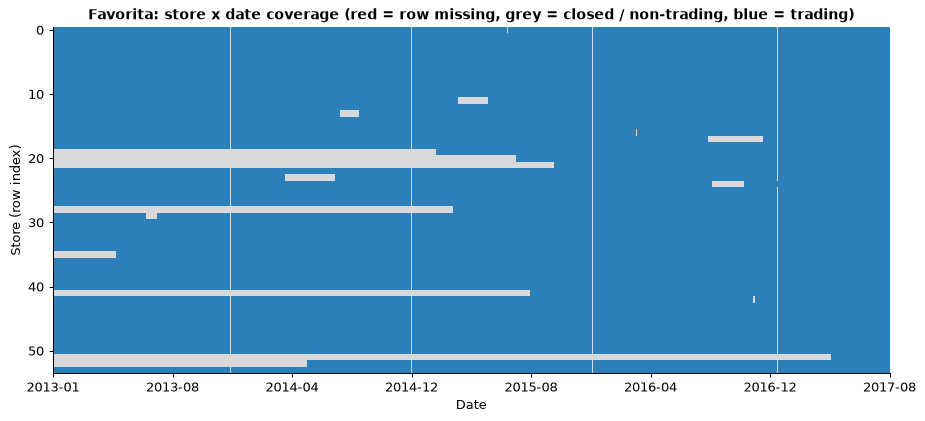

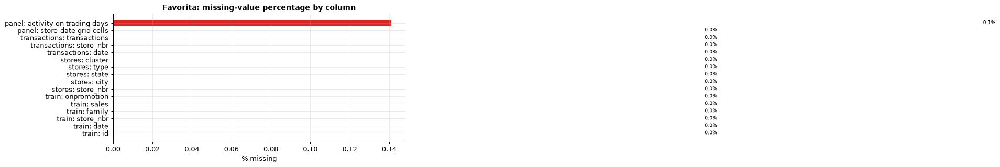

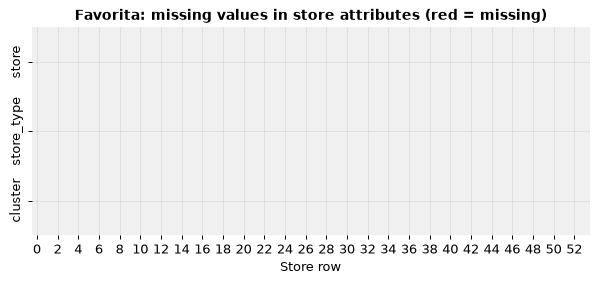

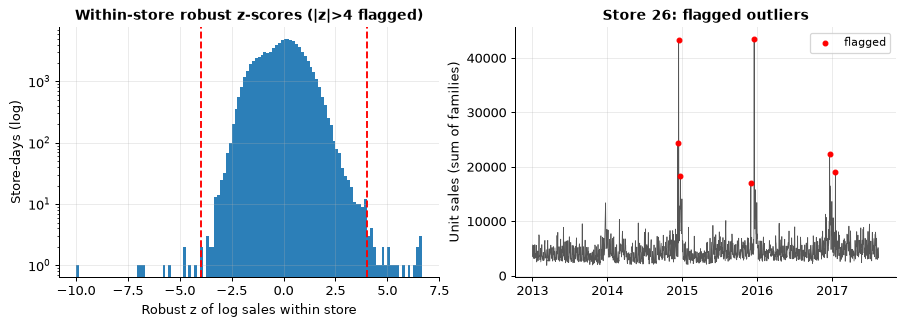

[OK] favorita | data-quality figures | 5.6s


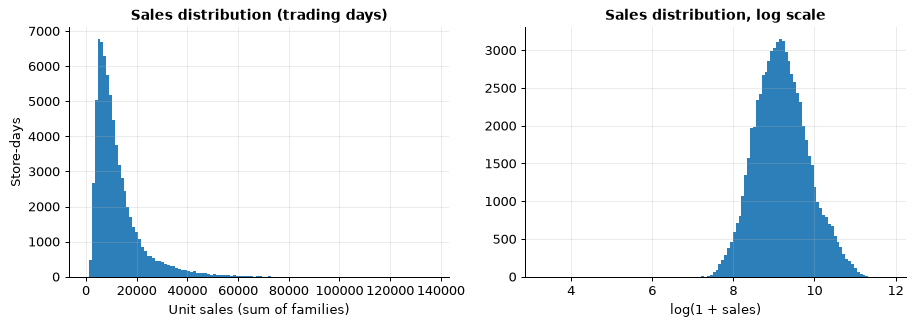

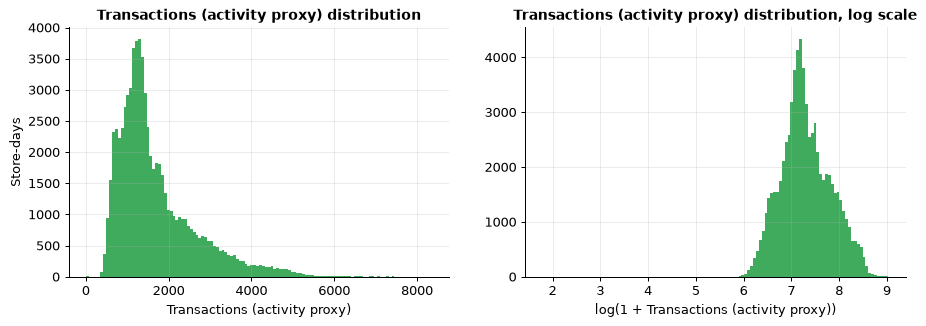

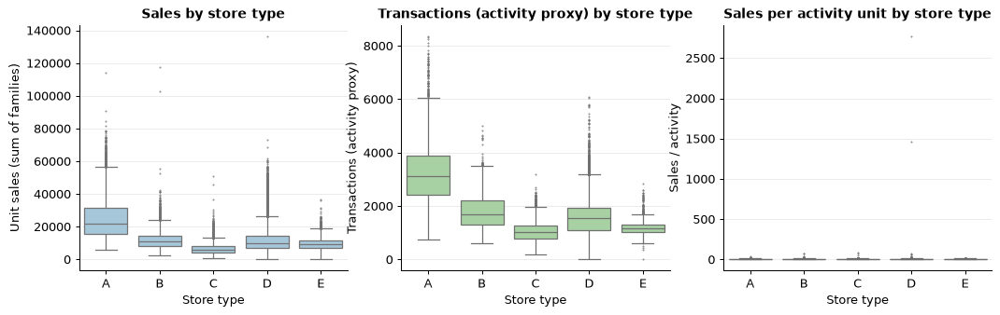

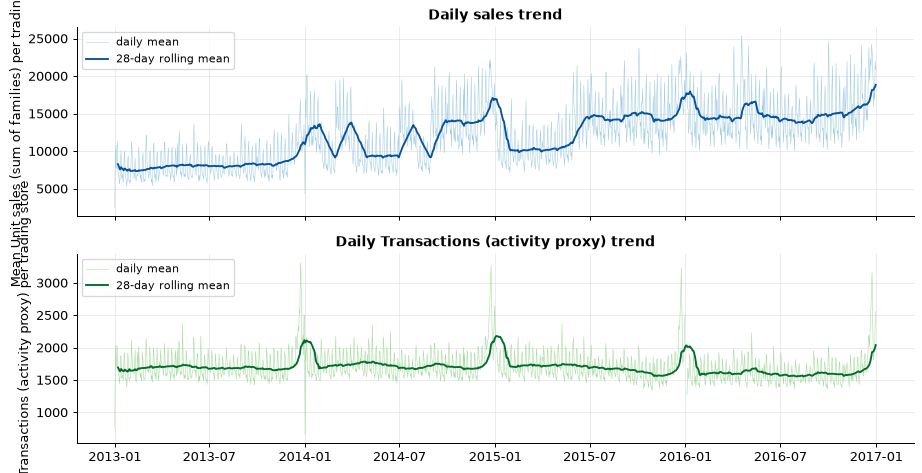

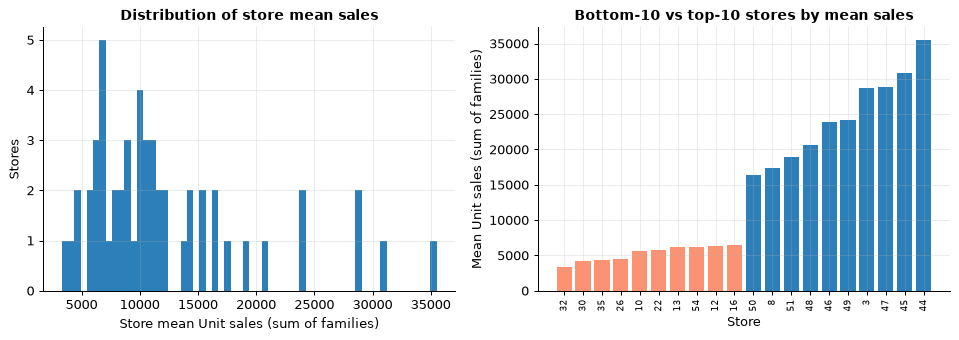

[OK] favorita | EDA overview | 8.4s


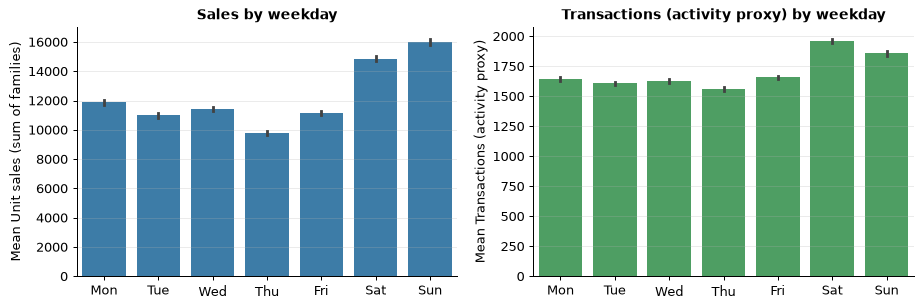

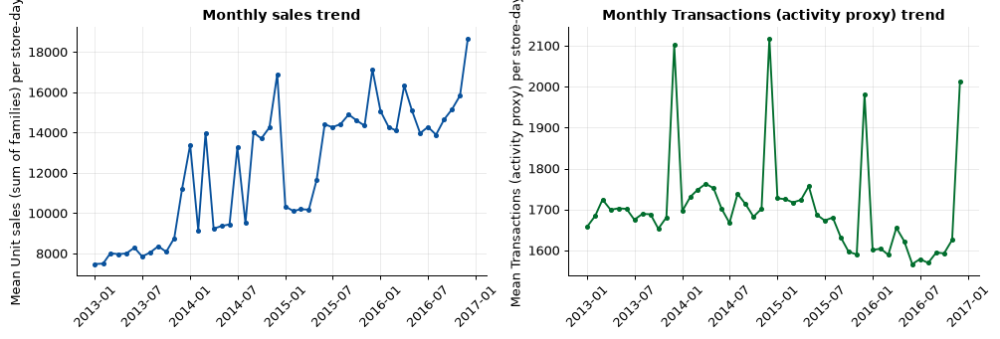

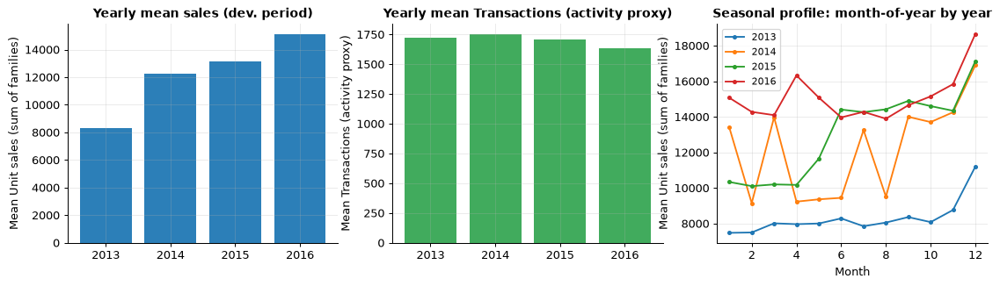

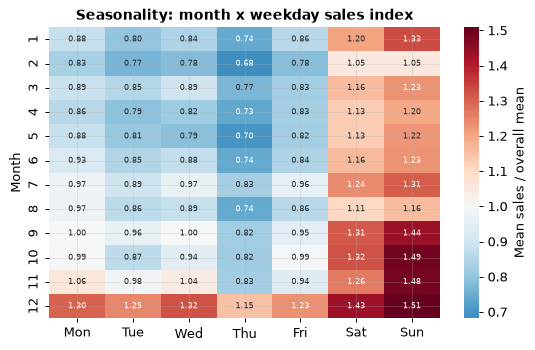

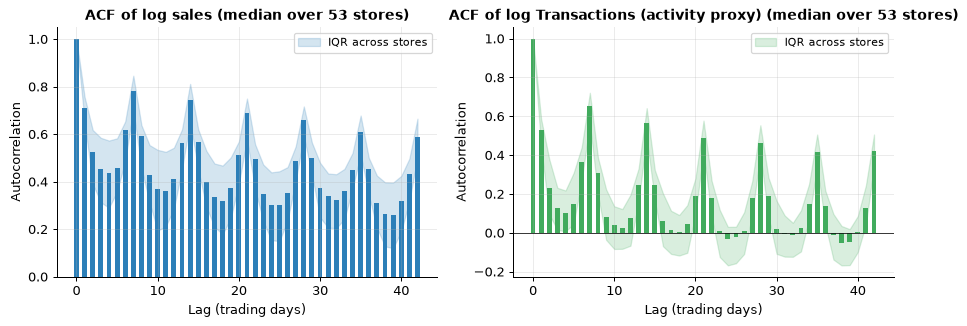

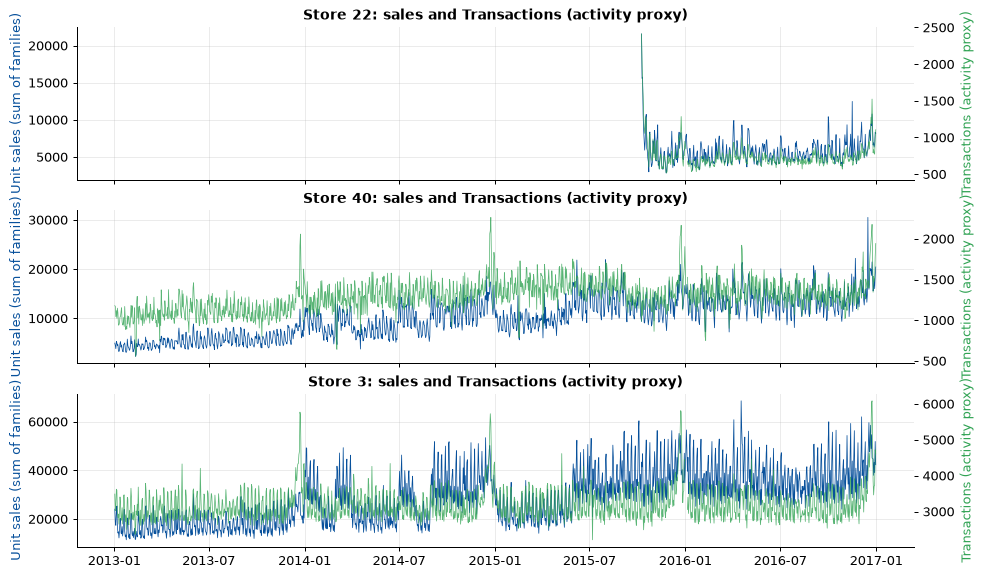

[OK] favorita | EDA temporal | 11.2s


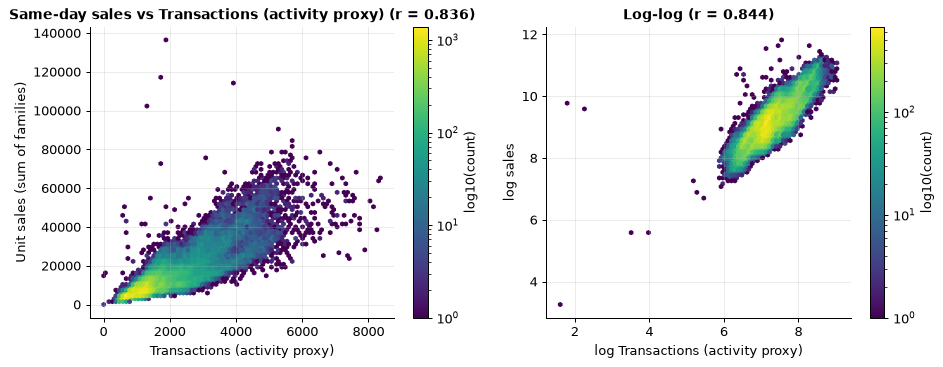

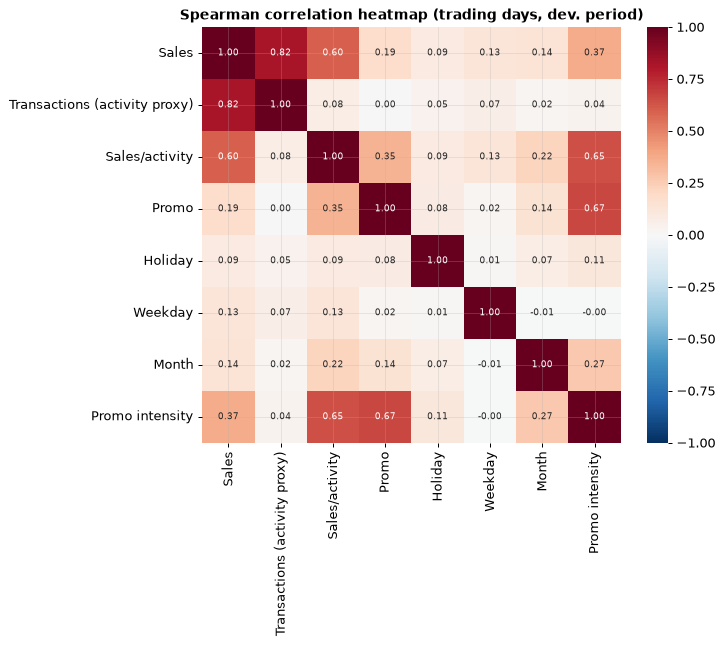

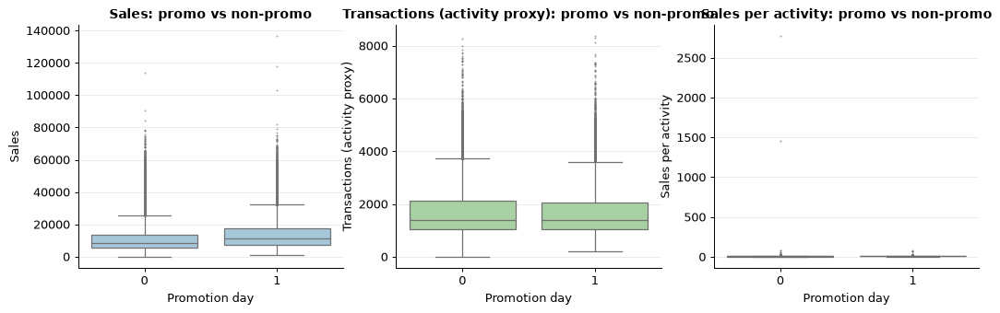

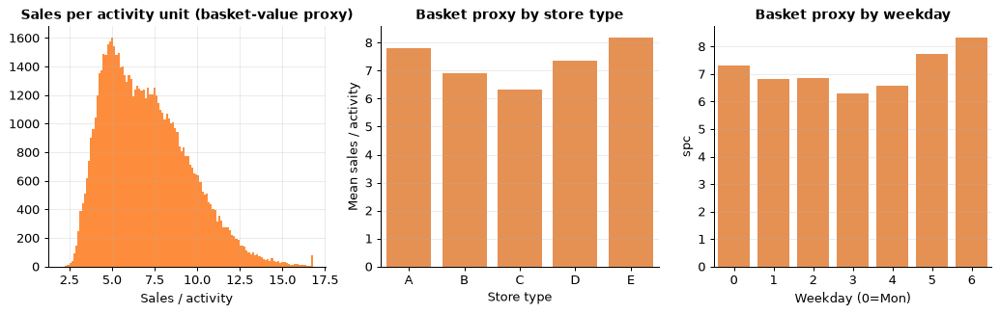

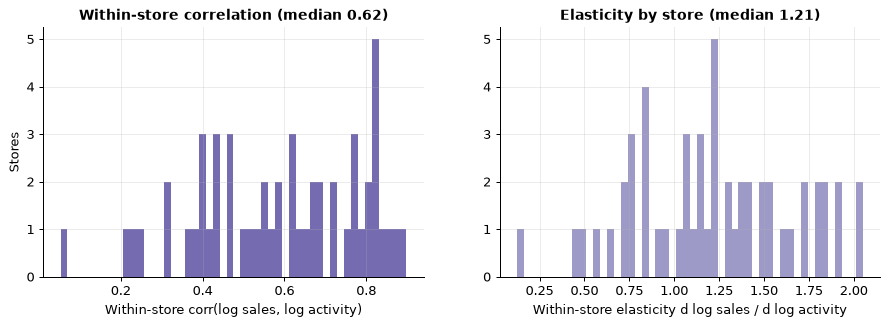

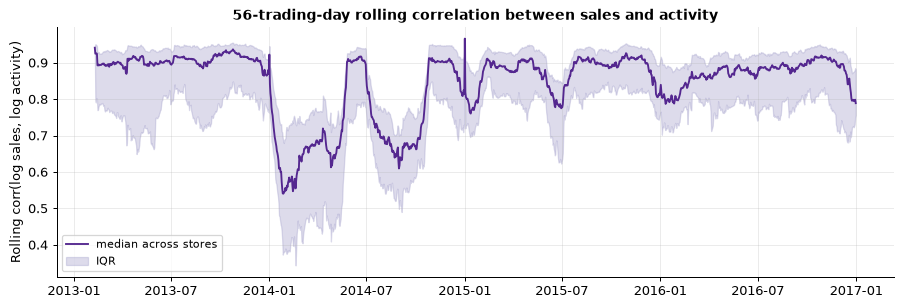

[OK] favorita | EDA relationships | 9.9s


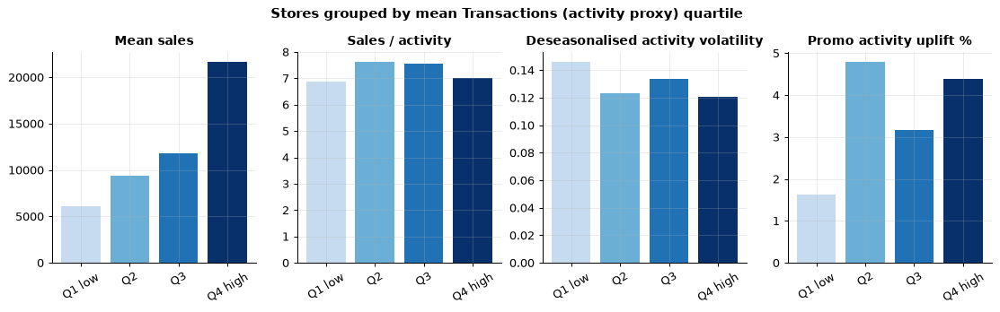

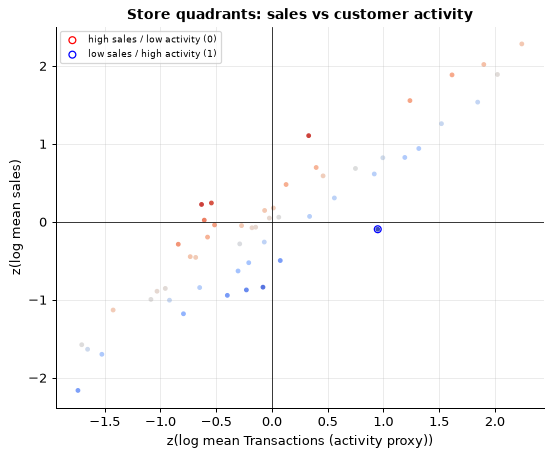

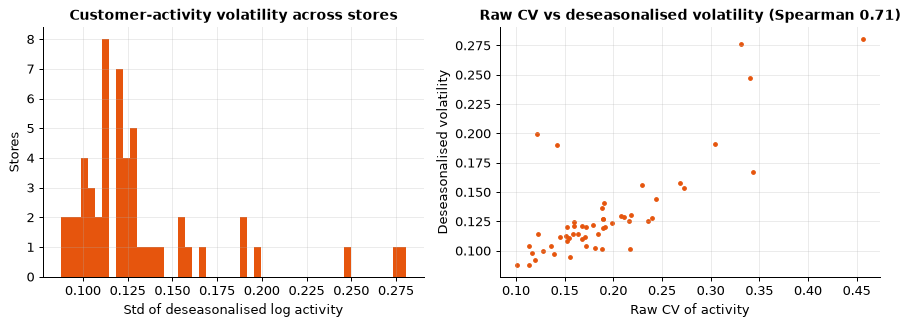

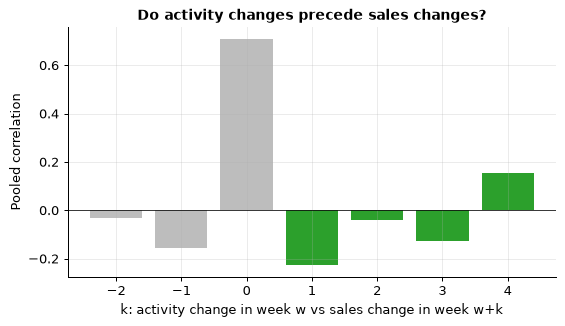

[OK] favorita | EDA advanced | 4.9s
{
 "rows_dev": 71509,
 "stores": 53,
 "sales_skew": 2.2491631293583443,
 "sales_mean": 12298.142664976402,
 "sales_median": 9555.34099,
 "act_skew": 1.5202901981504626,
 "act_mean": 1701.5983667409057,
 "store_mean_ratio_p90_p10": 3.9750252851867356,
 "weekday_sales": {
  "0": 11870.2,
  "1": 10992.3,
  "2": 11430.6,
  "3": 9789.4,
  "4": 11130.4,
  "5": 14855.7,
  "6": 16000.2
 },
 "weekday_act": {
  "0": 1643.3,
  "1": 1607.1,
  "2": 1628.6,
  "3": 1557.6,
  "4": 1656.5,
  "5": 1960.6,
  "6": 1856.6
 },
 "weekday_n": {
  "0": 10233,
  "1": 10232,
  "2": 10187,
  "3": 10190,
  "4": 10187,
  "5": 10293,
  "6": 10187
 },
 "yearly": {
  "sales": {
   "2013": 8302.9,
   "2014": 12221.4,
   "2015": 13129.8,
   "2016": 15104.1
  },
  "act": {
   "2013": 1721.5,
   "2014": 1750.9,
   "2015": 1706.8,
   "2016": 1634.4
  },
  "days": {
   "2013": 364,
   "2014": 364,
   "2015": 364,
   "2016": 365
  }
 },
 "acf_sales_lag1": 0.7092544034617716,
 "acf_sales_la

[OK] favorita | build state | 1.1s
[OK] favorita | fit CVI | 0.1s
{
 "fit_end": "2016-06-30",
 "fit_rows": 59075,
 "dd_fit_rows": 57588,
 "mean": {
  "c1_level": 7.320863239378927,
  "c2_spend": 1.8812905641721245,
  "c3_stability": -0.1122533761341845,
  "c4_momentum": -0.0022767459945300422,
  "c5_promo": 0.029392837092491693
 },
 "std": {
  "c1_level": 0.4918567467879413,
  "c2_spend": 0.30520235364566384,
  "c3_stability": 0.07173899143856294,
  "c4_momentum": 0.06676213724802665,
  "c5_promo": 0.054395892458636984
 },
 "missing_rate_before_impute": {
  "c1_level": 0.0084,
  "c2_spend": 0.0084,
  "c3_stability": 0.0213,
  "c4_momentum": 0.0174,
  "c5_promo": 0.2916
 },
 "w_equal": {
  "z_c1_level": 0.2,
  "z_c2_spend": 0.2,
  "z_c3_stability": 0.2,
  "z_c4_momentum": 0.2,
  "z_c5_promo": 0.2
 },
 "w_pca": {
  "z_c1_level": 0.0495,
  "z_c2_spend": -0.1893,
  "z_c3_stability": 0.3774,
  "z_c4_momentum": 0.2493,
  "z_c5_promo": -0.1345
 },
 "pca_explained": [
  0.2693,
  0.2391,
  0.1

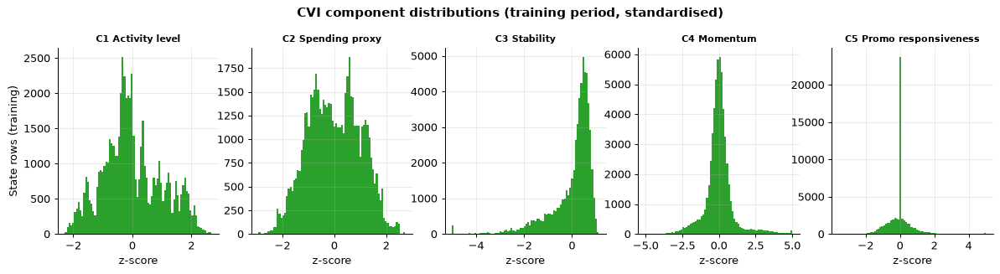

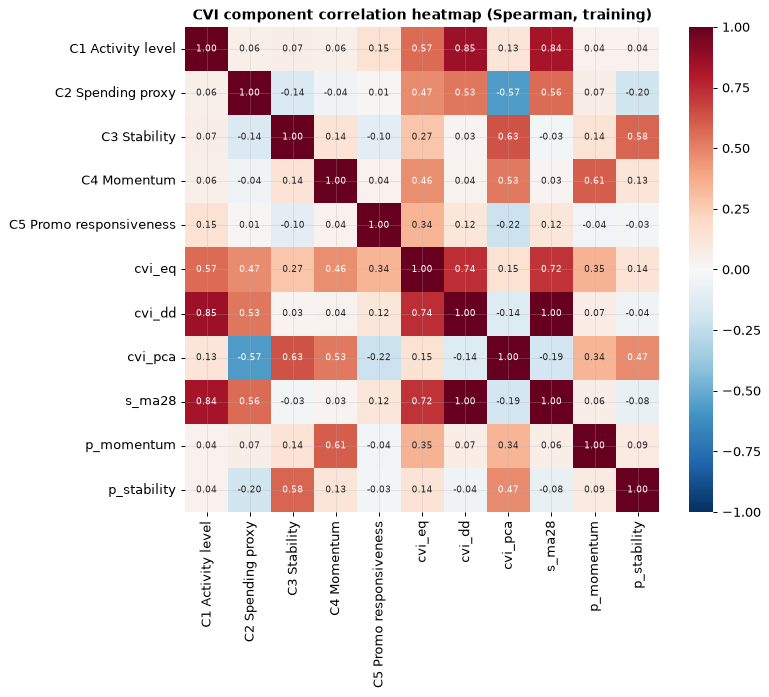

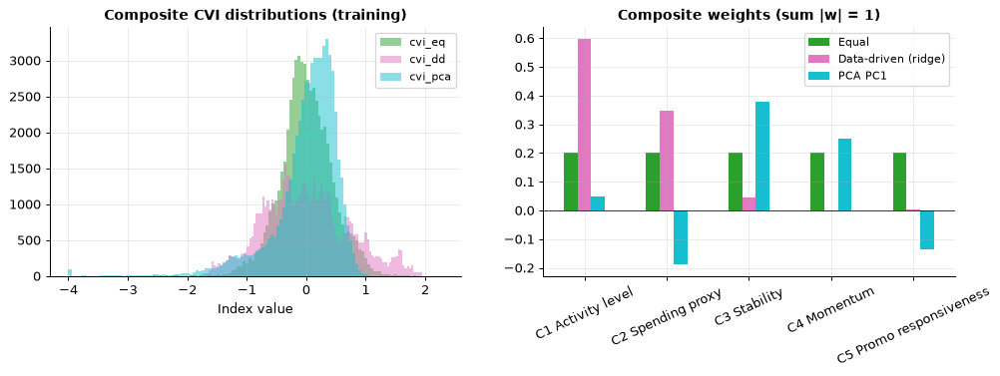

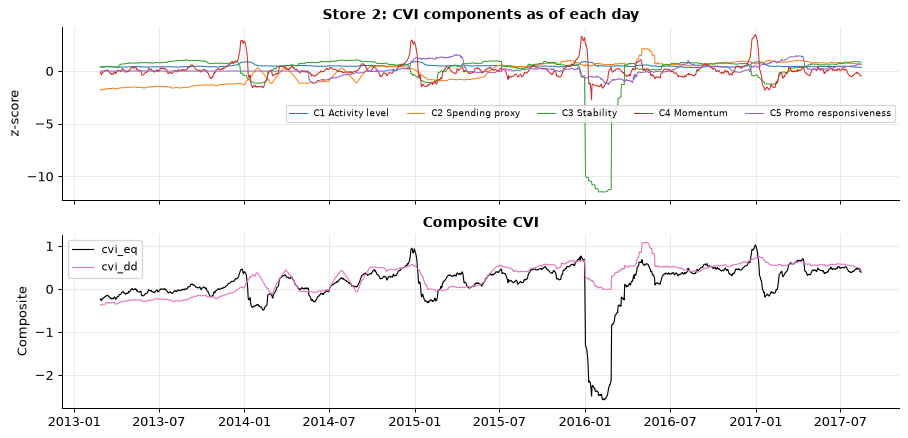

[OK] favorita | CVI figures | 8.9s


,z_c1_level,z_c2_spend,z_c3_stability,z_c4_momentum,z_c5_promo,cvi_eq,cvi_dd,cvi_pca,s_ma28,p_momentum,p_stability
z_c1_level,1.0000,0.0580,0.0660,0.0620,0.1540,0.5690,0.8530,0.1310,0.8350,0.0430,0.0410
z_c2_spend,0.0580,1.0000,-0.1440,-0.0400,0.0100,0.4730,0.5310,-0.5690,0.5630,0.0680,-0.1950
z_c3_stability,0.0660,-0.1440,1.0000,0.1360,-0.1030,0.2750,0.0250,0.6350,-0.0270,0.1380,0.5840
z_c4_momentum,0.0620,-0.0400,0.1360,1.0000,0.0430,0.4620,0.0350,0.5260,0.0270,0.6070,0.1320
z_c5_promo,0.1540,0.0100,-0.1030,0.0430,1.0000,0.3380,0.1220,-0.2160,0.1250,-0.0380,-0.0270
cvi_eq,0.5690,0.4730,0.2750,0.4620,0.3380,1.0000,0.7390,0.1460,0.7240,0.3490,0.1400
cvi_dd,0.8530,0.5310,0.0250,0.0350,0.1220,0.7390,1.0000,-0.1360,0.9970,0.0700,-0.0400
cvi_pca,0.1310,-0.5690,0.6350,0.5260,-0.2160,0.1460,-0.1360,1.0000,-0.1850,0.3370,0.4710
s_ma28,0.8350,0.5630,-0.0270,0.0270,0.1250,0.7240,0.9970,-0.1850,1.0000,0.0650,-0.0780
p_momentum,0.0430,0.0680,0.1380,0.6070,-0.0380,0.3490,0.0700,0.3370,0.0650,1.0000,0.0910


confounding: {'naive 7/28 momentum': 0.006, 'C4 momentum (14/56)': -0.02, 'C3 stability': -0.03}


[OK] favorita | build horizon frames | 2.9s


,rows,stores,first,last,days,mean_sales
split,,,,,,
train,55935,53,2013-05-01,2016-06-30,1154,"12,248.7705"
val,9519,53,2016-07-01,2016-12-31,183,"15,405.5947"
test,12014,54,2017-01-01,2017-08-15,227,"16,009.1289"


[OK] favorita | seasonal naive | 0.0s


... (113 outputs left out)

  TCN A h=14: 21 epochs run (best epoch 11), val MAE 1,640.2, 7.1 min
[OK] favorita | TCN A h=14 | 423.8s


  TCN D h=14: 36 epochs run (best epoch 26), val MAE 1,543.0, 12.3 min
[OK] favorita | TCN D h=14 | 736.8s


  TCN A h=28: 27 epochs run (best epoch 17), val MAE 1,771.0, 12.4 min
[OK] favorita | TCN A h=28 | 743.2s


  TCN D h=28: 36 epochs run (best epoch 26), val MAE 1,727.5, 17.6 min
[OK] favorita | TCN D h=28 | 1055.1s


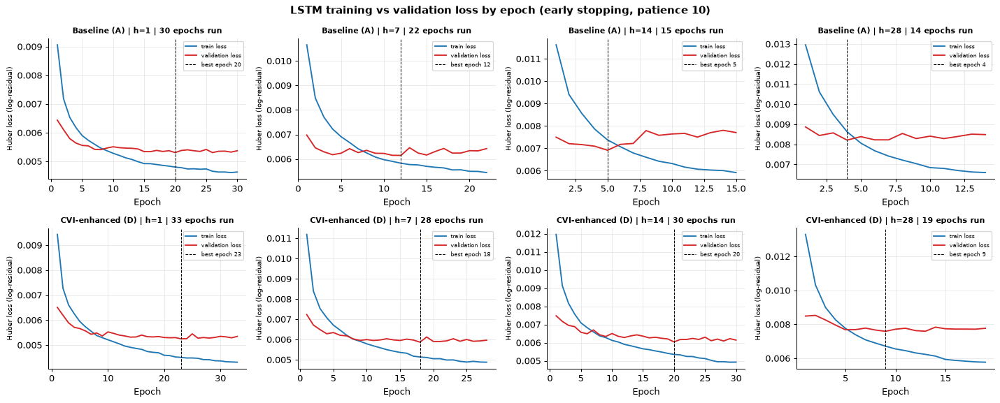

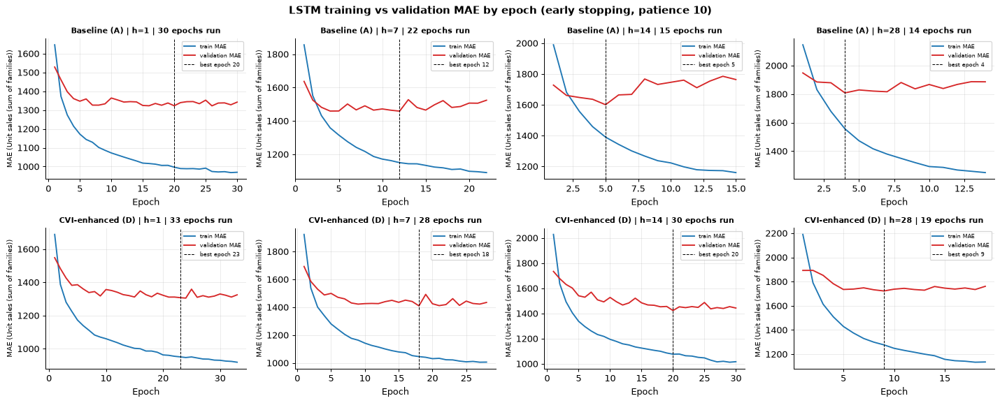

,model,cfg,h,epochs_run,best_epoch,stopped_early,best_val_loss,val_MAE_best,train_samples,minutes,checkpoint,n_params
0,LSTM,A,1,30,20,True,0.0053,"1,323.0436",55935,6.3356,cvi_outputs\favorita\checkpoints\lstm_A_h1.pt,60161
1,LSTM,D,1,33,23,True,0.0053,"1,307.6459",55935,7.2767,cvi_outputs\favorita\checkpoints\lstm_D_h1.pt,61697
2,LSTM,A,7,22,12,True,0.0061,"1,458.6784",55935,4.7593,cvi_outputs\favorita\checkpoints\lstm_A_h7.pt,60161
3,LSTM,D,7,28,18,True,0.0059,"1,410.0772",55935,6.1823,cvi_outputs\favorita\checkpoints\lstm_D_h7.pt,61697
4,LSTM,A,14,15,5,True,0.0069,"1,600.6665",55935,3.2362,cvi_outputs\favorita\checkpoints\lstm_A_h14.pt,60161
5,LSTM,D,14,30,20,True,0.0060,"1,423.2049",55935,6.6067,cvi_outputs\favorita\checkpoints\lstm_D_h14.pt,61697
6,LSTM,A,28,14,4,True,0.0082,"1,808.3059",55935,3.0146,cvi_outputs\favorita\checkpoints\lstm_A_h28.pt,60161
7,LSTM,D,28,19,9,True,0.0076,"1,722.5664",55935,4.1785,cvi_outputs\favorita\checkpoints\lstm_D_h28.pt,61697


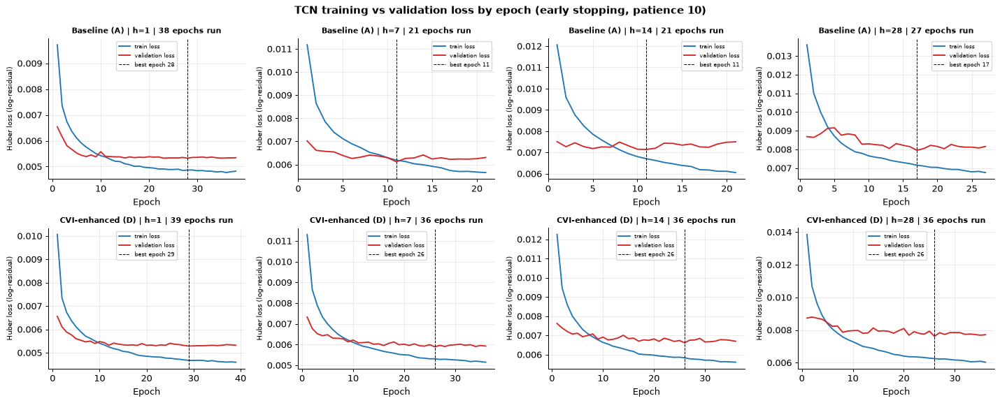

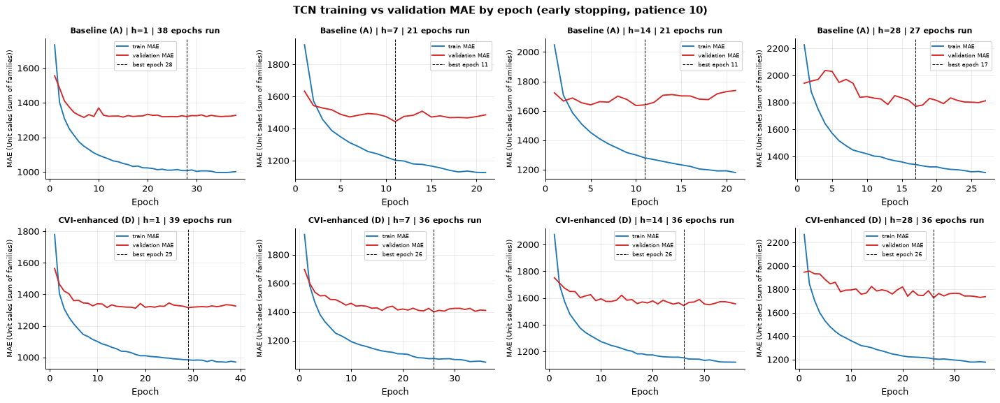

,model,cfg,h,epochs_run,best_epoch,stopped_early,best_val_loss,val_MAE_best,train_samples,minutes,checkpoint,n_params
0,TCN,A,1,38,28,True,0.0053,"1,320.0146",55935,12.6660,cvi_outputs\favorita\checkpoints\tcn_A_h1.pt,28833
1,TCN,D,1,39,29,True,0.0053,"1,315.4352",55935,13.8661,cvi_outputs\favorita\checkpoints\tcn_D_h1.pt,29601
2,TCN,A,7,21,11,True,0.0061,"1,443.2433",55935,7.0679,cvi_outputs\favorita\checkpoints\tcn_A_h7.pt,28833
3,TCN,D,7,36,26,True,0.0059,"1,399.8715",55935,12.8934,cvi_outputs\favorita\checkpoints\tcn_D_h7.pt,29601
4,TCN,A,14,21,11,True,0.0071,"1,640.1981",55935,7.0551,cvi_outputs\favorita\checkpoints\tcn_A_h14.pt,28833
5,TCN,D,14,36,26,True,0.0066,"1,543.0124",55935,12.2721,cvi_outputs\favorita\checkpoints\tcn_D_h14.pt,29601
6,TCN,A,28,27,17,True,0.0080,"1,771.0102",55935,12.3790,cvi_outputs\favorita\checkpoints\tcn_A_h28.pt,28833
7,TCN,D,28,36,26,True,0.0076,"1,727.4830",55935,17.5767,cvi_outputs\favorita\checkpoints\tcn_D_h28.pt,29601


[OK] favorita | evaluate | 7.5s


**Required final comparison table: Favorita (test period)**

,Model,Feature configuration,Horizon,Stores,MAE,RMSE,WAPE_%,R2,Improvement_%
0,Ridge,Baseline,1 day,all,"1,829.3","3,128.2",11.43,0.9201,—
1,Ridge,Baseline + CVI,1 day,all,"1,822.4","3,119.7",11.38,0.9206,+0.38
2,RandomForest,Baseline,1 day,all,"1,664.6","2,869.2",10.40,0.9328,—
3,RandomForest,Baseline + CVI,1 day,all,"1,662.1","2,883.6",10.38,0.9321,+0.15
4,LightGBM,Baseline,1 day,all,"1,510.7","2,610.7",9.44,0.9444,—
5,LightGBM,Baseline + CVI,1 day,all,"1,508.5","2,659.6",9.42,0.9423,+0.14
6,LSTM,Baseline,1 day,LSTM subset,"1,520.9","2,607.6",9.51,0.9446,—
7,LSTM,Baseline + CVI,1 day,LSTM subset,"1,463.0","2,502.2",9.15,0.9490,+3.81
8,TCN,Baseline,1 day,LSTM subset,"1,509.0","2,605.4",9.44,0.9447,—
9,TCN,Baseline + CVI,1 day,LSTM subset,"1,497.1","2,628.4",9.36,0.9437,+0.79


,configuration,MAE h=1,MAE h=7,MAE h=14,MAE h=28,Imp% h=1,Imp% h=7,Imp% h=14,Imp% h=28
cfg,,,,,,,,,
A,Baseline,"1,510.7230","1,597.9040","1,653.6890","1,810.6360",0.0000,0.0000,0.0000,0.0000
B,Baseline + CVI components,"1,503.7680","1,610.6630","1,737.1950","1,808.7210",0.4600,-0.7980,-5.0500,0.1060
C,Baseline + composite CVI,"1,511.1890","1,627.5820","1,726.7790","1,811.5610",-0.0310,-1.8570,-4.4200,-0.0510
D,Baseline + CVI,"1,508.5450","1,639.1050","1,756.6060","1,821.1510",0.1440,-2.5780,-6.2230,-0.5810
E,Baseline + raw activity,"1,482.9510","1,568.0950","1,616.1680","1,714.2940",1.8380,1.8660,2.2690,5.3210
C_dd,Baseline + data-driven CVI,"1,507.5530","1,595.0600","1,669.6160","1,811.3450",0.2100,0.1780,-0.9630,-0.0390
P,Baseline + sales analogue,"1,500.3980","1,602.0330","1,704.6520","1,886.7940",0.6830,-0.2580,-3.0820,-4.2060
ORACLE,ORACLE same-day activity (leaky),"1,281.2550","1,363.2760","1,390.8120","1,475.3860",15.1890,14.6840,15.8960,18.5160
A+c1_level,Baseline + c1_level,"1,489.1430","1,573.9300","1,629.0330","1,724.6430",1.4280,1.5000,1.4910,4.7490


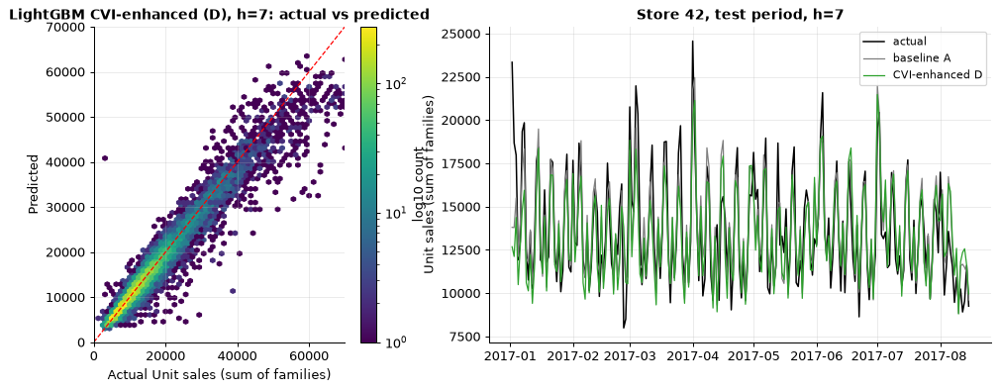

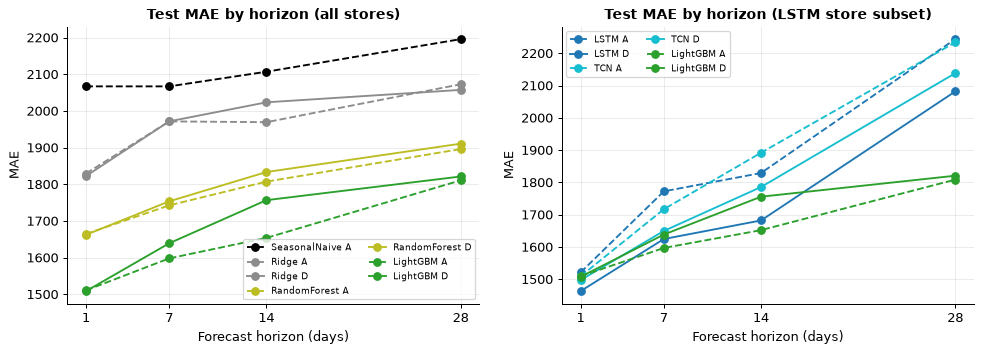

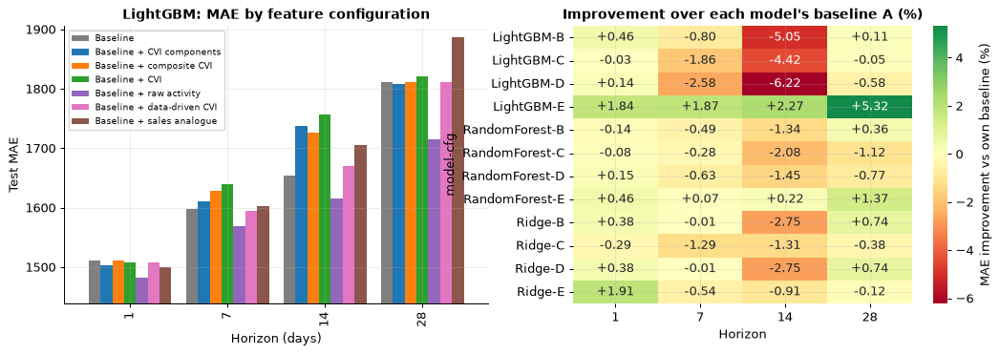

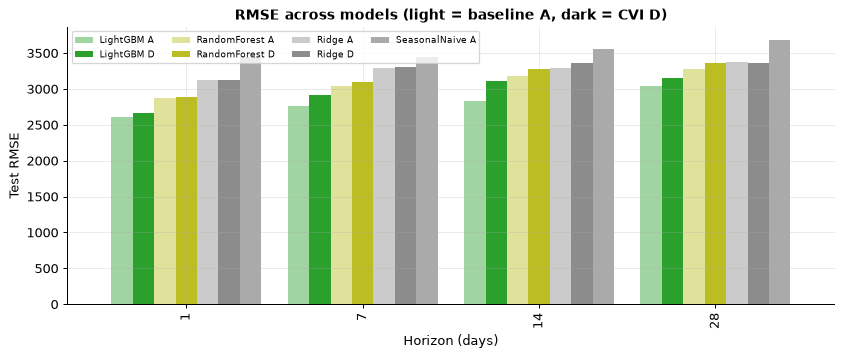

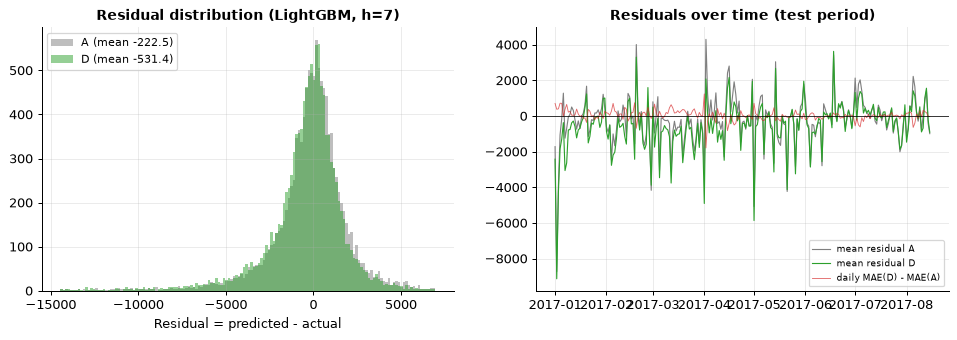

[OK] favorita | result figures | 10.2s


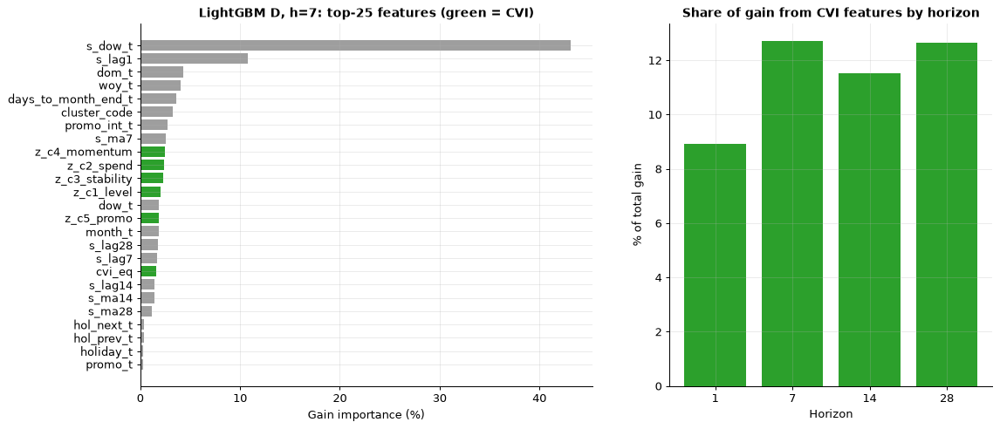

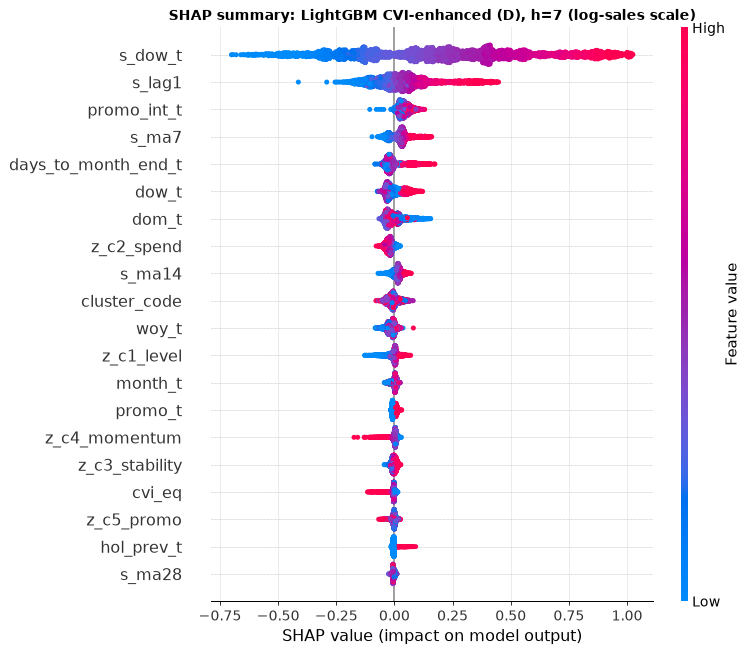

[OK] favorita | importance & SHAP | 54.9s


,mean|SHAP|,is_CVI
s_dow_t,0.3665,False
s_lag1,0.0967,False
promo_int_t,0.0417,False
s_ma7,0.0356,False
days_to_month_end_t,0.0345,False
dow_t,0.0311,False
dom_t,0.0297,False
z_c2_spend,0.0235,True
s_ma14,0.0188,False
cluster_code,0.0185,False


C:\Users\Pc Planet\AppData\Local\Temp\ipykernel_18624\2019297612.py:114: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  q['mean'] = q.mean(1)


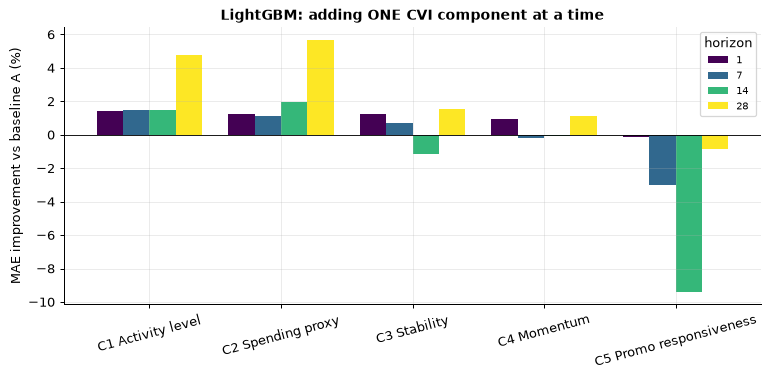

[OK] favorita | component ablation | 1.0s


h,1,7,14,28,mean
C1 Activity level,1.4280,1.5000,1.4910,4.7490,2.2920
C2 Spending proxy,1.2620,1.1380,1.9850,5.6780,2.5160
C3 Stability,1.2420,0.6860,-1.1490,1.5630,0.5850
C4 Momentum,0.9180,-0.1650,-0.0570,1.0930,0.4470
C5 Promo responsiveness,-0.1630,-3.0020,-9.3940,-0.8480,-3.3520


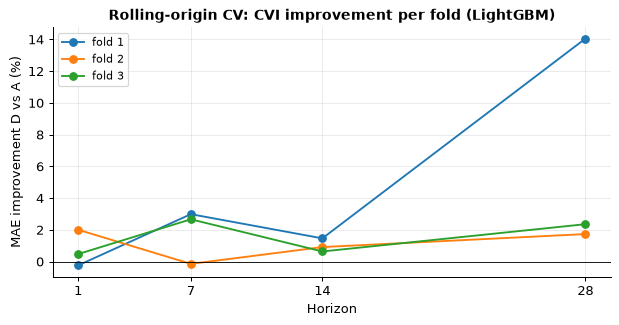

[OK] favorita | rolling-origin CV | 187.7s


cfg,fold,h,A,D,Improvement_%
0,1,1,955.8805,958.1402,-0.2364
1,1,7,"1,054.0494","1,022.5082",2.9924
2,1,14,"1,124.7553","1,108.2382",1.4685
3,1,28,"1,406.6831","1,208.9635",14.0557
4,2,1,"1,098.4872","1,076.3846",2.0121
5,2,7,"1,137.4248","1,139.0082",-0.1392
6,2,14,"1,236.7535","1,225.3927",0.9186
7,2,28,"1,405.4707","1,381.0347",1.7386
8,3,1,"1,783.2283","1,774.7232",0.4769
9,3,7,"1,876.7552","1,826.6638",2.6690


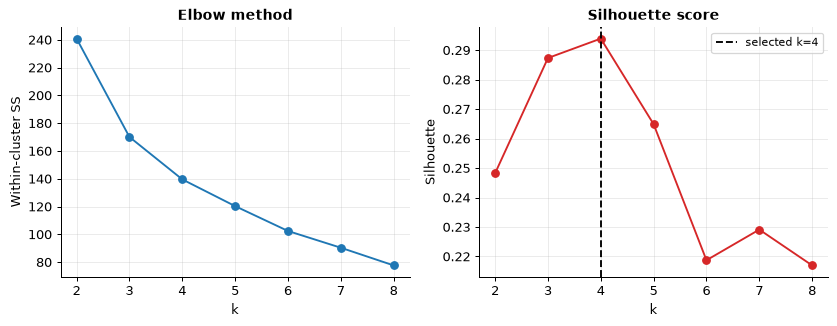

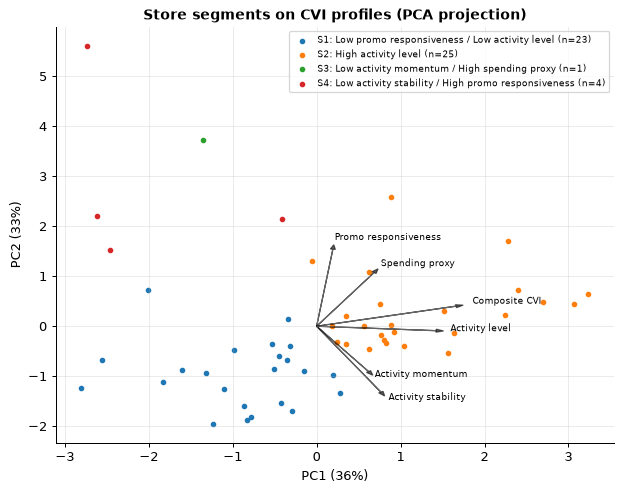

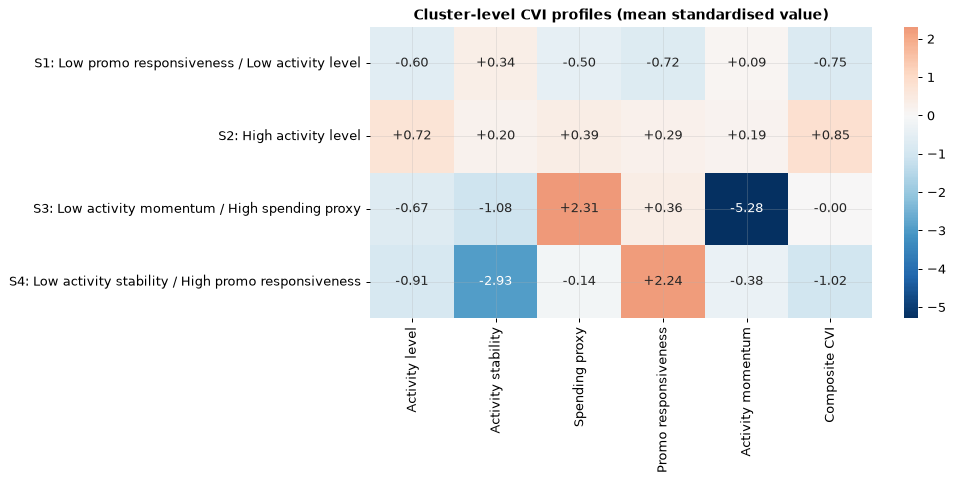

[OK] favorita | segmentation | 4.4s


,k,inertia,silhouette
0,2,240.8412,0.2482
1,3,170.0652,0.2873
2,4,139.5593,0.2939
3,5,120.3251,0.2649
4,6,102.4315,0.2187
5,7,90.3873,0.2291
6,8,77.6661,0.2170


,Activity level,Activity stability,Spending proxy,Promo responsiveness,Activity momentum,Composite CVI
S1: Low promo responsiveness / Low activity level,-0.6000,0.3400,-0.5000,-0.7200,0.0900,-0.7500
S2: High activity level,0.7200,0.2000,0.3900,0.2900,0.1900,0.8500
S3: Low activity momentum / High spending proxy,-0.6700,-1.0800,2.3100,0.3600,-5.2800,-0.0000
S4: Low activity stability / High promo responsiveness,-0.9100,-2.9300,-0.1400,2.2400,-0.3800,-1.0200


{'k': 4, 'silhouette': 0.29393282989792213, 'best_k_global': 4, 'ari_vs_sales_only': 0.6876679088309212, 'sales_only_silhouette': 0.30663856692839075, 'all_clusters_distinct': True, 'sizes': {'S2: High activity level': 25, 'S1: Low promo responsiveness / Low activity level': 23, 'S4: Low activity stability / High promo responsiveness': 4, 'S3: Low activity momentum / High spending proxy': 1}}


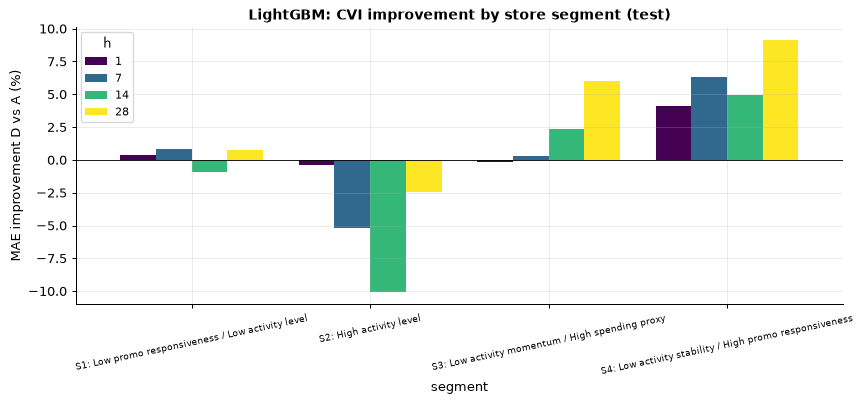

[OK] favorita | segment performance | 1.2s


,h,segment,stores,pooled_imp_pct,median_store_imp_pct,win_rate_pct,MAE_A,MAE_D
0,1,S1: Low promo responsiveness / Low activity level,23,0.4000,0.4700,52.1700,996.8500,992.9000
1,1,S2: High activity level,25,-0.3600,0.1500,52.0000,"2,037.0800","2,044.4300"
2,1,S3: Low activity momentum / High spending proxy,1,-0.1300,-0.1300,0.0000,"1,359.7000","1,361.4400"
3,1,S4: Low activity stability / High promo respon...,4,4.1100,3.7100,100.0000,"1,194.5400","1,145.3800"
4,7,S1: Low promo responsiveness / Low activity level,23,0.8600,0.9600,69.5700,"1,061.5800","1,052.4200"
5,7,S2: High activity level,25,-5.1600,-3.5000,32.0000,"2,135.4600","2,245.7500"
6,7,S3: Low activity momentum / High spending proxy,1,0.2700,0.2700,100.0000,"1,415.0600","1,411.2000"
7,7,S4: Low activity stability / High promo respon...,4,6.3400,6.7500,100.0000,"1,352.7800","1,266.9800"
8,14,S1: Low promo responsiveness / Low activity level,23,-0.8900,-0.6300,34.7800,"1,077.6400","1,087.2200"
9,14,S2: High activity level,25,-10.0300,-4.0800,28.0000,"2,226.7200","2,450.1500"


,h,kruskal_p_CVI_segments,kruskal_p_sales_segments,kruskal_p_holm
0,1,0.0839,0.0456,0.1678
1,7,0.0163,0.0086,0.0653
2,14,0.0336,0.0131,0.1008
3,28,0.1011,0.1108,0.1678


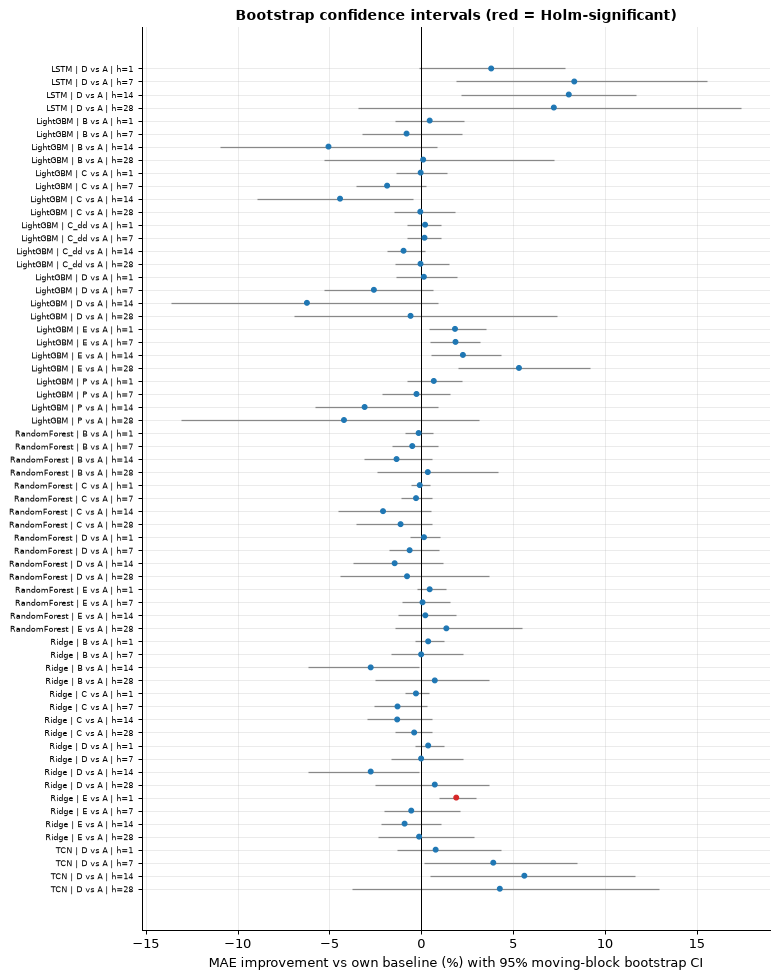

[OK] favorita | statistical tests | 8.9s


**primary**

,model,comparison,h,block,B,days,rows,MAE_A,MAE_X,dMAE,dMAE_lo,dMAE_hi,imp_pct,imp_lo,imp_hi,p_boot,ci_includes_zero,p_holm
0,LightGBM,D vs A,1,7,2000,227,12014,"1,510.7227","1,508.5447",2.1780,-20.2906,29.0653,0.1442,-1.3943,1.9466,0.8706,True,1.0000
1,LightGBM,D vs A,7,7,2000,227,12014,"1,597.9045","1,639.1048",-41.2003,-83.7936,9.6785,-2.5784,-5.3116,0.6248,0.0890,True,0.3558
2,LightGBM,D vs A,14,14,2000,227,12014,"1,653.6891","1,756.6055",-102.9164,-218.1885,14.6174,-6.2234,-13.6422,0.9082,0.0895,True,0.3558
3,LightGBM,D vs A,28,28,2000,227,12014,"1,810.6362","1,821.1508",-10.5146,-122.0779,133.0655,-0.5807,-6.9129,7.3688,0.8766,True,1.0000


**dm**

,model,comparison,h,DM,DM_HLN,p_DM,days,hac_lags,p_holm
0,LightGBM,D vs A,1,0.1869,0.1865,0.8522,227,7,1.0000
1,LightGBM,D vs A,7,-1.6703,-1.6225,0.1061,227,7,0.4244
2,LightGBM,D vs A,14,-1.7238,-1.6213,0.1064,227,13,0.4244
3,LightGBM,D vs A,28,-0.1647,-0.1447,0.8850,227,27,1.0000


**h2**

... (5 outputs left out)

[OK] favorita | leakage audit | 6.1s


,check,result,evidence
0,Feature provenance: every non-oracle feature a...,PASS,56 features documented; offending: []
1,Same-day activity only in ORACLE,PASS,"a_same_day absent from configs A-E, C_dd, P, A+Ck"
2,Rolling windows end at origin (state_date <= t...,PASS,"h=1: max(origin-state_date)>=0, rows=77,468; h..."
3,No store-date duplicates in any frame,PASS,"unique (store,date) in all horizon frames"
4,"Temporal split boundaries ordered, no overlap",PASS,"{'test': {'min': '2017-01-01', 'max': '2017-08..."
5,CVI standardiser / weights fitted on training ...,PASS,fit_max_state_date=2016-06-30 <= train_end=201...
6,Perturbation invariance (future sales/activity...,PASS,"11,830,658 feature values re-computed; 0 misma..."
7,Power check (features after the cut-off DO cha...,PASS,"share of post-cut-off rows changed: [1.0, 1.0,..."
8,Shuffled-target sanity test,PASS,test R2 shuffled = -0.342 vs real = 0.931; MAE...
9,Oracle diagnostic computed (reported as upper ...,PASS,"ORACLE MAE improvement vs A: h=1: +15.2%, h=7:..."


,h,tau,stores,values_checked,mismatches_pre_cutoff,post_rows,share_post_rows_changed
0,1,2016-08-30,54,2928926,0,18354,1.0000
1,7,2016-08-30,54,2943920,0,18030,1.0000
2,14,2016-08-30,54,2961413,0,17652,1.0000
3,28,2016-08-30,54,2996399,0,16897,1.0000


Favorita pipeline completed: True in 157.4 min


In [ ]:
def run_pipeline(ctx):
    raw = run_step(ctx, 'load', load_dataset, ctx)
    if raw is None:
        return False
    display(describe_raw(raw))
    v = run_step(ctx, 'validation', validate_rossmann if ctx['name'] == 'rossmann' else validate_favorita, ctx, raw)
    if v is None:
        return False
    ctx['audit'], miss = v; display(ctx['audit'])
    if run_step(ctx, 'preprocess', preprocess, ctx, raw) is None:
        return False
    display(pd.DataFrame(ctx['decisions']))
    run_step(ctx, 'data-quality figures', plot_data_quality, ctx, miss)
    run_eda(ctx); print(json.dumps(ctx.get('eda_stats', {}), indent=1, default=str))
    st = run_step(ctx, 'build state', build_state, ctx, ctx['daily'])
    if st is None:
        return False
    ctx['state'], ctx['td'] = st
    ctx['cvi_meta'] = run_step(ctx, 'fit CVI', fit_cvi, ctx['state'], ctx['splits']['train_end'], CONFIG['min_history'])
    print(json.dumps(ctx['cvi_meta'], indent=1, default=str))
    out = run_step(ctx, 'CVI figures', cvi_figures, ctx)
    if out: display(out['corr']); print('confounding:', out['confounding'])
    feature_sets(ctx)
    if run_step(ctx, 'build horizon frames', build_all_frames, ctx) is None:
        return False
    display(split_table(ctx))
    run_step(ctx, 'seasonal naive', run_naive, ctx)
    display(run_step(ctx, 'LightGBM tuning', tune_lgb, ctx))
    run_tabular_models(ctx)
    print(run_step(ctx, 'prepare sequences', prep_sequences, ctx))
    run_seq_models(ctx)
    display(plot_lstm_curves(ctx, 'LSTM')); display(plot_lstm_curves(ctx, 'TCN'))
    run_step(ctx, 'evaluate', evaluate, ctx)
    m = main_comparison_table(ctx)
    md(f"**Required final comparison table: {ctx['name'].title()} (test period)**")
    display(m.style.format({'MAE': '{:,.1f}', 'RMSE': '{:,.1f}', 'WAPE_%': '{:.2f}', 'R2': '{:.4f}', 'Improvement_%': '{:+.2f}'}, na_rep='—'))
    ct = config_table(ctx); display(ct.round(3))
    run_step(ctx, 'result figures', result_figures, ctx)
    display(run_step(ctx, 'importance & SHAP', importance_figures, ctx))
    display(run_step(ctx, 'component ablation', component_figure, ctx))
    display(run_step(ctx, 'rolling-origin CV', rolling_origin_cv, ctx))
    sg = run_step(ctx, 'segmentation', segmentation, ctx)
    if sg: display(sg[0]); display(sg[1].round(2)); print(sg[2])
    sp = run_step(ctx, 'segment performance', segment_performance, ctx)
    if sp: display(sp[0].round(2)); display(sp[1])
    stt = run_step(ctx, 'statistical tests', statistical_tests, ctx)
    if stt:
        for k in ['primary', 'dm', 'h2', 'h3', 'wilcoxon']:
            md(f'**{k}**'); display(stt[k].round(4))
    display(run_step(ctx, 'leakage audit', leakage_audit, ctx)); display(ctx.get('perturbation'))
    return True

Fv = make_context('favorita')
t0 = time.time()
FAV_OK = run_pipeline(Fv)
print(f'Favorita pipeline completed: {FAV_OK} in {(time.time() - t0) / 60:.1f} min')

**Interpretation: Favorita replication.**

*Data.*
* The data has 54 stores and 83,606 trading store-days. Of these:
  * 216 store-days are chain-wide closures (25 December).
  * 7,330 zero-sales store-days (pre-opening or temporary closure) are treated as non-trading.
  * 118 trading days without a `transactions` record get **missing** activity, not zero.
* Sales peak at the weekend (Saturday and Sunday), unlike Rossmann.
* The pooled same-day correlation is similar (0.84), but the within-store median is only 0.62.
* **Promotions raise sales by 33 % but transactions by only 1.6 %.** In Favorita promotions increase basket size, not traffic, so the activity-based promotion component has little to measure.
* Promotions are almost absent before 2014, so C5 was missing for 29 % of state rows before imputation.

*Forecasting (LightGBM D vs A).*
* Improvements are +0.14 / −2.58 / −6.22 / −0.58 %, none significant (Holm p ≥ 0.36).
* The single-component ablation explains this. Activity level (+2.3 % average) and the spending proxy (+2.5 %) help, but **promotion responsiveness hurts badly** (−3.35 % average, −9.4 % at h = 14) and drags down the combined configurations.
* **Raw transaction history (E) is the best customer-activity representation here:** +1.8 / +1.9 / +2.3 / +5.3 %.
* The sales-analogue control helps little or hurts (down to −4.2 % at h = 28).
* Rolling-origin CV in the validation period was mostly positive for D (10 of 12 fold-horizons), so the negative test result also points to a **regime change in 2017**.

*Sequence models.* The CVI-enhanced LSTM gains +3.8 to +8.3 % on all 53 stores with training history. However, the baseline LSTM stopped at epochs 4–5 at h = 14 and h = 28 and is up to 24 % worse than baseline LightGBM. These gains partly repair a weak baseline and should not be read as evidence for the CVI.

*Segmentation.* The silhouette is 0.29 (k = 4), but one cluster contains a single store and another four stores, and the ARI with the sales-only clustering is 0.69. Profiling is largely redundant with sales on this dataset.

*Leakage audit.* All checks pass: 11.8 M values with 0 mismatches; shuffled-target R² = −0.34.

The oracle gap is smaller than Rossmann's (15–19 %), consistent with transactions being a coarser proxy than customer counts.

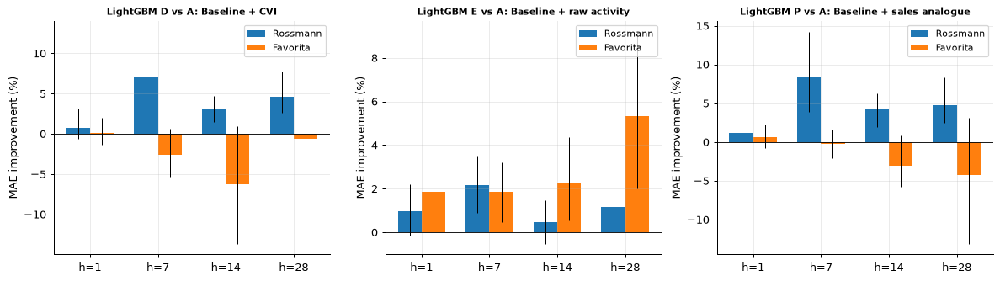

dataset              favorita  rossmann
comparison  h                          
B vs A      1.0000     0.4600    1.3080
            7.0000    -0.7980    6.5160
            14.0000   -5.0500    3.2780
            28.0000    0.1060    4.2480
C vs A      1.0000    -0.0310    0.2310
            7.0000    -1.8570    1.7310
            14.0000   -4.4200   -0.5940
            28.0000   -0.0510    0.5350
C_dd vs A   1.0000     0.2100    0.0740
            7.0000     0.1780    1.9430
            14.0000   -0.9630   -0.2650
            28.0000   -0.0390    1.6740
D vs A      1.0000     0.1440    0.7410
            7.0000    -2.5780    7.1020
            14.0000   -6.2230    3.1000
            28.0000   -0.5810    4.6510
E vs A      1.0000     1.8380    0.9790
            7.0000     1.8660    2.1760
            14.0000    2.2690    0.4820
            28.0000    5.3210    1.1420
ORACLE vs A 1.0000    15.1890   28.1700
            7.0000    14.6840   33.3680
            14.0000   15.8960   32.2910
            28.0000   18.5160   35.0670
P vs A      1.0000     0.6830    1.1860
            7.0000    -0.2580    8.3110
            14.0000   -3.0820    4.1870
            28.0000   -4.2060    4.7880

**Mean single-component improvement (%) by dataset (LightGBM, averaged over horizons)**

,rossmann,favorita
C1 Activity level,1.0250,2.2920
C2 Spending proxy,1.1770,2.5160
C3 Stability,1.2330,0.5850
C4 Momentum,1.5340,0.4470
C5 Promo responsiveness,1.9740,-3.3520


In [ ]:
def cross_dataset(ctxs):
    rows = []
    for c in ctxs:
        if 'stats' not in c:
            continue
        sec = c['stats']['secondary']
        for cmp_ in ['D vs A', 'B vs A', 'C vs A', 'E vs A', 'P vs A', 'C_dd vs A']:
            for h in CONFIG['horizons']:
                q = sec[(sec.model == 'LightGBM') & (sec.comparison == cmp_) & (sec.h == h)]
                if len(q):
                    q = q.iloc[0]
                    rows.append(dict(dataset=c['name'], comparison=cmp_, h=h, imp_pct=q.imp_pct, lo=q.imp_lo, hi=q.imp_hi, p_holm_all=q.p_holm_all))
        og = c.get('oracle_gap')
        if og is not None:
            for _, o in og.iterrows():
                rows.append(dict(dataset=c['name'], comparison='ORACLE vs A', h=o.h, imp_pct=o['Improvement_%'], lo=np.nan, hi=np.nan, p_holm_all=np.nan))
    X = pd.DataFrame(rows)
    if X.empty or X.dataset.nunique() < 2:
        return X, None
    fig, axs = plt.subplots(1, 3, figsize=(16, 4))
    for ax, cmp_ in zip(axs, ['D vs A', 'E vs A', 'P vs A']):
        q = X[X.comparison == cmp_]
        for i, (dsn, col) in enumerate([('rossmann', '#1f77b4'), ('favorita', '#ff7f0e')]):
            g = q[q.dataset == dsn].sort_values('h')
            xs = np.arange(len(g)) + (i - 0.5) * 0.35
            ax.bar(xs, g.imp_pct, width=0.35, color=col, label=dsn.title())
            ax.errorbar(xs, g.imp_pct, yerr=[g.imp_pct - g.lo, g.hi - g.imp_pct], fmt='none', ecolor='k', elinewidth=0.8)
        ax.set_xticks(range(len(CONFIG['horizons']))); ax.set_xticklabels([f'h={h}' for h in CONFIG['horizons']])
        ax.axhline(0, color='k', lw=0.7); ax.set_title(f'LightGBM {cmp_}: {CFG_LABEL[cmp_.split()[0]]}', fontsize=9); ax.set_ylabel('MAE improvement (%)'); ax.legend()
    save_fig(ctxs[0], fig, 'fig43_cross_dataset', 'Cross-dataset comparison.')
    comp = {}
    for c in ctxs:
        if 'component_gain' in c:
            comp[c['name']] = c['component_gain']['mean']
    comp = pd.DataFrame(comp)
    return X, comp

CTXS = [R] + ([Fv] if FAV_OK else [])
X_cross, comp_cross = cross_dataset(CTXS)
display(X_cross.pivot_table(index=['comparison', 'h'], columns='dataset', values='imp_pct').round(3) if len(X_cross) else 'Favorita not available')
if comp_cross is not None:
    md('**Mean single-component improvement (%) by dataset (LightGBM, averaged over horizons)**'); display(comp_cross.round(3))

**Interpretation: cross-dataset comparison (Fig. 43).**

* The two retailers **disagree**. The LightGBM CVI effect has the same sign at only 1 of 4 horizons.
* The component rankings are almost reversed (Spearman ρ = −0.90 across the five components):
  * On Rossmann, promotion responsiveness and momentum help most.
  * On Favorita, promotion responsiveness is the most harmful component, and level and spending help most.
* The one consistent finding is that raw activity history (E) gives small positive gains on both datasets.

The design generalises; the CVI weighting does not. A customer-value representation has to be adapted to how promotions act on each retailer: through traffic at Rossmann, through basket size at Favorita.

## 18. Final results and hypothesis evaluation

The verdicts below come from applying the decision rules pre-specified in Section 1.3 mechanically to the computed statistics. The narrative interpretation follows.

In [ ]:
def hypothesis_verdicts(ctx, other=None):
    V = []
    st = ctx.get('stats')
    if st is None:
        return pd.DataFrame([dict(hypothesis='all', verdict='NOT EVALUATED', evidence='statistics unavailable')])
    p = st['primary']
    pos = int(((p.imp_pct > 0) & (p.p_holm < 0.05)).sum()); neg = int(((p.imp_pct < 0) & (p.p_holm < 0.05)).sum())
    v1 = 'Supported' if pos >= 3 and neg == 0 else 'Partially supported' if pos >= 1 and neg == 0 else 'Rejected (CVI worse)' if neg > 0 and pos == 0 else 'Mixed' if neg > 0 else 'Not supported'
    V.append(dict(hypothesis='H1 Incremental predictive value', verdict=v1,
                  evidence='; '.join(f'h={r.h}: {r.imp_pct:+.2f}% [{r.imp_lo:+.2f},{r.imp_hi:+.2f}] p_holm={r.p_holm:.3f}' for r in p.itertuples())))
    h2 = st['h2']
    v2 = 'Supported' if h2.noninferior_margin_0p5.all() else 'Rejected' if h2.components_worse.any() else 'Inconclusive'
    V.append(dict(hypothesis='H2 Components >= composite', verdict=v2,
                  evidence='; '.join(f'h={r.h}: B-C={r.delta_B_minus_C_pct_of_A:+.2f}% [{r.lo:+.2f},{r.hi:+.2f}]' for r in h2.itertuples())))
    r3 = st['h3'].iloc[0]
    v3 = 'Supported' if r3.lo > 0 else 'Rejected (opposite direction)' if r3.hi < 0 else 'Not supported'
    V.append(dict(hypothesis='H3 Stronger at short horizons', verdict=v3,
                  evidence=f'{r3.contrast} = {r3.estimate:+.2f} pp [{r3.lo:+.2f},{r3.hi:+.2f}]; Spearman(h, imp)={st["h3_spearman"]:.2f}'))
    kw = ctx.get('segment_kw')
    if kw is not None:
        v4 = 'Supported' if (kw.kruskal_p_holm < 0.05).any() else 'Not supported'
        V.append(dict(hypothesis='H4 Segment heterogeneity', verdict=v4,
                      evidence='; '.join(f'h={r.h}: KW p_holm={r.kruskal_p_holm:.3f}' for r in kw.itertuples())))
    else:
        V.append(dict(hypothesis='H4 Segment heterogeneity', verdict='NOT EVALUATED', evidence='segmentation failed'))
    if other is not None and other.get('stats') is not None:
        a = ctx['stats']['primary'].set_index('h').imp_pct; b = other['stats']['primary'].set_index('h').imp_pct
        agree = int((np.sign(a) == np.sign(b)).sum())
        rho = stats.spearmanr(ctx['component_gain']['mean'], other['component_gain']['mean'])[0]
        crit = (agree >= 3) + (rho >= 0.5)
        v5 = 'Supported' if crit == 2 else 'Partially supported' if crit == 1 else 'Not supported'
        V.append(dict(hypothesis='H5 Cross-dataset robustness', verdict=v5,
                      evidence=f'sign agreement {agree}/4 horizons; Spearman of component gains rho={rho:.2f} (n=5 components)'))
    else:
        V.append(dict(hypothesis='H5 Cross-dataset robustness', verdict='NOT EVALUATED', evidence='second dataset unavailable'))
    s = ctx.get('seg_summary')
    if s:
        a_, b_, c_ = s['silhouette'] >= 0.2, s['all_clusters_distinct'], s['ari_vs_sales_only'] <= 0.5
        v6 = 'Supported' if a_ and b_ and c_ else 'Partially supported' if a_ and b_ else 'Not supported'
        V.append(dict(hypothesis='H6 Interpretability / profiling', verdict=v6,
                      evidence=f"k={s['k']}, silhouette={s['silhouette']:.3f}, distinct profiles={s['all_clusters_distinct']}, ARI vs sales-only={s['ari_vs_sales_only']:.3f}"))
    out = pd.DataFrame(V); out.insert(0, 'dataset', ctx['name'])
    return out

VERDICTS = pd.concat([hypothesis_verdicts(R, Fv if FAV_OK else None)] + ([hypothesis_verdicts(Fv, R)] if FAV_OK else []), ignore_index=True)
with pd.option_context('display.max_colwidth', 200):
    display(VERDICTS)

,dataset,hypothesis,verdict,evidence
0,rossmann,H1 Incremental predictive value,Supported,"h=1: +0.74% [-0.58,+3.15] p_holm=0.580; h=7: +7.10% [+2.61,+12.69] p_holm=0.011; h=14: +3.10% [+1.46,+4.69] p_holm=0.002; h=28: +4.65% [+2.64,+7.71] p_holm=0.002"
1,rossmann,H2 Components >= composite,Supported,"h=1: B-C=-1.08% [-3.22,+0.40]; h=7: B-C=-4.78% [-8.93,-1.48]; h=14: B-C=-3.87% [-5.93,-1.66]; h=28: B-C=-3.71% [-6.46,-2.23]"
2,rossmann,H3 Stronger at short horizons,Rejected (opposite direction),"Imp(h=1) - Imp(h=28) = -3.91 pp [-6.08,-0.77]; Spearman(h, imp)=0.40"
3,rossmann,H4 Segment heterogeneity,Supported,h=1: KW p_holm=0.000; h=7: KW p_holm=0.265; h=14: KW p_holm=0.004; h=28: KW p_holm=0.486
4,rossmann,H5 Cross-dataset robustness,Not supported,sign agreement 1/4 horizons; Spearman of component gains rho=-0.90 (n=5 components)
5,rossmann,H6 Interpretability / profiling,Not supported,"k=3, silhouette=0.195, distinct profiles=True, ARI vs sales-only=0.327"
6,favorita,H1 Incremental predictive value,Not supported,"h=1: +0.14% [-1.39,+1.95] p_holm=1.000; h=7: -2.58% [-5.31,+0.62] p_holm=0.356; h=14: -6.22% [-13.64,+0.91] p_holm=0.356; h=28: -0.58% [-6.91,+7.37] p_holm=1.000"
7,favorita,H2 Components >= composite,Inconclusive,"h=1: B-C=-0.49% [-1.52,+0.84]; h=7: B-C=-1.06% [-3.46,+1.09]; h=14: B-C=+0.63% [-2.98,+4.52]; h=28: B-C=-0.16% [-5.01,+4.08]"
8,favorita,H3 Stronger at short horizons,Not supported,"Imp(h=1) - Imp(h=28) = +0.72 pp [-5.13,+6.40]; Spearman(h, imp)=-0.40"
9,favorita,H4 Segment heterogeneity,Not supported,h=1: KW p_holm=0.168; h=7: KW p_holm=0.065; h=14: KW p_holm=0.101; h=28: KW p_holm=0.168


**Hypothesis outcomes (pre-specified rules applied mechanically):**

| | Rossmann | Favorita |
|---|---|---|
| **H1** incremental value | **Supported**: significant at h = 7, 14, 28 (+3.1 to +7.1 %), not at h = 1 | **Not supported**: no significant effect, point estimates mostly negative |
| **H2** components ≥ composite | **Supported**: components better at h ≥ 7 | **Inconclusive**: wide intervals |
| **H3** stronger at short horizons | **Rejected (opposite)**: gain smallest at h = 1 | **Not supported** |
| **H4** segment heterogeneity | **Supported** at h = 1 and h = 14 (also present for sales-only segments) | **Not supported** |
| **H5** cross-dataset robustness | **Not supported**: 1/4 sign agreement, ρ = −0.90 | — |
| **H6** interpretability | **Not supported** by the strict rule (silhouette 0.195 < 0.20). Profiles are distinct and non-redundant (ARI 0.33) | **Partially supported**: silhouette 0.29, but redundant with sales (ARI 0.69) and degenerate clusters |

In [ ]:
def summary_answers(ctx):
    st, r = ctx['stats'], ctx['results']
    te = r[(r.split == 'test') & (r.subset == 'all')]
    p = st['primary']
    lines = [f"### {ctx['name'].title()}"]
    lines.append(f"1. **CVI vs sales-only baseline (LightGBM D vs A):** " + ', '.join(f'h={x.h}: {x.imp_pct:+.2f}% (95% CI {x.imp_lo:+.2f} to {x.imp_hi:+.2f}, Holm p={x.p_holm:.3f})' for x in p.itertuples()))
    other = te[te.cfg.isin(['D']) & te.model.isin(['Ridge', 'RandomForest'])].pivot_table(index='model', columns='h', values='Improvement_%').round(2)
    lines.append(f"   Other learners, D vs own A (%): {other.to_dict('index')}. LSTM (store subset): " +
                 str(r[(r.split == 'test') & (r.subset == 'lstm_subset') & (r.model == 'LSTM') & (r.cfg == 'D')].set_index('h')['Improvement_%'].round(2).to_dict()))
    cg = ctx.get('component_gain')
    if cg is not None:
        best = cg['mean'].idxmax()
        lines.append(f"2. **Most informative component (single-component ablation, mean over horizons):** {best} ({cg['mean'].max():+.2f}%); ranking: " +
                     ', '.join(f'{k} {v:+.2f}%' for k, v in cg['mean'].sort_values(ascending=False).items()))
    sh = ctx.get('shap_mean_abs')
    if sh is not None:
        cs = sh[[c for c in COMP + ['cvi_eq'] if c in sh.index]].sort_values(ascending=False)
        lines.append(f"   SHAP rank among CVI features (h=7): " + ', '.join(f'{COMP_NAMES.get(k, k)}' for k in cs.index))
    ci = te[(te.model == 'LightGBM') & te.cfg.isin(['B', 'C', 'C_dd'])].pivot_table(index='cfg', columns='h', values='Improvement_%').round(2)
    lines.append(f"3. **Composite index:** LightGBM improvement (%) for components-only B / composite-only C / data-driven composite C_dd: {ci.to_dict('index')}")
    imp = p.set_index('h').imp_pct
    lines.append(f"4. **Horizon with the largest CVI gain:** h={imp.idxmax()} ({imp.max():+.2f}%); H3 contrast {st['h3'].iloc[0].contrast} = {st['h3'].iloc[0].estimate:+.2f} pp [{st['h3'].iloc[0].lo:+.2f}, {st['h3'].iloc[0].hi:+.2f}]")
    sp = ctx.get('segment_perf')
    if sp is not None:
        g = sp.groupby('segment').pooled_imp_pct.mean().sort_values(ascending=False)
        lines.append(f"5. **Segments (mean pooled improvement over horizons):** " + '; '.join(f'{k}: {v:+.2f}%' for k, v in g.items()))
    e = te[(te.model == 'LightGBM') & te.cfg.isin(['E', 'P', 'ORACLE'])].pivot_table(index='cfg', columns='h', values='Improvement_%').round(2)
    lines.append(f"   Context: raw activity E / sales-analogue P / ORACLE (leaky upper bound) improvements (%): {e.to_dict('index')}")
    return '\n'.join(lines)

for c in CTXS:
    if c.get('stats') is not None:
        md(summary_answers(c))

### Rossmann
1. **CVI vs sales-only baseline (LightGBM D vs A):** h=1: +0.74% (95% CI -0.58 to +3.15, Holm p=0.580), h=7: +7.10% (95% CI +2.61 to +12.69, Holm p=0.011), h=14: +3.10% (95% CI +1.46 to +4.69, Holm p=0.002), h=28: +4.65% (95% CI +2.64 to +7.71, Holm p=0.002)
   Other learners, D vs own A (%): {'RandomForest': {1: 1.47, 7: 3.8, 14: 2.54, 28: 2.77}, 'Ridge': {1: 0.35, 7: 0.29, 14: -0.44, 28: -0.69}}. LSTM (store subset): {1: 2.78, 7: 1.15, 14: 1.63, 28: -2.37}
2. **Most informative component (single-component ablation, mean over horizons):** C5 Promo responsiveness (+1.97%); ranking: C5 Promo responsiveness +1.97%, C4 Momentum +1.53%, C3 Stability +1.23%, C2 Spending proxy +1.18%, C1 Activity level +1.02%
   SHAP rank among CVI features (h=7): C4 Momentum, C5 Promo responsiveness, C1 Activity level, C3 Stability, C2 Spending proxy, cvi_eq
3. **Composite index:** LightGBM improvement (%) for components-only B / composite-only C / data-driven composite C_dd: {'B': {1: 1.31, 7: 6.52, 14: 3.28, 28: 4.25}, 'C': {1: 0.23, 7: 1.73, 14: -0.59, 28: 0.54}, 'C_dd': {1: 0.07, 7: 1.94, 14: -0.26, 28: 1.67}}
4. **Horizon with the largest CVI gain:** h=7 (+7.10%); H3 contrast Imp(h=1) - Imp(h=28) = -3.91 pp [-6.08, -0.77]
5. **Segments (mean pooled improvement over horizons):** S2: Low promo responsiveness / Low activity level: +4.54%; S3: High activity level / Low spending proxy: +4.03%; S1: High promo responsiveness / High spending proxy: +3.39%
   Context: raw activity E / sales-analogue P / ORACLE (leaky upper bound) improvements (%): {'E': {1: 0.98, 7: 2.18, 14: 0.48, 28: 1.14}, 'ORACLE': {1: 28.17, 7: 33.37, 14: 32.29, 28: 35.07}, 'P': {1: 1.19, 7: 8.31, 14: 4.19, 28: 4.79}}

### Favorita
1. **CVI vs sales-only baseline (LightGBM D vs A):** h=1: +0.14% (95% CI -1.39 to +1.95, Holm p=1.000), h=7: -2.58% (95% CI -5.31 to +0.62, Holm p=0.356), h=14: -6.22% (95% CI -13.64 to +0.91, Holm p=0.356), h=28: -0.58% (95% CI -6.91 to +7.37, Holm p=1.000)
   Other learners, D vs own A (%): {'RandomForest': {1: 0.15, 7: -0.63, 14: -1.45, 28: -0.77}, 'Ridge': {1: 0.38, 7: -0.01, 14: -2.75, 28: 0.74}}. LSTM (store subset): {1: 3.81, 7: 8.33, 14: 8.03, 28: 7.22}
2. **Most informative component (single-component ablation, mean over horizons):** C2 Spending proxy (+2.52%); ranking: C2 Spending proxy +2.52%, C1 Activity level +2.29%, C3 Stability +0.59%, C4 Momentum +0.45%, C5 Promo responsiveness -3.35%
   SHAP rank among CVI features (h=7): C2 Spending proxy, C1 Activity level, C4 Momentum, C3 Stability, cvi_eq, C5 Promo responsiveness
3. **Composite index:** LightGBM improvement (%) for components-only B / composite-only C / data-driven composite C_dd: {'B': {1: 0.46, 7: -0.8, 14: -5.05, 28: 0.11}, 'C': {1: -0.03, 7: -1.86, 14: -4.42, 28: -0.05}, 'C_dd': {1: 0.21, 7: 0.18, 14: -0.96, 28: -0.04}}
4. **Horizon with the largest CVI gain:** h=1 (+0.14%); H3 contrast Imp(h=1) - Imp(h=28) = +0.72 pp [-5.13, +6.40]
5. **Segments (mean pooled improvement over horizons):** S4: Low activity stability / High promo responsiveness: +6.15%; S3: Low activity momentum / High spending proxy: +2.12%; S1: Low promo responsiveness / Low activity level: +0.29%; S2: High activity level: -4.51%
   Context: raw activity E / sales-analogue P / ORACLE (leaky upper bound) improvements (%): {'E': {1: 1.84, 7: 1.87, 14: 2.27, 28: 5.32}, 'ORACLE': {1: 15.19, 7: 14.68, 14: 15.9, 28: 18.52}, 'P': {1: 0.68, 7: -0.26, 14: -3.08, 28: -4.21}}

### Post-hoc attribution analysis (exploratory, not pre-specified)

The ablation suggested that the sales-analogue control performs as well as the CVI. The cell below tests this directly with the same paired moving-block bootstrap. It is reported as **post-hoc** and does not change any pre-specified verdict.

In [ ]:
# Post-hoc attribution analysis (NOT pre-specified; reported as exploratory).
# Is the CVI gain due to CUSTOMER information, or to the feature-construction recipe?
# Direct paired contrasts between LightGBM configurations, same moving-block bootstrap as Section 15,
# computed from the saved test predictions so this cell is self-contained.
import numpy as np, pandas as pd
from pathlib import Path
OUT = Path(CONFIG['out_dir']) if 'CONFIG' in globals() else Path('cvi_outputs')
def _boot(sa, sx, n, b, B=2000, seed=7):
    rng = np.random.RandomState(seed); nb = int(np.ceil(len(sa) / b))
    idx = (rng.randint(0, len(sa) - b + 1, size=(B, nb))[:, :, None] + np.arange(b)).reshape(B, -1)[:, :len(sa)]
    imp_b = 100 * (sa[idx].sum(1) - sx[idx].sum(1)) / sa[idx].sum(1)
    imp = 100 * (sa.sum() - sx.sum()) / sa.sum()
    p = (1 + np.sum(np.abs(imp_b - imp) >= abs(imp))) / (B + 1)
    return imp, *np.percentile(imp_b, [2.5, 97.5]), p
rows = []
for ds in ['rossmann', 'favorita']:
    f = OUT / ds / 'predictions' / 'test_predictions_all.parquet'
    if not f.exists():
        continue
    P = pd.read_parquet(f)
    for h, g in P.groupby('h'):
        codes, _ = pd.factorize(g.date, sort=True)
        ae = lambda c: np.bincount(codes, np.abs(g[f'LightGBM__{c}'].values - g.y.values))
        for ref, x, label in [('P', 'D', 'CVI-enhanced (D) vs sales-analogue control (P)'),
                              ('P', 'B', 'CVI components (B) vs sales-analogue control (P)'),
                              ('E', 'D', 'CVI-enhanced (D) vs raw activity history (E)'),
                              ('A', 'E', 'raw activity history (E) vs baseline (A)')]:
            imp, lo, hi, p = _boot(ae(ref), ae(x), None, max(7, h))
            rows.append(dict(dataset=ds, h=h, contrast=label, improvement_pct=imp, ci_lo=lo, ci_hi=hi, p_boot=p))
posthoc = pd.DataFrame(rows)
posthoc['p_holm'] = np.nan
for ds, g in posthoc.groupby('dataset'):
    p = g.p_boot.values; o = np.argsort(p); adj = np.empty(len(p)); run = 0
    for i, j in enumerate(o):
        run = max(run, min(1, (len(p) - i) * p[j])); adj[j] = run
    posthoc.loc[g.index, 'p_holm'] = adj
posthoc.to_csv(OUT / 'posthoc_attribution_contrasts.csv', index=False)
display(posthoc.round(3))


,dataset,h,contrast,improvement_pct,ci_lo,ci_hi,p_boot,p_holm
0,rossmann,1,CVI-enhanced (D) vs sales-analogue control (P),-0.450,-1.380,0.130,0.352,1.000
1,rossmann,1,CVI components (B) vs sales-analogue control (P),0.124,-1.060,0.669,0.897,1.000
2,rossmann,1,CVI-enhanced (D) vs raw activity history (E),-0.240,-1.640,2.149,0.841,1.000
3,rossmann,1,raw activity history (E) vs baseline (A),0.979,-0.173,2.218,0.114,0.801
4,rossmann,7,CVI-enhanced (D) vs sales-analogue control (P),-1.318,-2.757,-0.220,0.050,0.522
5,rossmann,7,CVI components (B) vs sales-analogue control (P),-1.957,-3.404,-0.839,0.004,0.056
6,rossmann,7,CVI-enhanced (D) vs raw activity history (E),5.036,1.144,9.887,0.021,0.258
7,rossmann,7,raw activity history (E) vs baseline (A),2.176,0.901,3.476,0.001,0.024
8,rossmann,14,CVI-enhanced (D) vs sales-analogue control (P),-1.135,-2.258,-0.011,0.047,0.522
9,rossmann,14,CVI components (B) vs sales-analogue control (P),-0.949,-1.881,0.068,0.055,0.522


**Interpretation: post-hoc attribution.**

* **Rossmann:** the CVI model is **not** better than the sales-analogue control at any horizon (D vs P: −0.45, −1.32, −1.14, −0.14 %; none Holm-significant, and P is nominally better at h = 7 and 14). It *is* clearly better than raw activity history (D vs E: +5.0 % at h = 7, +2.6 % at h = 14, +3.5 % at h = 28).
  * The gain comes from **how history is summarised** (deseasonalised, cycle-balanced, promotion-conditional statistics).
  * It does not come from information that only customer counts contain.
* **Favorita:** raw transaction history beats the CVI (D vs E: −1.7 %, −4.5 %, −8.7 %, −6.2 %; Holm-significant at h = 1 and 7). Its gain over the baseline is significant at h = 28 (+5.3 %, Holm p = 0.049).
  * Transactions therefore carry some information beyond sales on Favorita.
  * The CVI recipe, mainly the promotion component, fails to extract it.

## Final research summary

1. **Does CVI improve forecasting over a sales-only baseline?** On Rossmann, yes for the tree ensembles. LightGBM gains +3.1 to +7.1 % MAE at h = 7, 14 and 28 (Holm-significant), and Random Forest +2.5 to +3.8 %. Ridge does not benefit, and LSTM effects are small and mixed. On Favorita, no.
2. **Most informative component.** On Rossmann, promotion responsiveness (+2.0 % alone) and momentum (+1.5 %). On Favorita, the spending proxy (+2.5 %) and activity level (+2.3 %). The ranking is retailer-specific.
3. **Is the composite index useful?** Not as a forecasting input. The equal-weighted composite adds ≤ 1.7 %, the data-driven version collapses onto store size (ρ = 0.99 with the sales level), and the components beat the composite on Rossmann (H2). Its value is descriptive: ranking and profiling stores.
4. **Horizon.** On Rossmann the benefit is **largest at h = 7** and **smallest at h = 1**, the opposite of H3. When the sales lags are fresh, behavioural summaries add little.
5. **Segments.** The gain is broad-based at h = 7 (about 7 % in every segment). At h = 1, quiet stores (S2) and high-footfall stores (S3) gain 1.3–1.6 %, while promotion-driven stores (S1) gain nothing.
6. **Generalisation.** The *methodology* (leakage audit, ablations, statistics) transfers. The *direction* of the CVI effect and the component ranking do not (H5 not supported).
7. **Statistical meaning.** Rossmann h = 7, 14 and 28 are significant under block bootstrap and DM with Holm correction, robust to block length, with 77–95 % of stores improving. They are, however, **season-dependent** (no gain in the December–January CV fold) and **not attributable to customer data** (post-hoc P vs D).
8. **Practical implications.**
   * Build behavioural features with context-matched, deseasonalised windows. That construction is where the gain lives.
   * Before buying or integrating a new activity data source, compare it against the same recipe applied to sales history.
   * Use the CVI for store profiling and reporting rather than as a single forecasting feature.
9. **Hypotheses.**
    * Supported: H1 (Rossmann), H2 (Rossmann), H4 (Rossmann).
    * Rejected in the opposite direction: H3 (Rossmann).
    * Not supported: H1, H3, H4 (Favorita) and H5.
    * Inconclusive: H2 (Favorita).
    * H6: not supported on Rossmann by the strict silhouette rule, partially supported on Favorita.

## 19. Research contributions, novelty statement and limitations

### Contributions
1. **A leakage-aware CVI framework.** Every customer-activity feature is built from an as-of state that closes at the forecast origin. This is verified executably by a perturbation-invariance test (17 M recomputed values, 0 mismatches across both retailers), a power check, provenance assertions and a shuffled-target control.
2. **A component-level study of customer behaviour.** Activity level, spending proxy, stability, momentum and promotion responsiveness are evaluated individually, jointly, and against a single composite. The components consistently carry more usable information than the index.
3. **A multi-horizon paired evaluation.** Direct models at 1, 7, 14 and 28 days are scored on identical rows, with moving-block bootstrap, Diebold–Mariano and Holm correction. This shows the behavioural signal is weakest one day ahead and strongest one week ahead.
4. **An attribution design with a sales-analogue control and an oracle bound.** Together they show that the measured gain is mainly a property of how history is summarised, not of customer counts as such, and that 28–35 % (Rossmann) or 15–19 % (Favorita) of MAE is unrecoverable same-day information.
5. **Interpretable store segmentation on CVI profiles.** Three Rossmann behavioural profiles emerge (promotion-driven large-basket, quiet low-activity, high-footfall small-basket), with low overlap with sales-only clusters (ARI 0.33).
6. **A cross-retailer replication** that explicitly treats Favorita transactions as a proxy. It shows the CVI effect and component ranking reverse between retailers, while raw activity history gives small consistent gains.

### Novelty statement
> We present a leakage-audited, component-level Customer Value Index (CVI) framework for multi-horizon retail sales forecasting. Unlike customer-lifetime-value models, which need individual purchase histories, the CVI summarises store-level customer activity, available at the forecast origin, into five interpretable dimensions: activity level, spending proxy, stability, momentum and promotion responsiveness. Across four learners, four horizons and two retailers, every model is evaluated against its own baseline under paired block-bootstrap and Diebold–Mariano inference. The design includes an executable perturbation-invariance audit, an oracle upper bound, and a sales-analogue control that separates the value of customer data from the value of feature construction. On Rossmann, CVI components reduce LightGBM error by 3–7 % beyond one day ahead, but an identical recipe applied to sales performs as well. On Favorita, where transactions proxy for customers, the CVI does not help, and its component ranking reverses. The contribution is therefore a reproducible evaluation methodology and a set of interpretable behavioural dimensions, together with evidence that the source of a customer-feature gain must be tested rather than assumed. We do not claim the CVI is the first index of its kind; no systematic literature review was performed.

### Limitations
* **Single chronological test window per retailer** (6 months Rossmann, 7.5 months Favorita), supplemented by a three-fold rolling-origin CV. The CV shows the gain is season-dependent.
* **Compute compromises.**
  * The LSTM and TCN were trained on 150 Rossmann stores on CPU. All 53 eligible Favorita stores were used.
  * Random Forest used fixed hyperparameters.
  * The LightGBM search hit its 2,500-round tuning cap.
  * On a GPU (Kaggle), the notebook automatically trains the sequence models on all stores.
* **Weak Favorita sequence baselines.** The baseline LSTM stopped early at long horizons, so its CVI gains are not comparable with the tree models.
* **Measurement differences.** Rossmann customers are counts; Favorita transactions are a proxy. Favorita has no store promotion flag, so the promotion component relies on a constructed flag that is undefined before 2014 (29 % missing).
* **Partial de-confounding.** Momentum still correlates 0.26 with the recent share of promotion days.
* **Segmentation.** The rule fixed k at 3–6 although the silhouette favours k = 2, and the silhouette is low on Rossmann (0.195).
* **Post-hoc analysis.** The attribution analysis (D vs P, D vs E) was not pre-specified and is exploratory.
* **Scope.** Point forecasts of store-level totals only, with no inventory-cost or probabilistic evaluation.

## 20. Exporting results

Everything needed to reproduce or audit the study is written to `cvi_outputs/<dataset>/`. A run-level manifest (`cvi_outputs/experiment_manifest.json`) records software versions, seeds, data fingerprints, splits, configuration, timings, every logged success or failure, and the full figure index.

In [ ]:
def export_dataset(ctx):
    d, out = ctx['dirs'], {}
    def w(df, name):
        if df is None: return
        p = d['results'] / name; df.to_csv(p, index=not isinstance(df.index, pd.RangeIndex)); out[name] = str(p)
    w(ctx.get('results'), 'evaluation_metrics_all.csv')
    w(main_comparison_table(ctx), 'final_comparison_table.csv')
    w(config_table(ctx), 'lightgbm_feature_configurations.csv')
    for k, v in (ctx.get('stats') or {}).items():
        if isinstance(v, pd.DataFrame): w(v, f'stats_{k}.csv')
    w(ctx.get('segment_perf'), 'segment_performance.csv'); w(ctx.get('segment_kw'), 'segment_kruskal.csv')
    if ctx.get('segments') is not None: w(ctx['segments'].to_frame(), 'store_segments.csv')
    w(ctx.get('cv'), 'rolling_origin_cv.csv'); w(ctx.get('leak_audit'), 'leakage_audit.csv'); w(ctx.get('perturbation'), 'leakage_perturbation.csv')
    w(ctx.get('provenance'), 'feature_provenance.csv'); w(pd.DataFrame(ctx['decisions']), 'cleaning_decisions.csv')
    w(ctx.get('audit') if 'audit' in ctx else None, 'data_validation.csv'); w(pd.DataFrame(ctx['model_info']), 'model_runs.csv')
    w(ctx.get('lgb_tuning'), 'lightgbm_tuning.csv')
    if ctx.get('component_gain') is not None: w(ctx['component_gain'], 'single_component_gain.csv')
    hist = [H.assign(model=k[0], cfg=k[1], h=k[2]) for k, H in ctx['lstm_hist'].items()]
    if hist:
        w(pd.concat(hist), 'sequence_model_training_history.csv')
    # predictions (test period, all models/configs, wide format)
    preds = []
    for h, F in ctx['frames'].items():
        Ft = F.loc[split_mask(F, 'test'), ['store', 'date', 'y']].reset_index(drop=True).assign(h=h)
        for (m, c, hh), pr in ctx['preds'].items():
            if hh == h and pr.get('test') is not None:
                Ft[f'{m}__{c}'] = pr['test']
        preds.append(Ft)
    P = pd.concat(preds, ignore_index=True)
    P.to_parquet(d['predictions'] / 'test_predictions_all.parquet', index=False)
    P[['store', 'date', 'h', 'y'] + [c for c in P.columns if c.split('__')[-1] in ('A', 'D')]].to_csv(d['predictions'] / 'test_predictions_baseline_vs_cvi.csv.gz', index=False, compression='gzip')
    out['predictions'] = str(d['predictions'])
    # CVI values and metadata
    S = ctx['state']
    S[['store', 'date', 'n_obs'] + COMP_RAW + COMP + ['cvi_eq', 'cvi_dd', 'cvi_pca'] + SUB_FEATURES].to_parquet(d['data'] / 'cvi_component_values.parquet', index=False)
    tr = S[(S.date <= ctx['splits']['train_end']) & (S.n_obs >= CONFIG['min_history'])]
    tr.groupby('store')[COMP + ['cvi_eq', 'cvi_dd']].mean().to_csv(d['data'] / 'store_cvi_profile_training.csv')
    with open(d['data'] / 'cvi_metadata.json', 'w') as f:
        json.dump(ctx['cvi_meta'], f, indent=1, default=str)
    with open(d['data'] / 'preprocessing_metadata.json', 'w') as f:
        json.dump(dict(source=ctx.get('source'), fingerprint=ctx.get('source_fingerprint'), splits={k: str(v.date()) for k, v in ctx['splits'].items()},
                       trading_store_days=int(ctx['daily'].trading.sum()), stores=int(ctx['daily'].store.nunique()),
                       eda_stats=ctx.get('eda_stats'), seg_summary=ctx.get('seg_summary'), cvi_confounding=ctx.get('cvi_confounding'),
                       oracle_gap=None if ctx.get('oracle_gap') is None else ctx['oracle_gap'].to_dict('records')), f, indent=1, default=str)
    with open(d['models'] / 'model_configurations.json', 'w') as f:
        json.dump(dict(lightgbm_params=ctx.get('lgb_params'), rf=CONFIG['rf'], ridge_alphas=CONFIG['ridge_alphas'], lstm=CONFIG['lstm'],
                       feature_sets=ctx.get('feature_sets'), lstm_stores=ctx.get('lstm_stores')), f, indent=1, default=str)
    return out

EXPORTS = {c['name']: run_step(c, 'export', export_dataset, c) for c in CTXS}
pd.concat([c['results'] for c in CTXS if 'results' in c]).to_csv(Path(CONFIG['out_dir']) / 'ALL_evaluation_metrics.csv', index=False)
pd.concat([main_comparison_table(c).assign(dataset=c['name']) for c in CTXS if 'results' in c]).to_csv(Path(CONFIG['out_dir']) / 'ALL_final_comparison_table.csv', index=False)
VERDICTS.to_csv(Path(CONFIG['out_dir']) / 'hypothesis_verdicts.csv', index=False)
if len(X_cross): X_cross.to_csv(Path(CONFIG['out_dir']) / 'cross_dataset_comparison.csv', index=False)
FIG_INDEX = pd.DataFrame([f for c in CTXS for f in c['figures']])
FIG_INDEX.to_csv(Path(CONFIG['out_dir']) / 'figure_index.csv', index=False)
pd.DataFrame(EXPERIMENT_LOG).to_csv(Path(CONFIG['out_dir']) / 'experiment_log.csv', index=False)
manifest = dict(created=dt.datetime.now().isoformat(timespec='seconds'), versions=VERSIONS, seed=CONFIG['seed'], config=CONFIG, splits=SPLITS,
                datasets={c['name']: dict(source=c.get('source'), fingerprint=c.get('source_fingerprint')) for c in CTXS},
                favorita_completed=FAV_OK, failures=[e for e in EXPERIMENT_LOG if e['status'] != 'OK'],
                n_logged_steps=len(EXPERIMENT_LOG), figures=len(FIG_INDEX), exports=EXPORTS)
with open(Path(CONFIG['out_dir']) / 'experiment_manifest.json', 'w') as f:
    json.dump(manifest, f, indent=1, default=str)
print('Failures / missing items logged:', len(manifest['failures']))
display(pd.DataFrame(manifest['failures'])[['dataset', 'stage', 'status']] if manifest['failures'] else 'none')
print('Figures exported:', len(FIG_INDEX)); display(FIG_INDEX[['dataset', 'name']].tail(50))

[OK] rossmann | export | 33.3s


[OK] favorita | export | 3.8s


Failures / missing items logged: 46


,dataset,stage,status
0,rossmann,LightGBM A h=1,OK (restored from cache)
1,rossmann,Ridge A h=1,OK (restored from cache)
2,rossmann,RandomForest A h=1,OK (restored from cache)
3,rossmann,LightGBM B h=1,OK (restored from cache)
4,rossmann,Ridge B h=1,OK (restored from cache)
5,rossmann,RandomForest B h=1,OK (restored from cache)
6,rossmann,LightGBM C h=1,OK (restored from cache)
7,rossmann,Ridge C h=1,OK (restored from cache)
8,rossmann,RandomForest C h=1,OK (restored from cache)
9,rossmann,LightGBM D h=1,OK (restored from cache)


Figures exported: 95


,dataset,name
45,rossmann,fig41_performance_by_segment
46,rossmann,fig42_bootstrap_ci
47,rossmann,fig43_cross_dataset
48,favorita,fig01a_missing_heatmap_grid
49,favorita,fig01b_missing_pct
50,favorita,fig01c_missing_store_attrs
51,favorita,fig01d_outliers
52,favorita,fig02_sales_distribution
53,favorita,fig03_activity_distribution
54,favorita,fig04_boxplots
